In [1]:
import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
import matplotlib.pyplot as plt
from pylab import rcParams
import numpy as np
import os
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()  # Interactive plotting

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.15.0+cu132
Using device: CUDA


In [2]:
# Training configuration
BATCH_SIZE = 128        # How many data points to process at once
EPOCHS = 100           # How many times to see the entire dataset
LOG_INTERVAL = 50      # How often to print progress updates

# Model architecture
INPUT_DIM = 28 * 28
NOISE_DIM = 64
GENERATOR_HIDDEN_DIM = 512
DISCRIMINATOR_HIDDEN_DIM = 2048

# GAN-specific hyperparameters
LR_G = 8e-4           # Learning rate for Generator
LR_D = 2e-4           # Learning rate for Discriminator
BETA1 = 0.5           # Beta1 for Adam optimizer

# Visualization settings
SAVE_PLT_INTERVAL = 5   # How often to save plots (every 5 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Batch size: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")
print(f"Generator hidden dimension: {GENERATOR_HIDDEN_DIM}")
print(f"Discriminator hidden dimension: {DISCRIMINATOR_HIDDEN_DIM}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Device: {device}")


Batch size: 128
Epochs: 100
Generator hidden dimension: 512
Discriminator hidden dimension: 2048
Generator learning rate: 0.0008
Discriminator learning rate: 0.0002
Device: cuda


In [3]:
train_data = torchvision.datasets.MNIST(
    root='data/',
    train=True,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)
test_data = torchvision.datasets.MNIST(
    root='data/',
    train=False,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)

print(f"Training data shape: {train_data.data.shape}")
print(f"Test data shape: {test_data.data.shape}")

Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])


In [4]:
# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 4, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")

Batch size: 128
Training batches: 469
Test batches: 79


In [5]:
class Generator(nn.Module):
    """
    Generator network that creates fake data from random noise.
    
    The Generator takes random noise as input and transforms it into
    data that should look like our real moon-shaped data.
    """
    
    def __init__(self, noise_dim, output_dim, hidden_dim):
        super().__init__()
        
        # Build the neural network layers
        self.net = nn.Sequential(
            # Input layer: noise -> hidden
            nn.Linear(noise_dim, hidden_dim),
            nn.ReLU(),
            
            # Hidden layers
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            
            # Output layer: hidden -> data
            nn.Linear(hidden_dim, output_dim),
            # No activation on output - we want raw coordinates
        )
    
    def forward(self, noise):
        """
        Transform noise into fake data.
        
        Args:
            noise: Random noise tensor of shape (batch_size, noise_dim)
        
        Returns:
            fake_data: Generated data of shape (batch_size, output_dim)
        """
        return self.net(noise)


In [6]:
class Discriminator(nn.Module):
    """
    Discriminator network that distinguishes between real and fake data.
    
    The Discriminator takes data (real or fake) as input and outputs
    a probability that the data is real (closer to 1) or fake (closer to 0).
    """
    
    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        
        # Build the neural network layers
        self.net = nn.Sequential(
            # Input layer: data -> hidden
            nn.Linear(input_dim, hidden_dim),
            nn.LeakyReLU(0.2),  # LeakyReLU helps with gradient flow
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),

            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            
            # Output layer: hidden -> probability
            nn.Linear(hidden_dim, 1),
            nn.Sigmoid()  # Output probability between 0 and 1
        )
    
    def forward(self, data):
        """
        Classify data as real or fake.
        
        Args:
            data: Input data tensor of shape (batch_size, input_dim)
        
        Returns:
            probability: Probability that data is real (0-1)
        """
        return self.net(data)


In [7]:
# Initialize models
generator = Generator(NOISE_DIM, INPUT_DIM, GENERATOR_HIDDEN_DIM)
discriminator = Discriminator(INPUT_DIM, DISCRIMINATOR_HIDDEN_DIM)

# Move models to device and ensure correct dtype
generator = generator.to(device).float()
discriminator = discriminator.to(device).float()

# Set up optimizers for both networks
# We use different optimizers for Generator and Discriminator
optimizer_G = torch.optim.Adam(generator.parameters(), lr=LR_G, betas=(BETA1, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=LR_D, betas=(BETA1, 0.999))

# Loss function for GAN training
criterion = nn.BCELoss()  # Binary Cross Entropy Loss

print(f"Generator parameters: {sum(p.numel() for p in generator.parameters()):,}")
print(f"Discriminator parameters: {sum(p.numel() for p in discriminator.parameters()):,}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Models moved to device: {device}")
print(f"Models dtype: {next(generator.parameters()).dtype}")

# Let's see what our models look like
print("\nGenerator architecture:")
print(generator)
print("\nDiscriminator architecture:")
print(discriminator)


Generator parameters: 960,784
Discriminator parameters: 10,002,433
Generator learning rate: 0.0008
Discriminator learning rate: 0.0002
Models moved to device: cuda
Models dtype: torch.float32

Generator architecture:
Generator(
  (net): Sequential(
    (0): Linear(in_features=64, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=512, bias=True)
    (5): ReLU()
    (6): Linear(in_features=512, out_features=784, bias=True)
  )
)

Discriminator architecture:
Discriminator(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=2048, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=2048, out_features=2048, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=2048, out_features=2048, bias=True)
    (5): LeakyReLU(negative_slope=0.2)
    (6): Linear(in_features=2048, out_features=1, bias=True)
    (7): Sigmoid

In [8]:
# Complete visualization function with validation support
def visualize_training_progress_complete(epoch, train_d_losses, train_g_losses, val_d_losses=None, val_g_losses=None):
    """
    Complete visualization function for GAN training progress with validation support.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        val_d_losses: List of discriminator validation losses (optional)
        val_g_losses: List of generator validation losses (optional)
    """
    # Generate samples
    fake_samples = generate_samples(train_data.shape[0])
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))
    
    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(train_data[:, 0], train_data[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Real Training Data\\n(Moons + Circles)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.6)
    plt.title(f'Generated Samples (Epoch {epoch})')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(train_data[:2000, 0], train_data[:2000, 1], c='blue', s=1, alpha=0.3, label='Real')
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Comparison (Real vs Generated)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > skip_epochs and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > 0 and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


In [9]:
# Ensure train_discriminator function is defined (in case cells weren't executed in order)
def train_discriminator(real_data, batch_size):
    """
    Train the Discriminator to distinguish between real and fake data.
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    # Clear gradients
    optimizer_D.zero_grad()
    
    # Ensure data is on correct device and dtype
    real_data = real_data.to(device).float()
    
    # Train on real data
    # Create labels for real data (all should be 1)
    real_labels = torch.ones(batch_size, 1, dtype=torch.float32).to(device)
    
    # Get discriminator predictions on real data
    real_output = discriminator(real_data)
    
    # Compute loss for real data (we want high probability)
    real_loss = criterion(real_output, real_labels)
    
    # Train on fake data
    # Generate fake data using the generator
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (all should be 0)
    fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data.detach())  # detach() prevents gradients flowing to generator
    
    # Compute loss for fake data (we want low probability)
    fake_loss = criterion(fake_output, fake_labels)
    
    # Total discriminator loss
    d_loss = real_loss + fake_loss
    
    # Backpropagate and update discriminator
    d_loss.backward()
    optimizer_D.step()
    
    return d_loss.item()

def evaluate_discriminator(real_data, batch_size):
    """
    Evaluate the Discriminator on validation data (no training).
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    with torch.no_grad():
        # Ensure data is on correct device and dtype
        real_data = real_data.to(device).float()
        
        # Evaluate on real data
        real_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        real_output = discriminator(real_data)
        real_loss = criterion(real_output, real_labels)
        
        # Evaluate on fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
        fake_output = discriminator(fake_data)
        fake_loss = criterion(fake_output, fake_labels)
        
        # Total discriminator loss
        d_loss = real_loss + fake_loss
        
    return d_loss.item()

In [10]:
def train_generator(batch_size):
    """
    Train the Generator to create data that fools the Discriminator.
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    # Clear gradients
    optimizer_G.zero_grad()
    
    # Generate fake data
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (we want discriminator to think it's real)
    fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data)
    
    # Compute generator loss (we want discriminator to output high probability)
    g_loss = criterion(fake_output, fake_labels)
    
    # Backpropagate and update generator
    g_loss.backward()
    optimizer_G.step()
    
    return g_loss.item()

def evaluate_generator(batch_size):
    """
    Evaluate the Generator on validation data (no training).
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    with torch.no_grad():
        # Generate fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        
        # Create labels for fake data (we want discriminator to think it's real)
        fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        
        # Get discriminator predictions on fake data
        fake_output = discriminator(fake_data)
        
        # Compute generator loss (we want discriminator to output high probability)
        g_loss = criterion(fake_output, fake_labels)
        
    return g_loss.item()


In [11]:
def train_epoch_with_validation(epoch):
    """
    Train both Generator and Discriminator for one epoch with validation.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_d_loss: Average discriminator training loss for this epoch
        avg_g_loss: Average generator training loss for this epoch
        val_d_loss: Average discriminator validation loss
        val_g_loss: Average generator validation loss
    """
    # Set models to training mode
    generator.train()
    discriminator.train()
    
    # Track losses
    d_losses = []
    g_losses = []
    
    for batch_idx, (data, labels) in enumerate(train_loader):
        batch_size = data.size(0)
        data = data.to(device)
        
        # Train Discriminator
        d_loss = train_discriminator(data, batch_size)
        d_losses.append(d_loss)

        # Train Generator
        g_loss = train_generator(batch_size)
        g_losses.append(g_loss)
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tD_loss: {:.6f}\tG_loss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), d_loss, g_loss))
    
    # Calculate average training losses
    avg_d_loss = sum(d_losses) / len(d_losses)
    avg_g_loss = sum(g_losses) / len(g_losses)
    
    # Evaluate on validation set
    generator.eval()
    discriminator.eval()
    
    val_d_losses = []
    val_g_losses = []
    
    for batch_idx, (data, labels) in enumerate(test_loader):
        batch_size = data.size(0)
        
        # Evaluate Discriminator
        val_d_loss = evaluate_discriminator(data, batch_size)
        val_d_losses.append(val_d_loss)
        
        # Evaluate Generator
        val_g_loss = evaluate_generator(batch_size)
        val_g_losses.append(val_g_loss)
    
    # Calculate average validation losses
    val_d_loss = sum(val_d_losses) / len(val_d_losses)
    val_g_loss = sum(val_g_losses) / len(val_g_losses)
    
    print('====> Epoch: {} Train D_loss: {:.4f}, Train G_loss: {:.4f}'.format(
        epoch, avg_d_loss, avg_g_loss))
    print('====> Epoch: {} Val D_loss: {:.4f}, Val G_loss: {:.4f}'.format(
        epoch, val_d_loss, val_g_loss))
    
    return avg_d_loss, avg_g_loss, val_d_loss, val_g_loss


In [12]:
def generate_samples(num_samples=1000):
    """
    Generate fake samples using the current Generator.
    
    Args:
        num_samples: Number of samples to generate
    
    Returns:
        fake_samples: Generated data as numpy array
    """
    generator.eval()  # Set to evaluation mode
    
    with torch.no_grad():  # Don't compute gradients
        # Generate random noise with correct device and dtype
        noise = torch.randn(num_samples, NOISE_DIM, device=device, dtype=torch.float32)
        
        # Generate fake data
        fake_samples = generator(noise)
        
        # Convert to numpy for visualization
        fake_samples = fake_samples.cpu().numpy()
    
    return fake_samples


def pca_fit(data):
    pipeline = Pipeline([
        ('scaling', StandardScaler()),
        ('pca', PCA(n_components=2))
    ])
    pipeline.fit(data)

    return pipeline

In [13]:
# Simplified visualization function without validation
def visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses):
    """
    Visualize the current state of our GAN training with loss plots.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    generated_samples = generate_samples(2000)
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))

    train_data_reshaped = np.reshape(train_data.data[:2000], [2000, INPUT_DIM])
    data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
    x_transformed = pca_fit(generated_samples).transform(generated_samples)

    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Original Training Data')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
    plt.title('Generated Samples')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Overlay Comparison')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    plt.show()

    plt.figure(figsize=(20, 10))

    for i in range(20):
        plt.subplot(4, 5,  i + 1)
        plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


🎯 Starting GAN training...
📊 Initial state (before training):

📊 Epoch 1/100
----------------------------------------
Epoch: 1 [0/60000 (0%)]	D_loss: 1.388426	G_loss: 0.694049
Epoch: 1 [6400/60000 (11%)]	D_loss: 1.043311	G_loss: 2.909647
Epoch: 1 [12800/60000 (21%)]	D_loss: 1.915225	G_loss: 2.703143
Epoch: 1 [19200/60000 (32%)]	D_loss: 0.672564	G_loss: 7.087653
Epoch: 1 [25600/60000 (43%)]	D_loss: 0.959933	G_loss: 10.832210
Epoch: 1 [32000/60000 (53%)]	D_loss: 0.485840	G_loss: 6.851141
Epoch: 1 [38400/60000 (64%)]	D_loss: 0.801510	G_loss: 2.218933
Epoch: 1 [44800/60000 (75%)]	D_loss: 1.022293	G_loss: 6.536022
Epoch: 1 [51200/60000 (85%)]	D_loss: 0.847381	G_loss: 2.656035
Epoch: 1 [57600/60000 (96%)]	D_loss: 0.667097	G_loss: 5.442982
====> Epoch: 1 Train D_loss: 0.8101, Train G_loss: 4.3782
====> Epoch: 1 Val D_loss: 2.6302, Val G_loss: 0.4778
📈 Epoch 1 Summary:
   Train D Loss: 0.8101, Val D Loss: 2.6302
   Train G Loss: 4.3782, Val G Loss: 0.4778

📊 Epoch 2/100
-----------------------

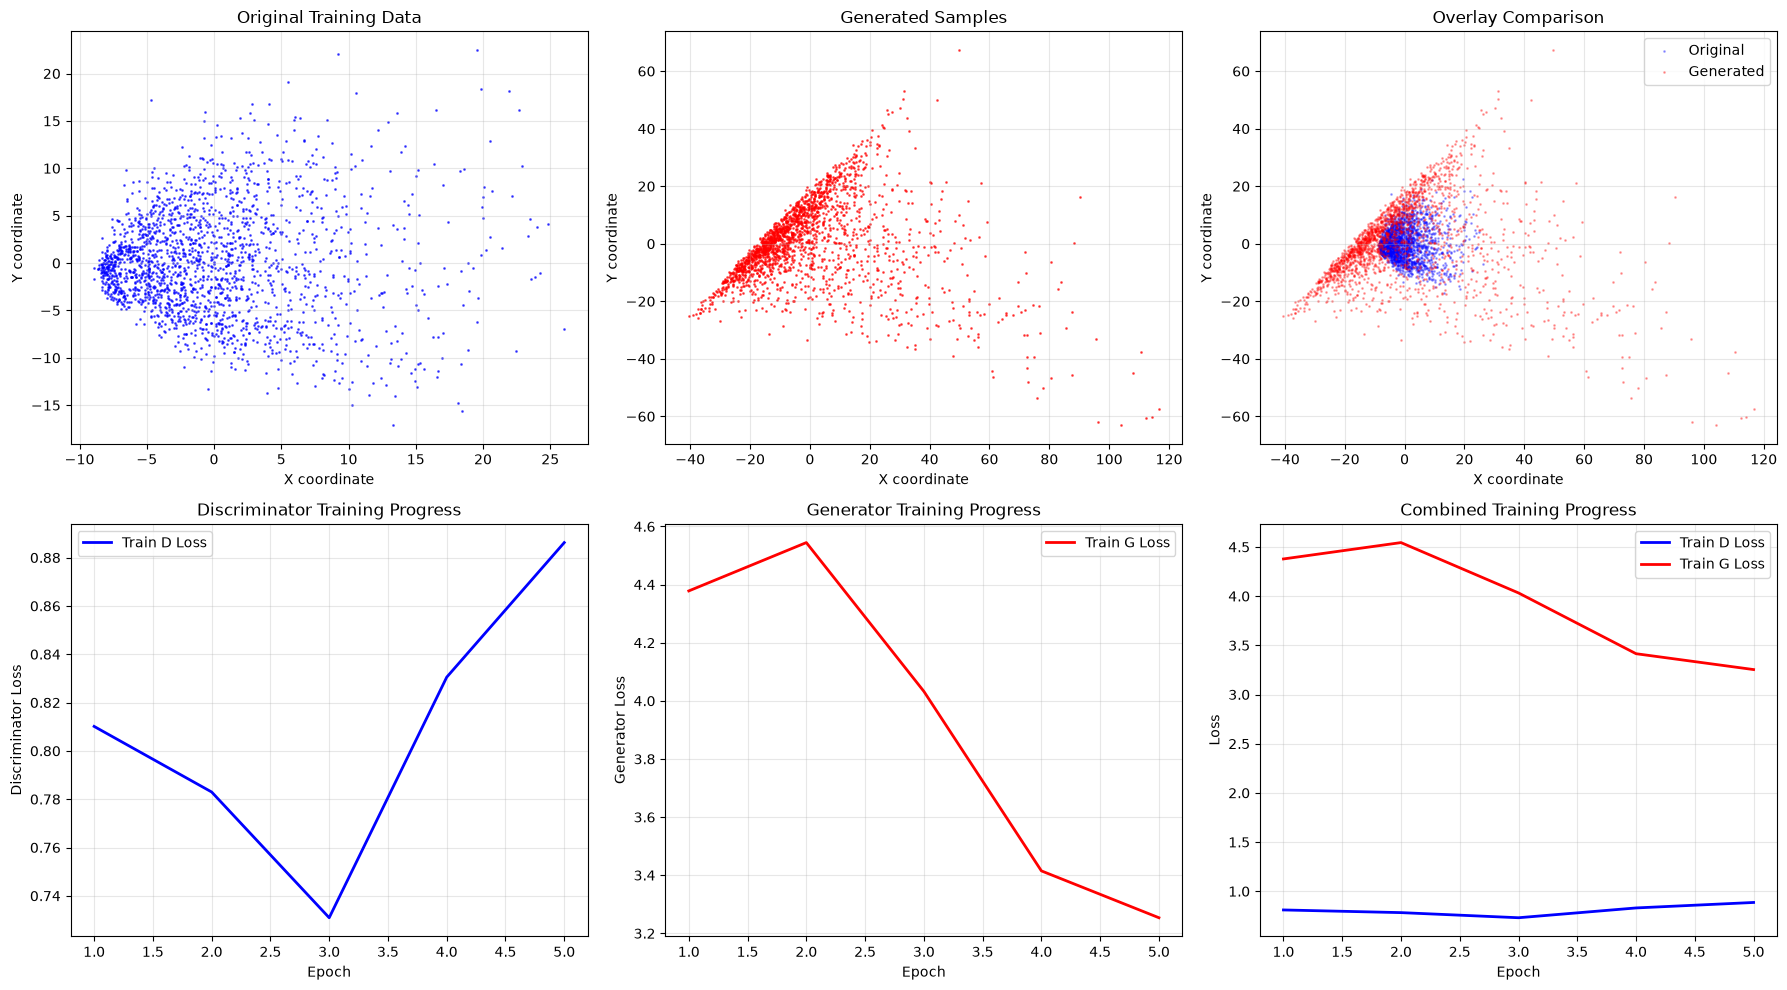

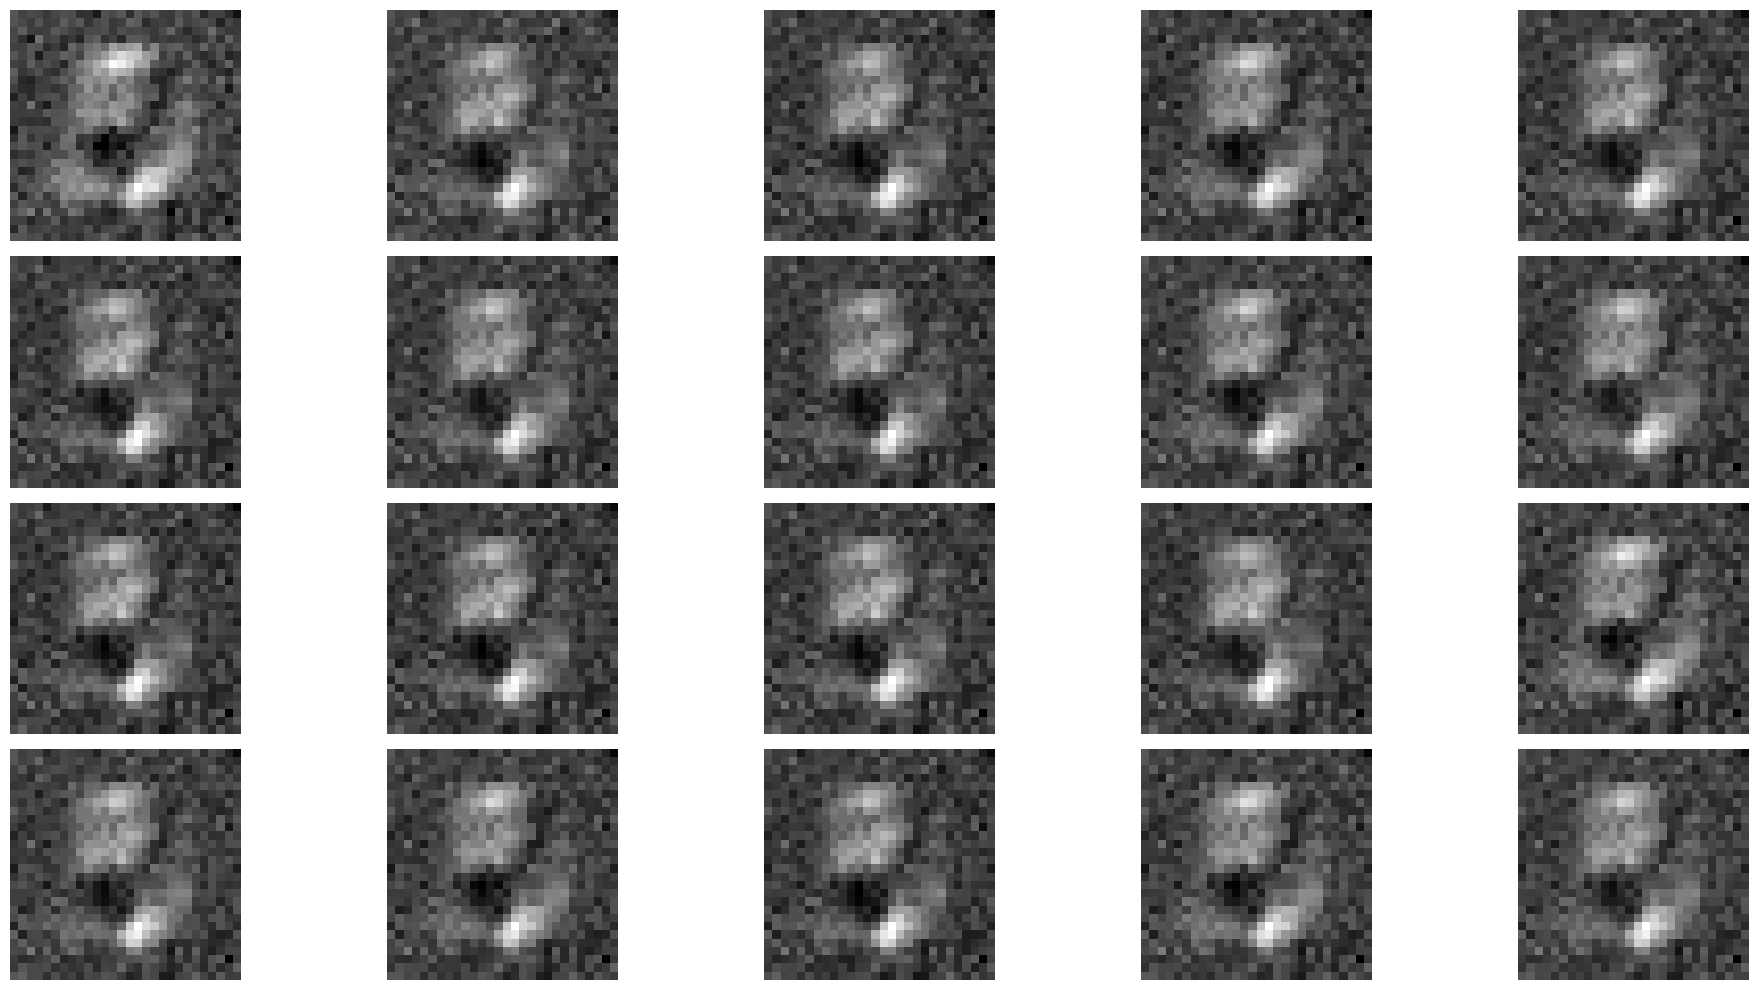

📈 Epoch 5 Summary:
   Train D Loss: 0.8862, Val D Loss: 0.8470
   Train G Loss: 3.2537, Val G Loss: 1.2755

📊 Epoch 6/100
----------------------------------------
Epoch: 6 [0/60000 (0%)]	D_loss: 0.767869	G_loss: 2.799459
Epoch: 6 [6400/60000 (11%)]	D_loss: 0.899638	G_loss: 1.793489
Epoch: 6 [12800/60000 (21%)]	D_loss: 0.907198	G_loss: 4.546548
Epoch: 6 [19200/60000 (32%)]	D_loss: 1.005115	G_loss: 2.705501
Epoch: 6 [25600/60000 (43%)]	D_loss: 0.766163	G_loss: 2.384621
Epoch: 6 [32000/60000 (53%)]	D_loss: 1.061787	G_loss: 3.159920
Epoch: 6 [38400/60000 (64%)]	D_loss: 0.550413	G_loss: 4.000173
Epoch: 6 [44800/60000 (75%)]	D_loss: 0.710044	G_loss: 2.829231
Epoch: 6 [51200/60000 (85%)]	D_loss: 0.892460	G_loss: 4.376076
Epoch: 6 [57600/60000 (96%)]	D_loss: 0.682560	G_loss: 2.220572
====> Epoch: 6 Train D_loss: 0.8881, Train G_loss: 3.2075
====> Epoch: 6 Val D_loss: 0.8620, Val G_loss: 2.4224
📈 Epoch 6 Summary:
   Train D Loss: 0.8881, Val D Loss: 0.8620
   Train G Loss: 3.2075, Val G Loss: 2

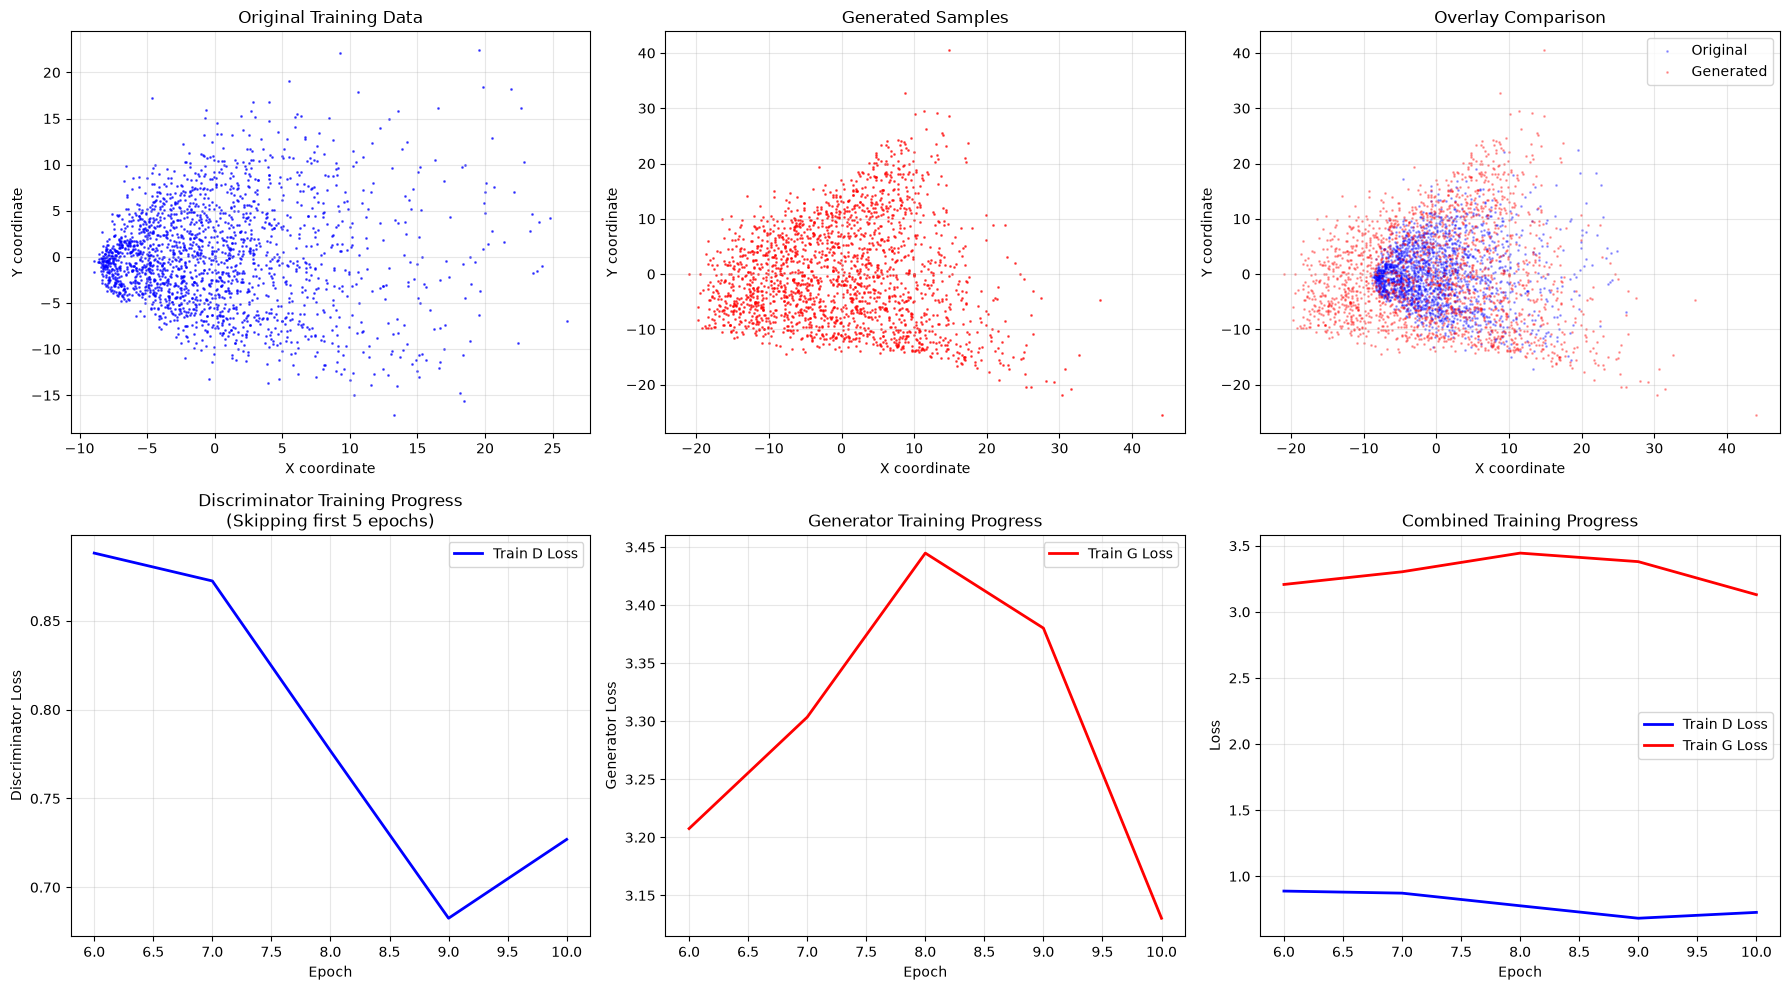

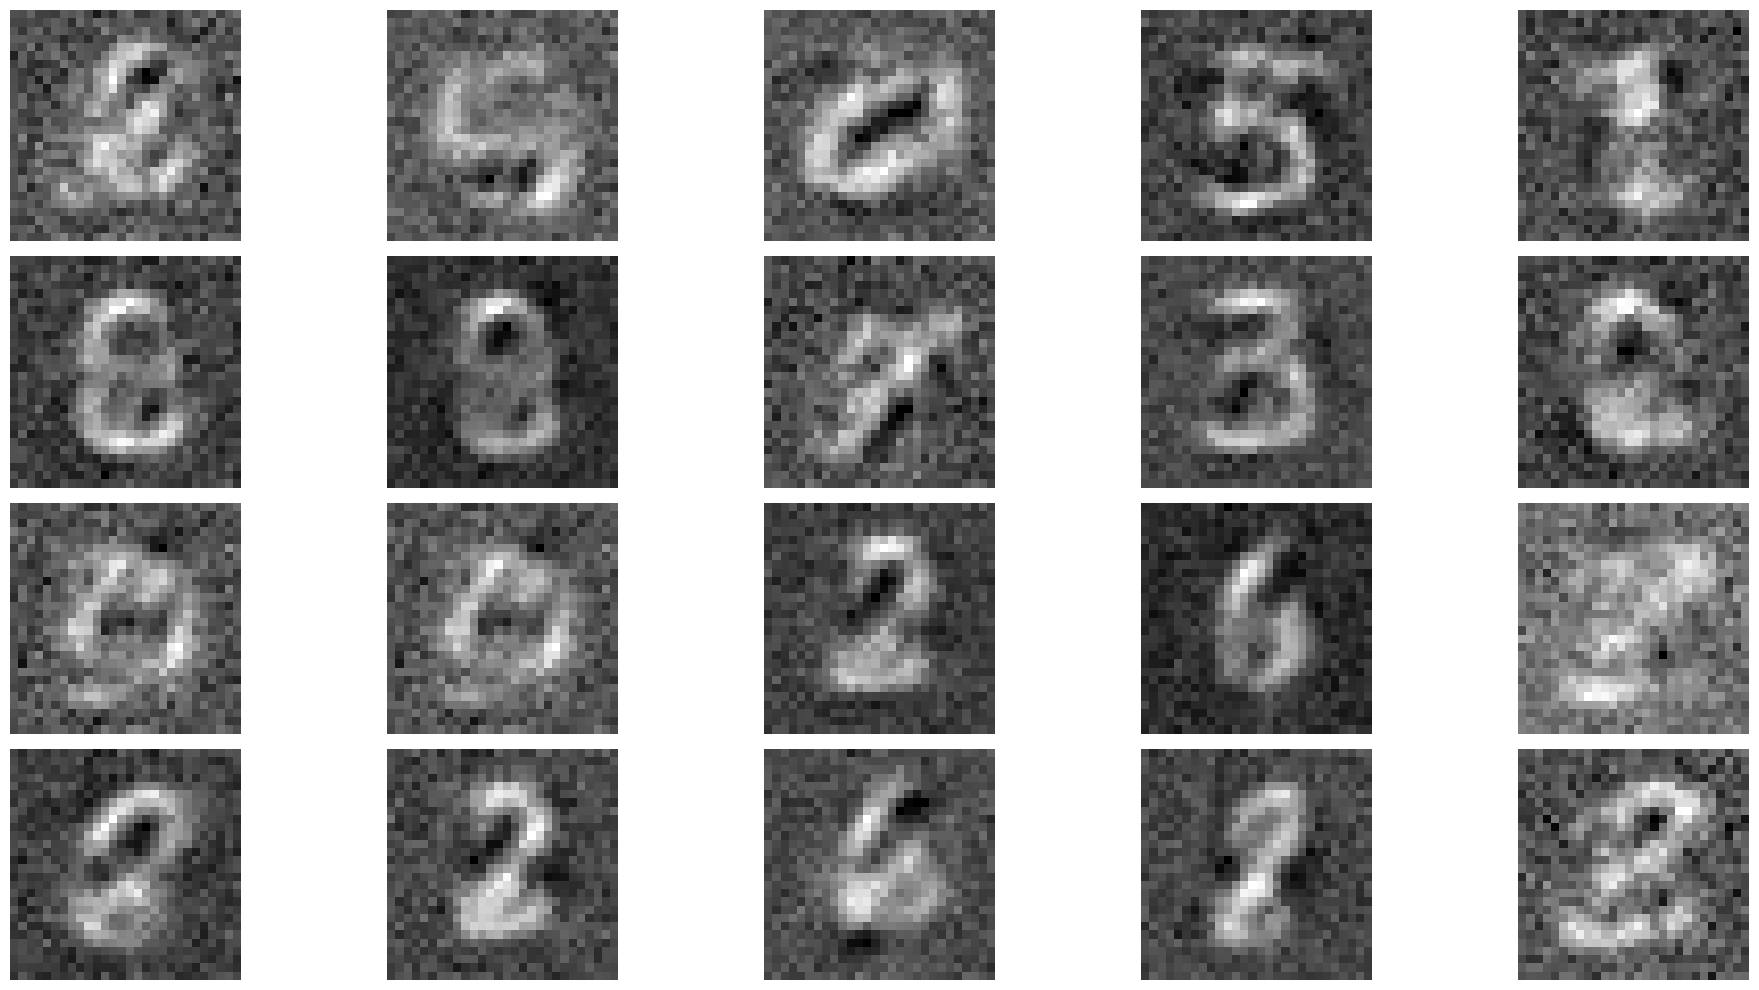

📈 Epoch 10 Summary:
   Train D Loss: 0.7270, Val D Loss: 0.7344
   Train G Loss: 3.1303, Val G Loss: 1.8385

📊 Epoch 11/100
----------------------------------------
Epoch: 11 [0/60000 (0%)]	D_loss: 0.739350	G_loss: 3.465055
Epoch: 11 [6400/60000 (11%)]	D_loss: 0.527385	G_loss: 3.298024
Epoch: 11 [12800/60000 (21%)]	D_loss: 0.562030	G_loss: 3.064875
Epoch: 11 [19200/60000 (32%)]	D_loss: 0.762039	G_loss: 2.977530
Epoch: 11 [25600/60000 (43%)]	D_loss: 0.698541	G_loss: 3.762757
Epoch: 11 [32000/60000 (53%)]	D_loss: 0.602715	G_loss: 2.844178
Epoch: 11 [38400/60000 (64%)]	D_loss: 0.782284	G_loss: 3.868893
Epoch: 11 [44800/60000 (75%)]	D_loss: 0.657281	G_loss: 2.759032
Epoch: 11 [51200/60000 (85%)]	D_loss: 0.633819	G_loss: 3.478292
Epoch: 11 [57600/60000 (96%)]	D_loss: 0.725739	G_loss: 2.475157
====> Epoch: 11 Train D_loss: 0.7156, Train G_loss: 3.0022
====> Epoch: 11 Val D_loss: 0.5602, Val G_loss: 1.9567
📈 Epoch 11 Summary:
   Train D Loss: 0.7156, Val D Loss: 0.5602
   Train G Loss: 3.0022

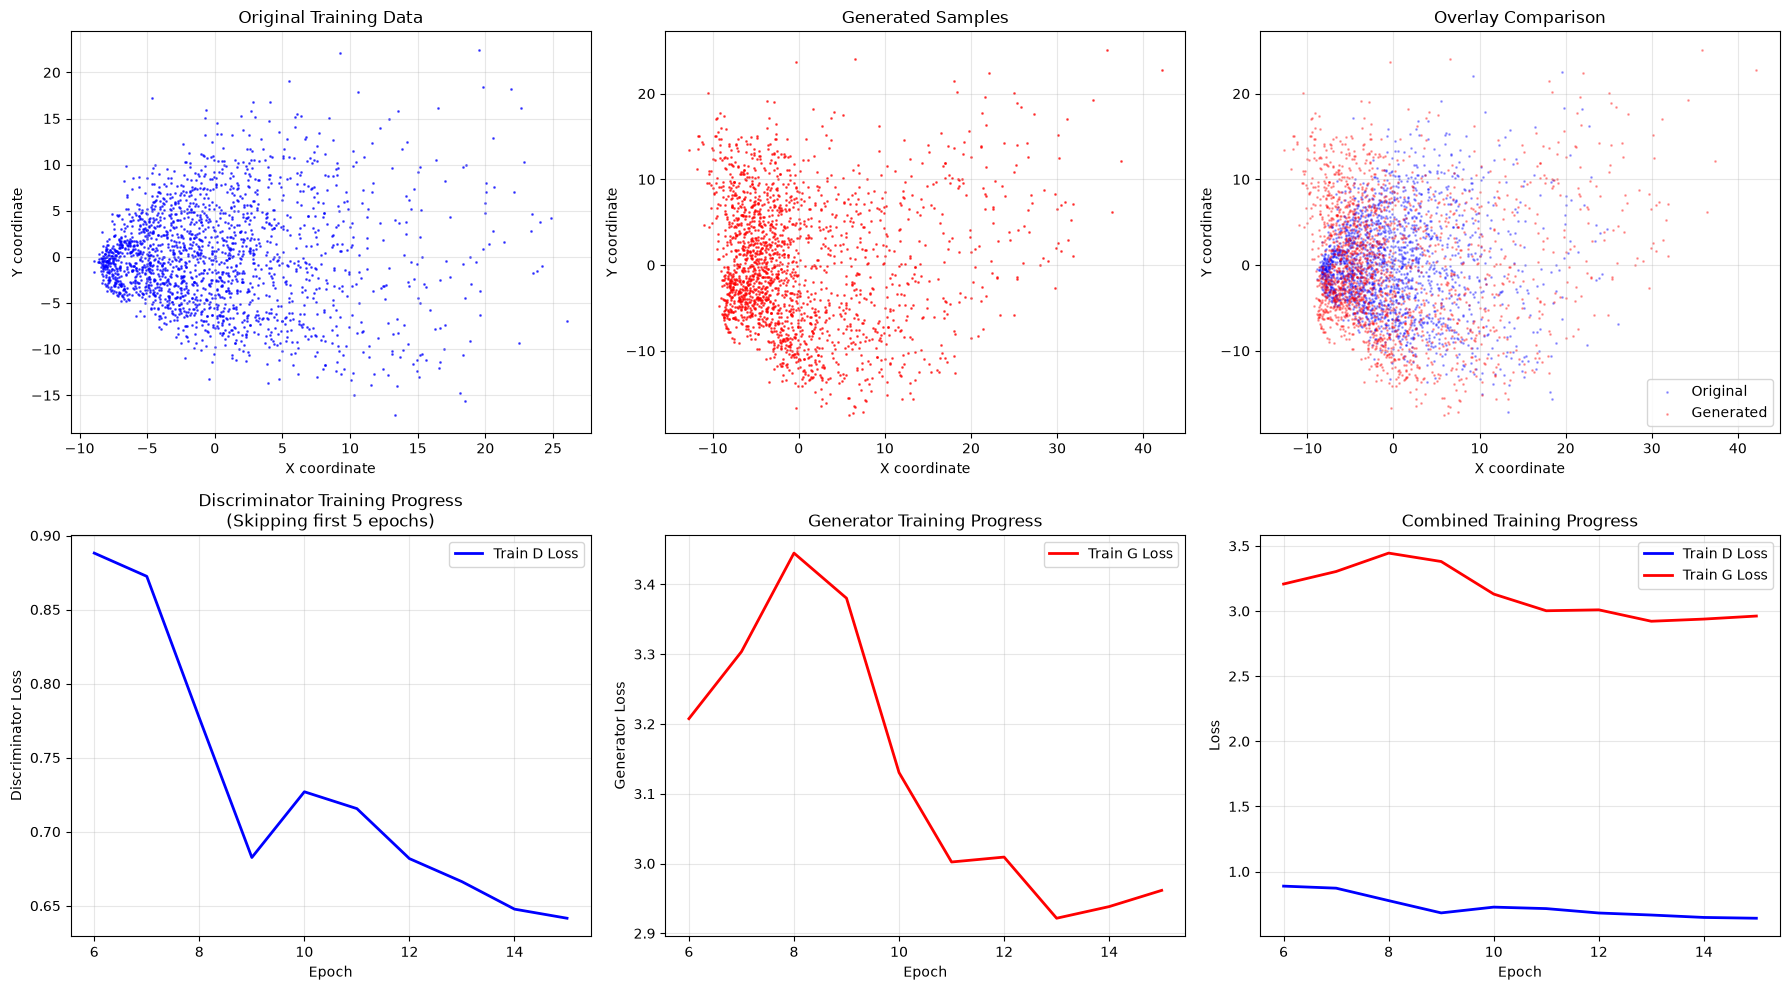

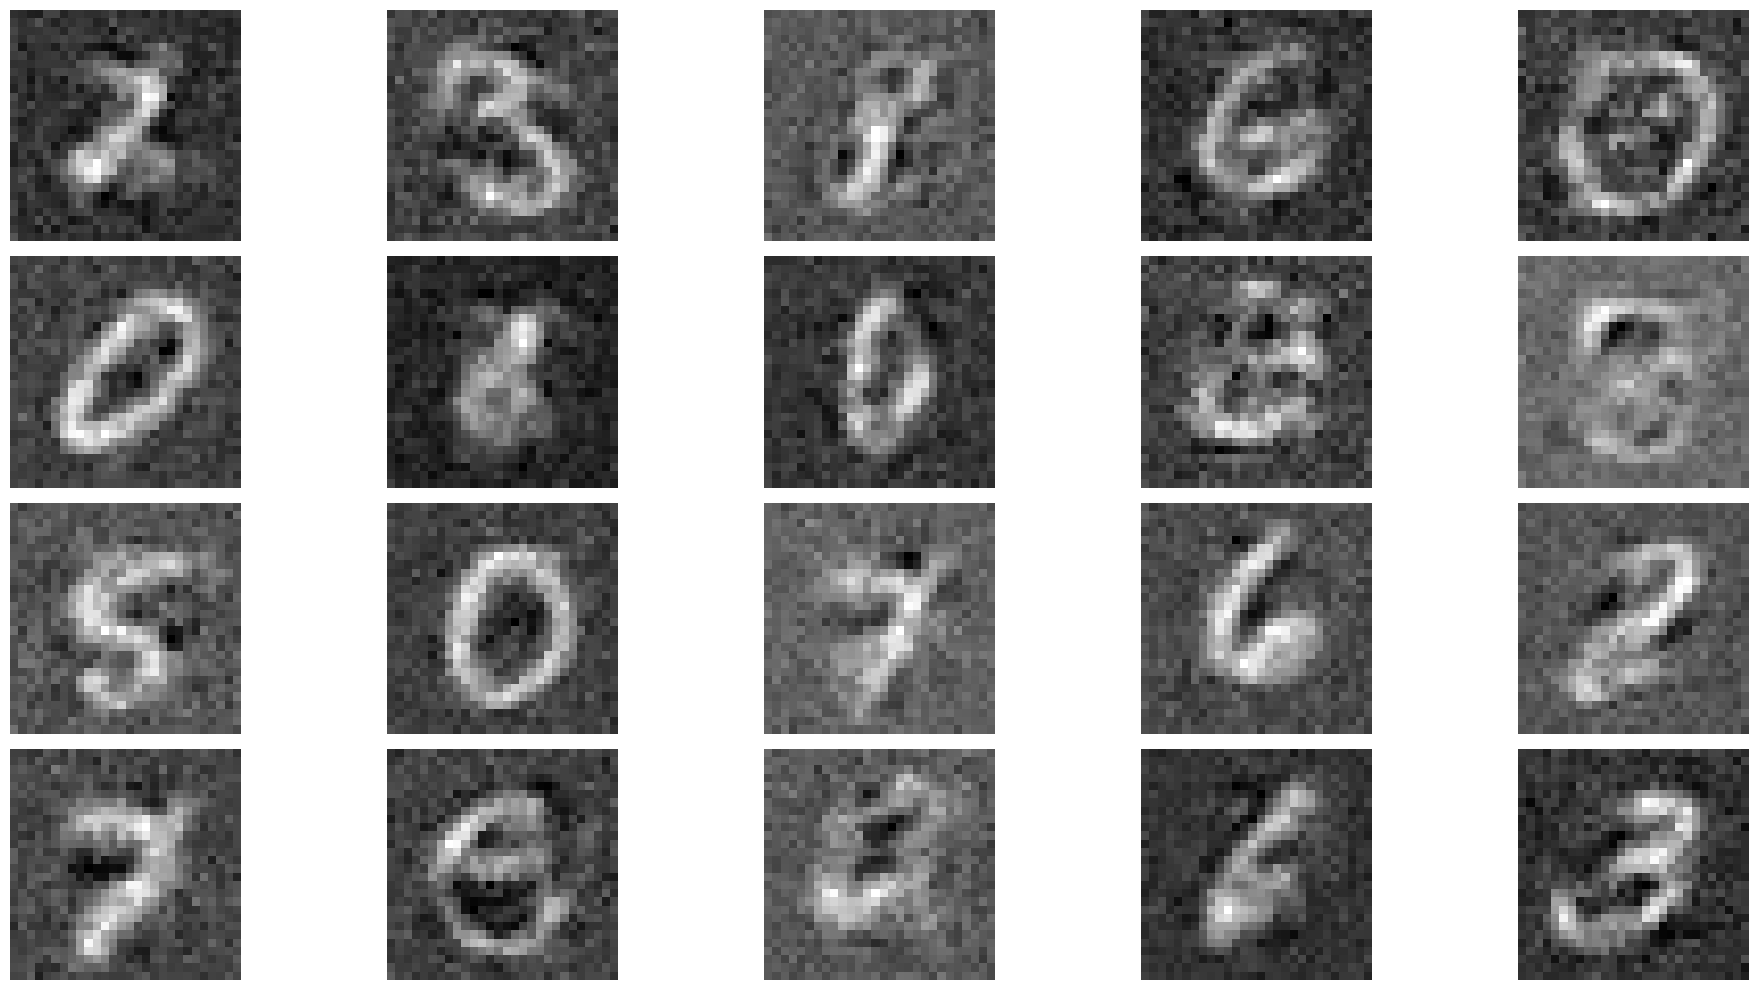

📈 Epoch 15 Summary:
   Train D Loss: 0.6416, Val D Loss: 1.5667
   Train G Loss: 2.9615, Val G Loss: 4.5673

📊 Epoch 16/100
----------------------------------------
Epoch: 16 [0/60000 (0%)]	D_loss: 1.429133	G_loss: 3.321254
Epoch: 16 [6400/60000 (11%)]	D_loss: 0.507824	G_loss: 3.203462
Epoch: 16 [12800/60000 (21%)]	D_loss: 0.583929	G_loss: 2.752409
Epoch: 16 [19200/60000 (32%)]	D_loss: 0.712141	G_loss: 1.748247
Epoch: 16 [25600/60000 (43%)]	D_loss: 0.507943	G_loss: 3.041841
Epoch: 16 [32000/60000 (53%)]	D_loss: 0.752912	G_loss: 3.492944
Epoch: 16 [38400/60000 (64%)]	D_loss: 0.682188	G_loss: 2.424294
Epoch: 16 [44800/60000 (75%)]	D_loss: 0.714671	G_loss: 4.531353
Epoch: 16 [51200/60000 (85%)]	D_loss: 0.607733	G_loss: 2.638104
Epoch: 16 [57600/60000 (96%)]	D_loss: 0.681475	G_loss: 2.178983
====> Epoch: 16 Train D_loss: 0.6317, Train G_loss: 2.9293
====> Epoch: 16 Val D_loss: 0.5480, Val G_loss: 2.5354
📈 Epoch 16 Summary:
   Train D Loss: 0.6317, Val D Loss: 0.5480
   Train G Loss: 2.9293

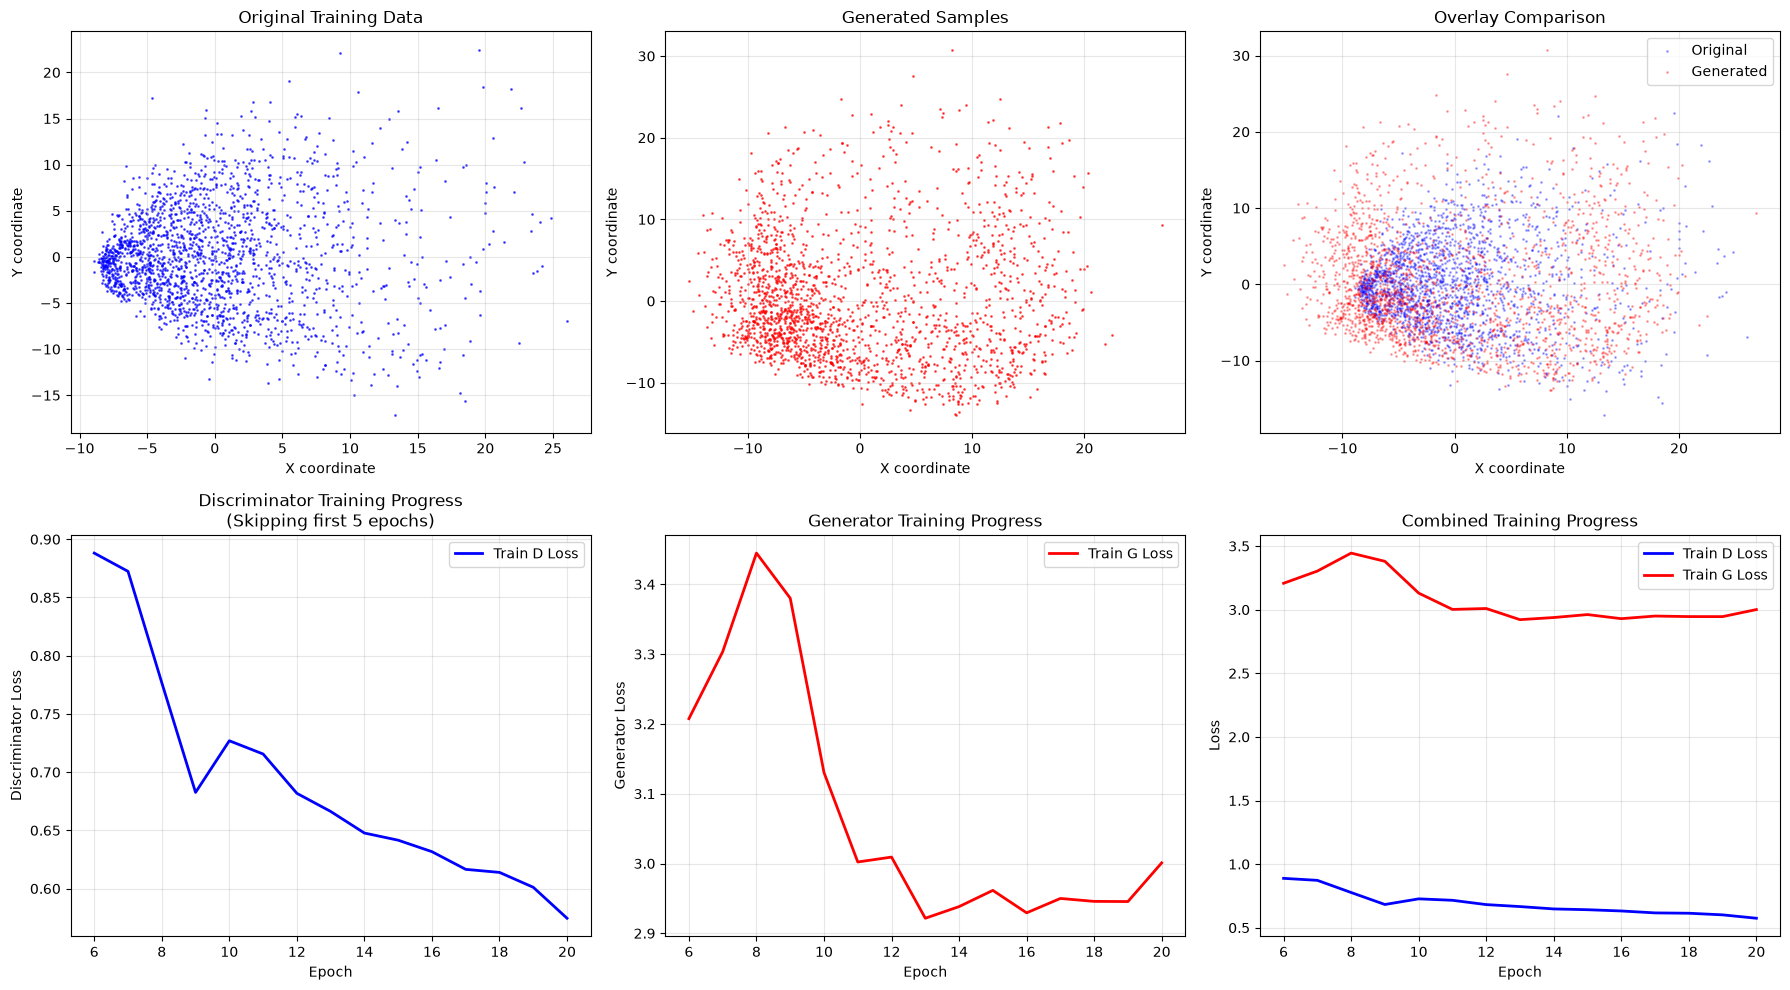

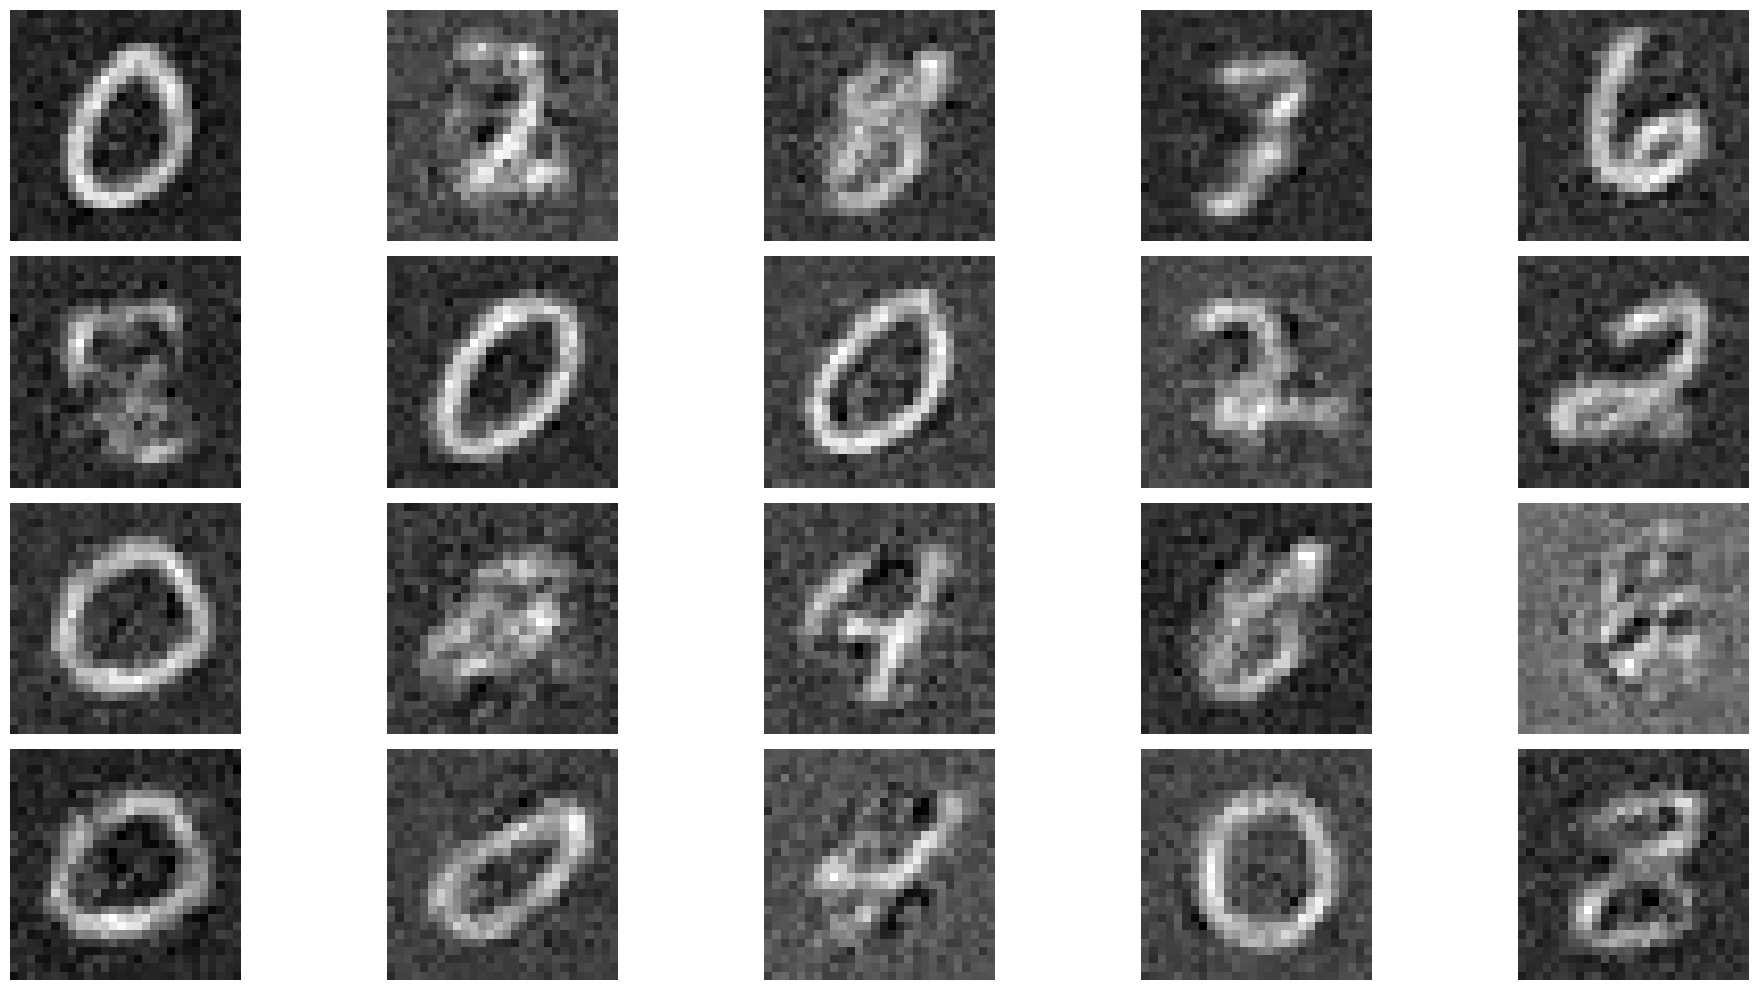

📈 Epoch 20 Summary:
   Train D Loss: 0.5745, Val D Loss: 0.9482
   Train G Loss: 3.0009, Val G Loss: 3.7867

📊 Epoch 21/100
----------------------------------------
Epoch: 21 [0/60000 (0%)]	D_loss: 0.865813	G_loss: 2.999441
Epoch: 21 [6400/60000 (11%)]	D_loss: 0.679304	G_loss: 4.869962
Epoch: 21 [12800/60000 (21%)]	D_loss: 0.661779	G_loss: 1.717728
Epoch: 21 [19200/60000 (32%)]	D_loss: 0.669515	G_loss: 2.645254
Epoch: 21 [25600/60000 (43%)]	D_loss: 0.662650	G_loss: 1.956652
Epoch: 21 [32000/60000 (53%)]	D_loss: 0.431835	G_loss: 2.376035
Epoch: 21 [38400/60000 (64%)]	D_loss: 0.719795	G_loss: 1.889094
Epoch: 21 [44800/60000 (75%)]	D_loss: 0.565480	G_loss: 2.697324
Epoch: 21 [51200/60000 (85%)]	D_loss: 0.524749	G_loss: 3.023668
Epoch: 21 [57600/60000 (96%)]	D_loss: 0.560013	G_loss: 2.448129
====> Epoch: 21 Train D_loss: 0.5602, Train G_loss: 3.0939
====> Epoch: 21 Val D_loss: 0.6998, Val G_loss: 2.8478
📈 Epoch 21 Summary:
   Train D Loss: 0.5602, Val D Loss: 0.6998
   Train G Loss: 3.0939

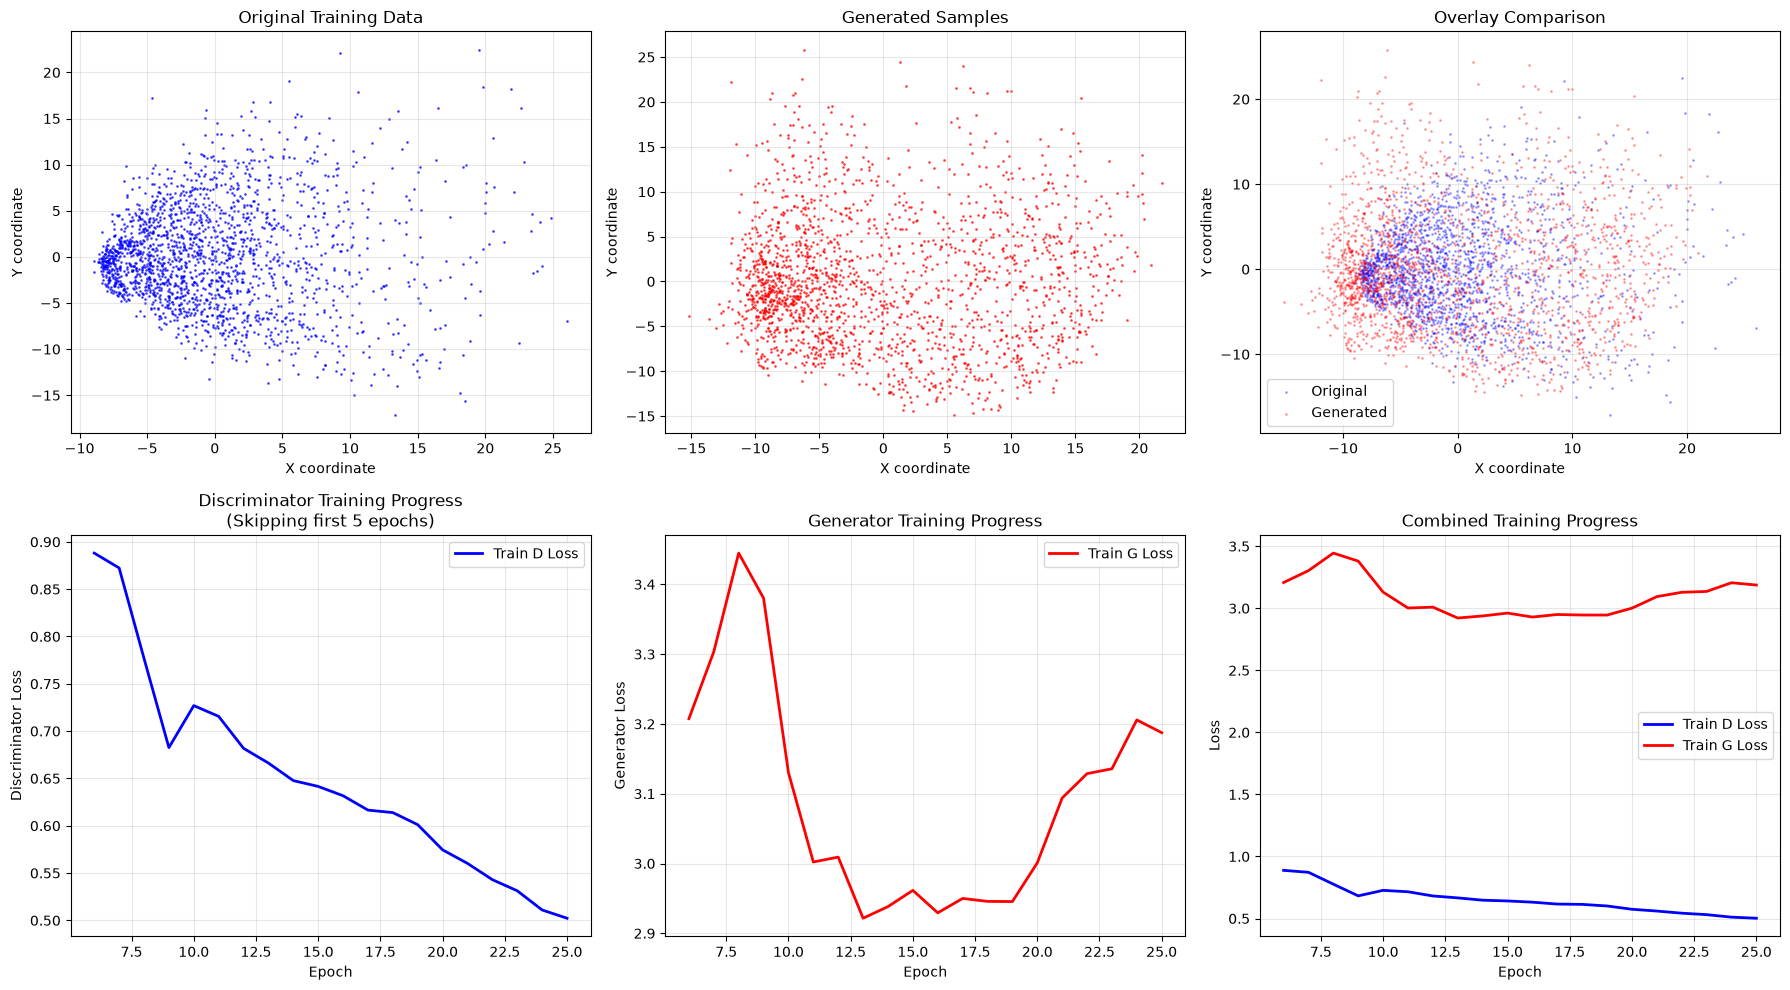

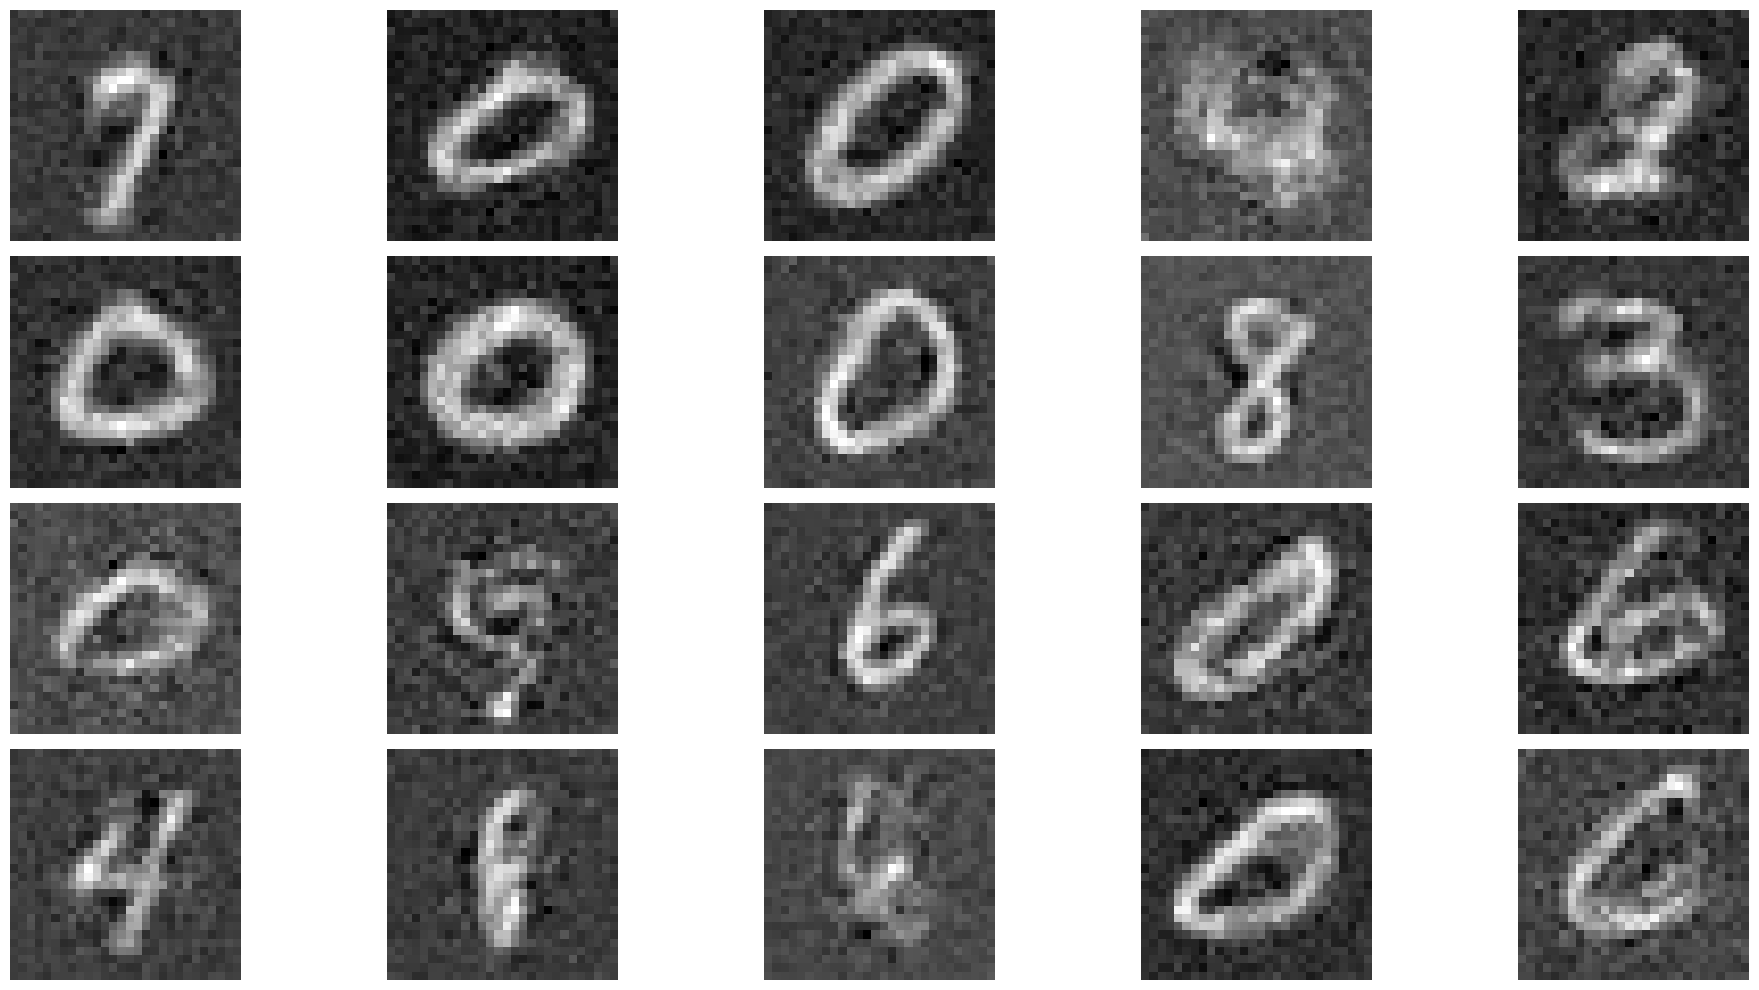

📈 Epoch 25 Summary:
   Train D Loss: 0.5023, Val D Loss: 0.6080
   Train G Loss: 3.1874, Val G Loss: 2.1124

📊 Epoch 26/100
----------------------------------------
Epoch: 26 [0/60000 (0%)]	D_loss: 0.537811	G_loss: 3.736607
Epoch: 26 [6400/60000 (11%)]	D_loss: 0.427089	G_loss: 3.501341
Epoch: 26 [12800/60000 (21%)]	D_loss: 0.421321	G_loss: 3.656336
Epoch: 26 [19200/60000 (32%)]	D_loss: 0.411490	G_loss: 3.542414
Epoch: 26 [25600/60000 (43%)]	D_loss: 0.565825	G_loss: 4.064107
Epoch: 26 [32000/60000 (53%)]	D_loss: 0.429185	G_loss: 2.768156
Epoch: 26 [38400/60000 (64%)]	D_loss: 0.584057	G_loss: 2.801517
Epoch: 26 [44800/60000 (75%)]	D_loss: 0.357743	G_loss: 4.313000
Epoch: 26 [51200/60000 (85%)]	D_loss: 0.403766	G_loss: 3.324264
Epoch: 26 [57600/60000 (96%)]	D_loss: 0.867833	G_loss: 2.944703
====> Epoch: 26 Train D_loss: 0.4933, Train G_loss: 3.2886
====> Epoch: 26 Val D_loss: 0.4076, Val G_loss: 2.4910
📈 Epoch 26 Summary:
   Train D Loss: 0.4933, Val D Loss: 0.4076
   Train G Loss: 3.2886

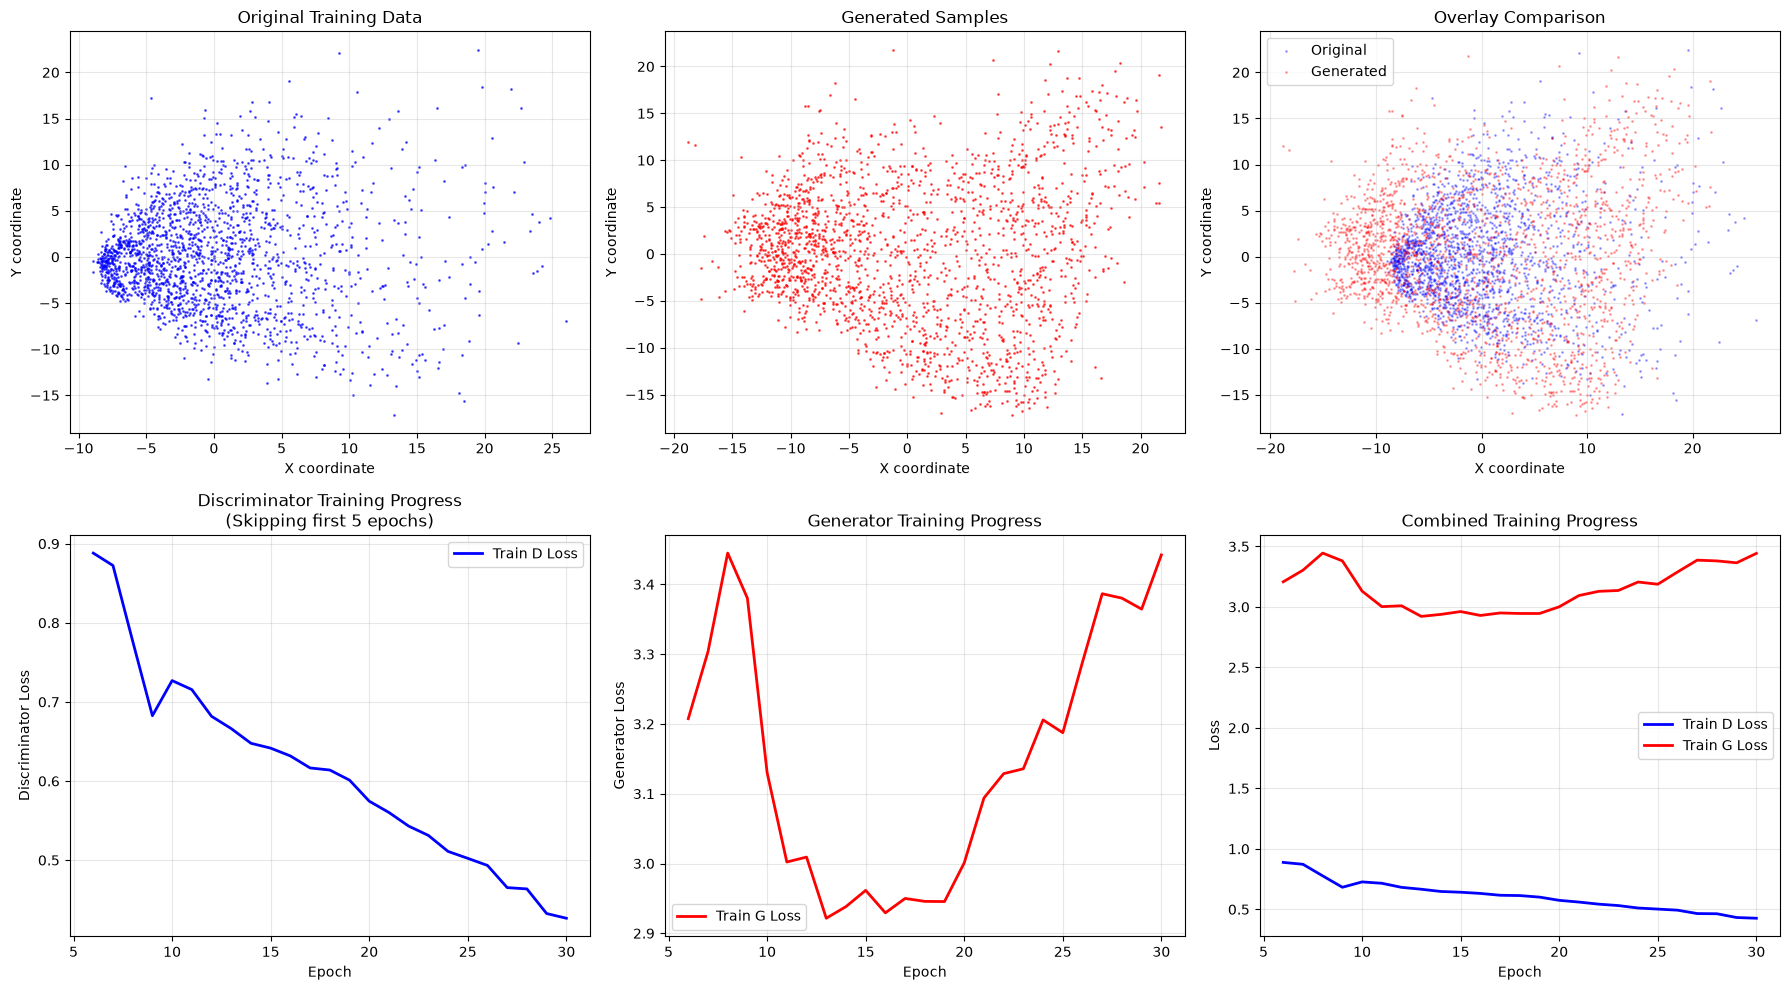

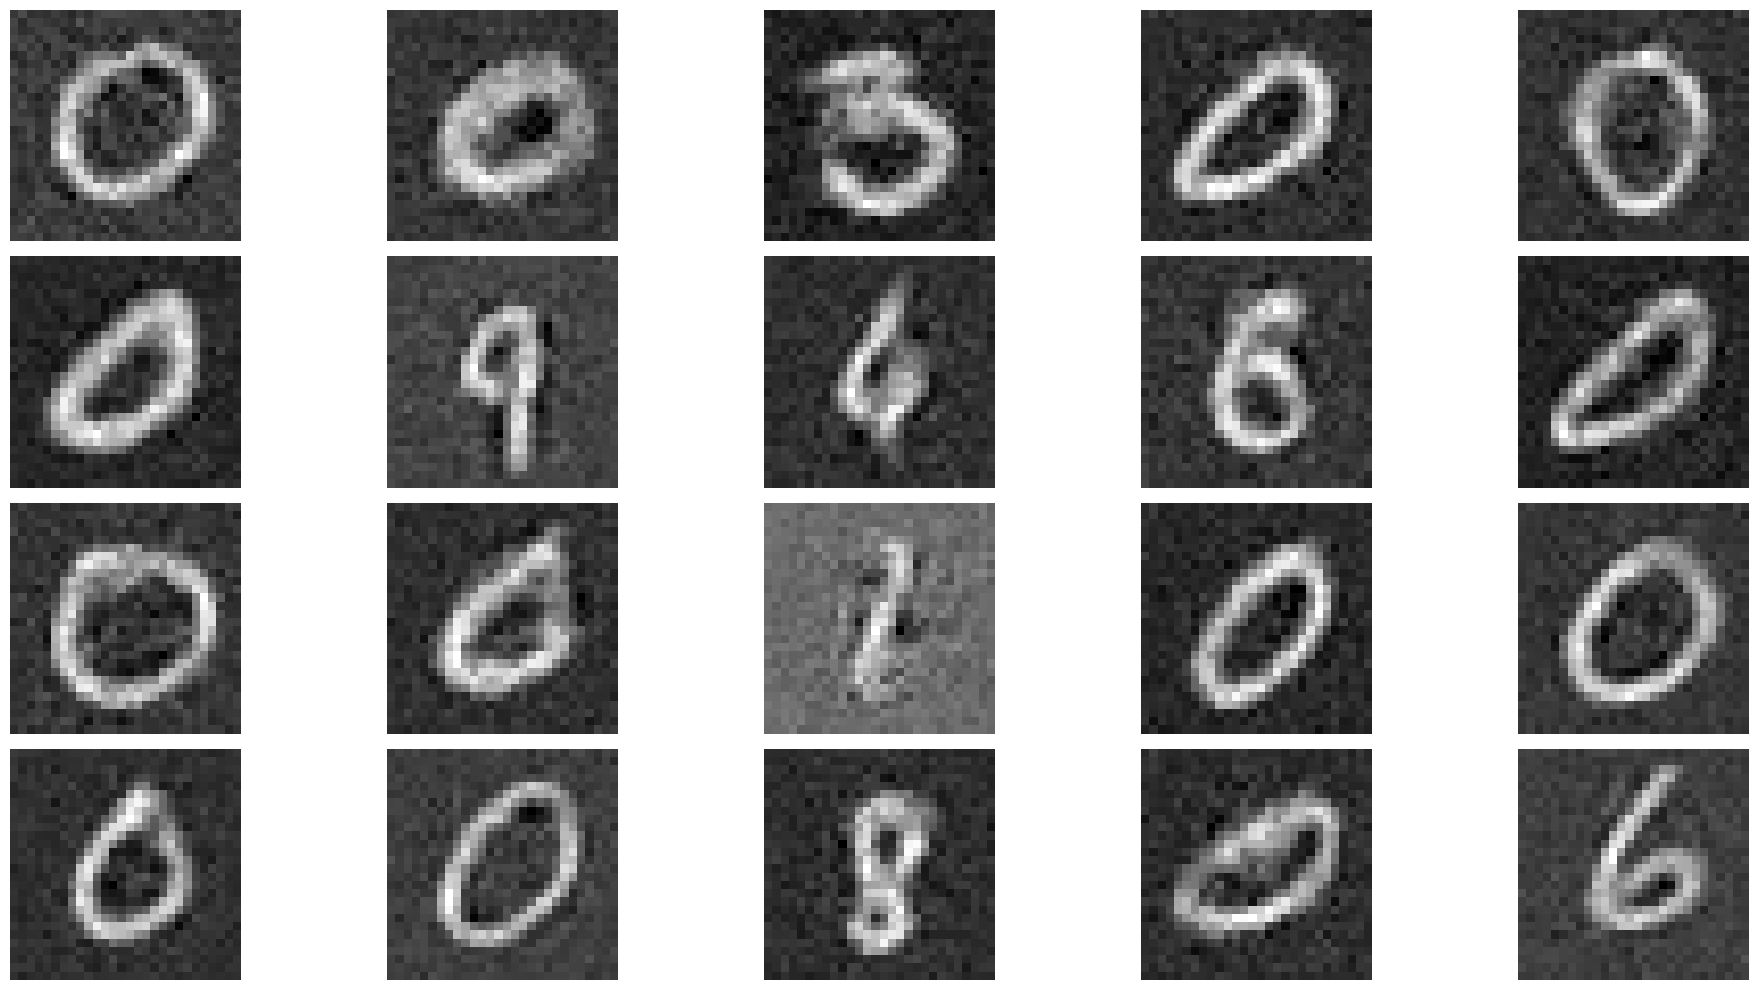

📈 Epoch 30 Summary:
   Train D Loss: 0.4265, Val D Loss: 0.5080
   Train G Loss: 3.4422, Val G Loss: 2.0646

📊 Epoch 31/100
----------------------------------------
Epoch: 31 [0/60000 (0%)]	D_loss: 0.478578	G_loss: 5.764051
Epoch: 31 [6400/60000 (11%)]	D_loss: 0.391682	G_loss: 3.156414
Epoch: 31 [12800/60000 (21%)]	D_loss: 0.358752	G_loss: 2.911931
Epoch: 31 [19200/60000 (32%)]	D_loss: 0.496273	G_loss: 4.845741
Epoch: 31 [25600/60000 (43%)]	D_loss: 0.410916	G_loss: 2.542828
Epoch: 31 [32000/60000 (53%)]	D_loss: 0.345985	G_loss: 3.432738
Epoch: 31 [38400/60000 (64%)]	D_loss: 0.312546	G_loss: 2.811672
Epoch: 31 [44800/60000 (75%)]	D_loss: 0.384631	G_loss: 2.967229
Epoch: 31 [51200/60000 (85%)]	D_loss: 0.568787	G_loss: 4.366840
Epoch: 31 [57600/60000 (96%)]	D_loss: 0.352059	G_loss: 3.909883
====> Epoch: 31 Train D_loss: 0.4266, Train G_loss: 3.4869
====> Epoch: 31 Val D_loss: 0.5327, Val G_loss: 4.0055
📈 Epoch 31 Summary:
   Train D Loss: 0.4266, Val D Loss: 0.5327
   Train G Loss: 3.4869

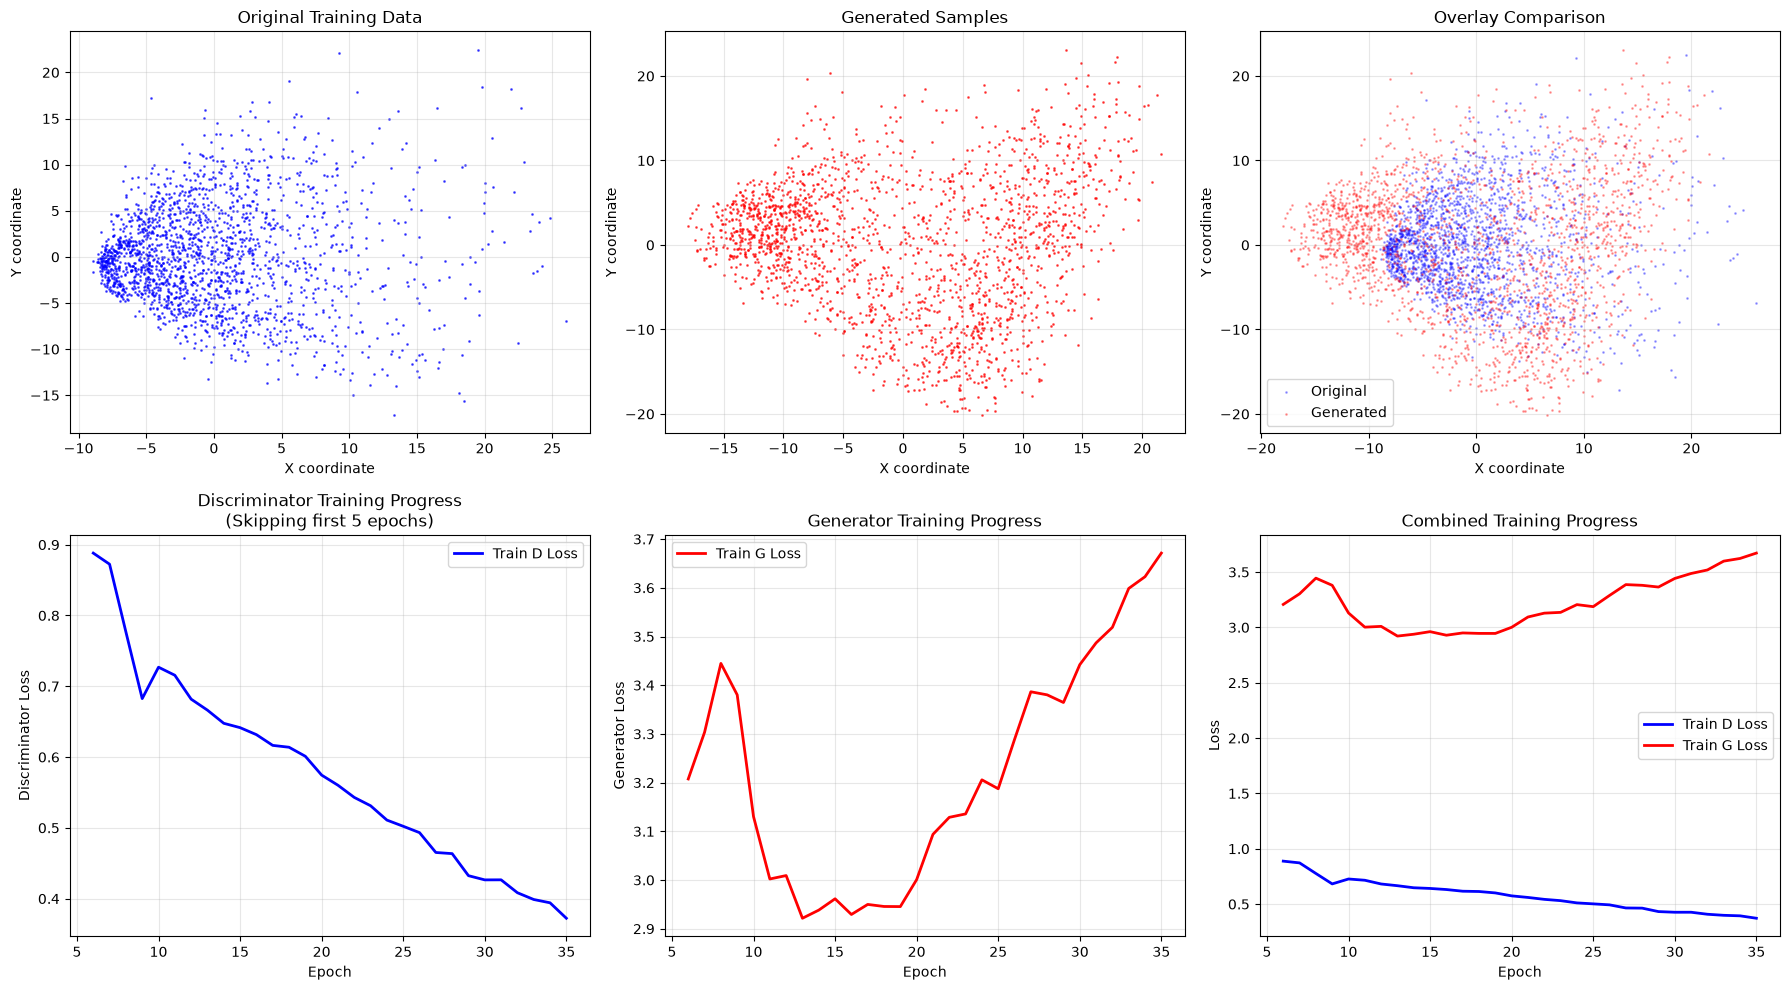

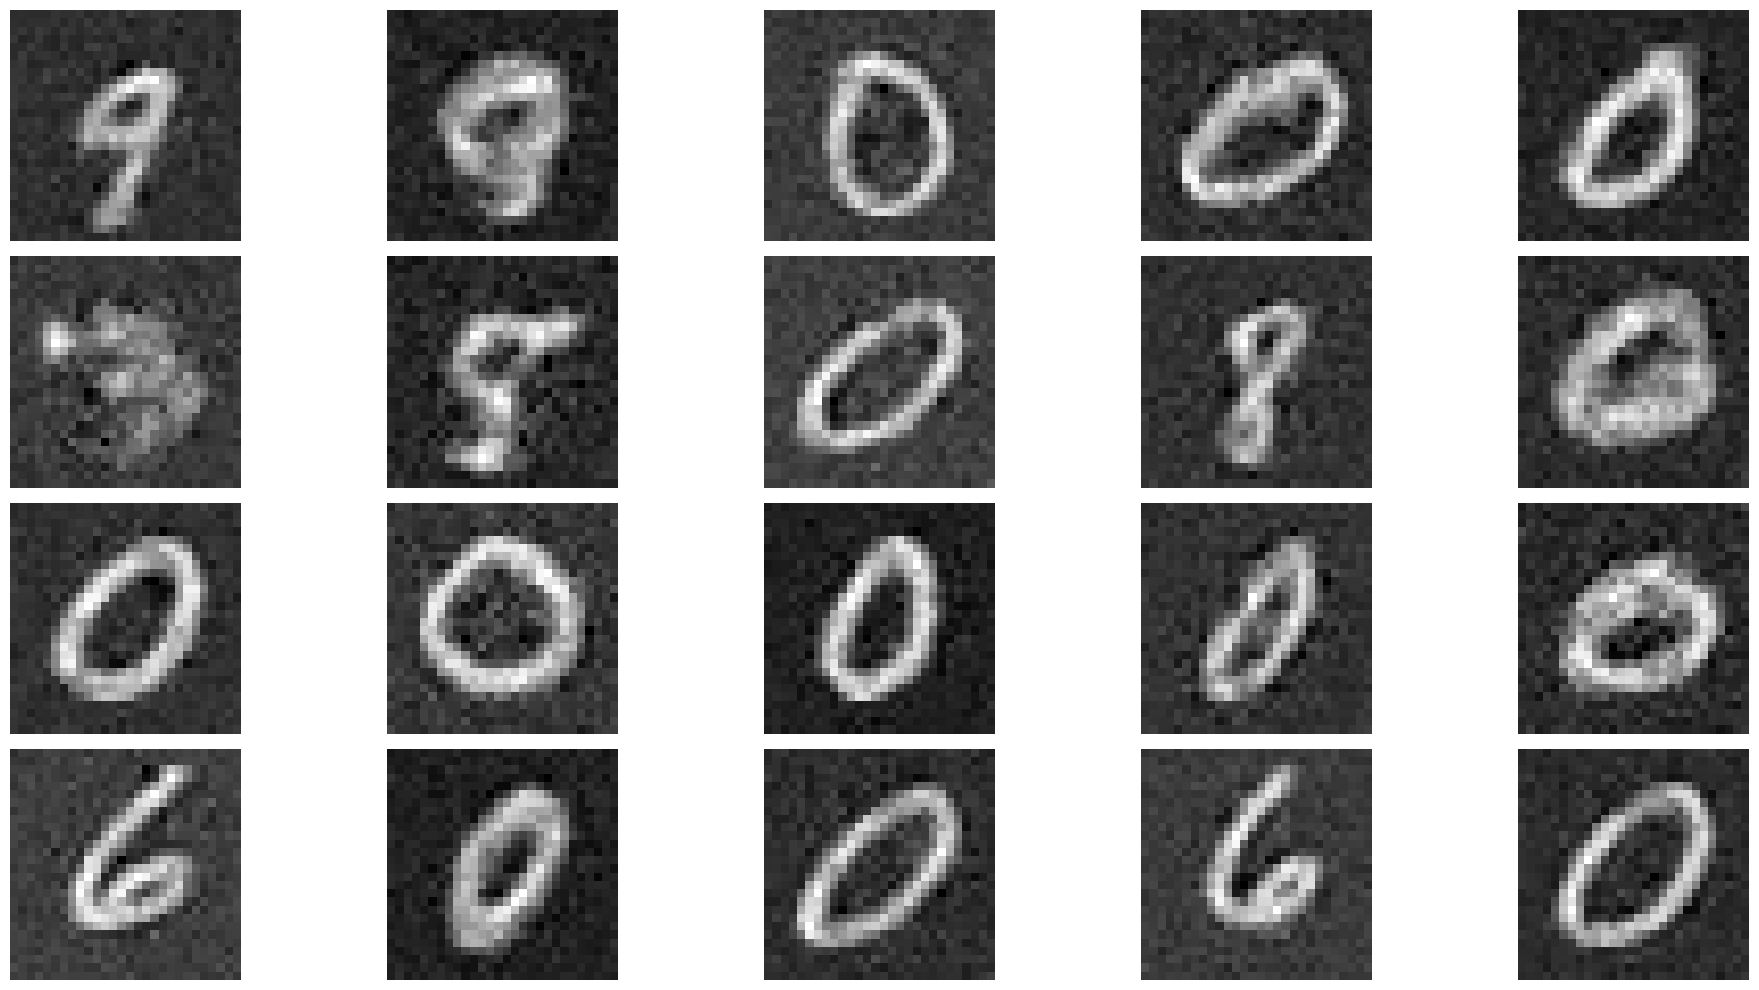

📈 Epoch 35 Summary:
   Train D Loss: 0.3724, Val D Loss: 0.3218
   Train G Loss: 3.6713, Val G Loss: 2.5907

📊 Epoch 36/100
----------------------------------------
Epoch: 36 [0/60000 (0%)]	D_loss: 0.260401	G_loss: 4.116657
Epoch: 36 [6400/60000 (11%)]	D_loss: 0.322988	G_loss: 3.222976
Epoch: 36 [12800/60000 (21%)]	D_loss: 0.317262	G_loss: 3.326424
Epoch: 36 [19200/60000 (32%)]	D_loss: 0.290036	G_loss: 3.807213
Epoch: 36 [25600/60000 (43%)]	D_loss: 0.285882	G_loss: 4.117865
Epoch: 36 [32000/60000 (53%)]	D_loss: 0.355098	G_loss: 3.596348
Epoch: 36 [38400/60000 (64%)]	D_loss: 0.409002	G_loss: 4.155680
Epoch: 36 [44800/60000 (75%)]	D_loss: 0.347318	G_loss: 4.292866
Epoch: 36 [51200/60000 (85%)]	D_loss: 0.286419	G_loss: 3.635117
Epoch: 36 [57600/60000 (96%)]	D_loss: 0.446469	G_loss: 3.882262
====> Epoch: 36 Train D_loss: 0.3801, Train G_loss: 3.7195
====> Epoch: 36 Val D_loss: 0.6107, Val G_loss: 2.1064
📈 Epoch 36 Summary:
   Train D Loss: 0.3801, Val D Loss: 0.6107
   Train G Loss: 3.7195

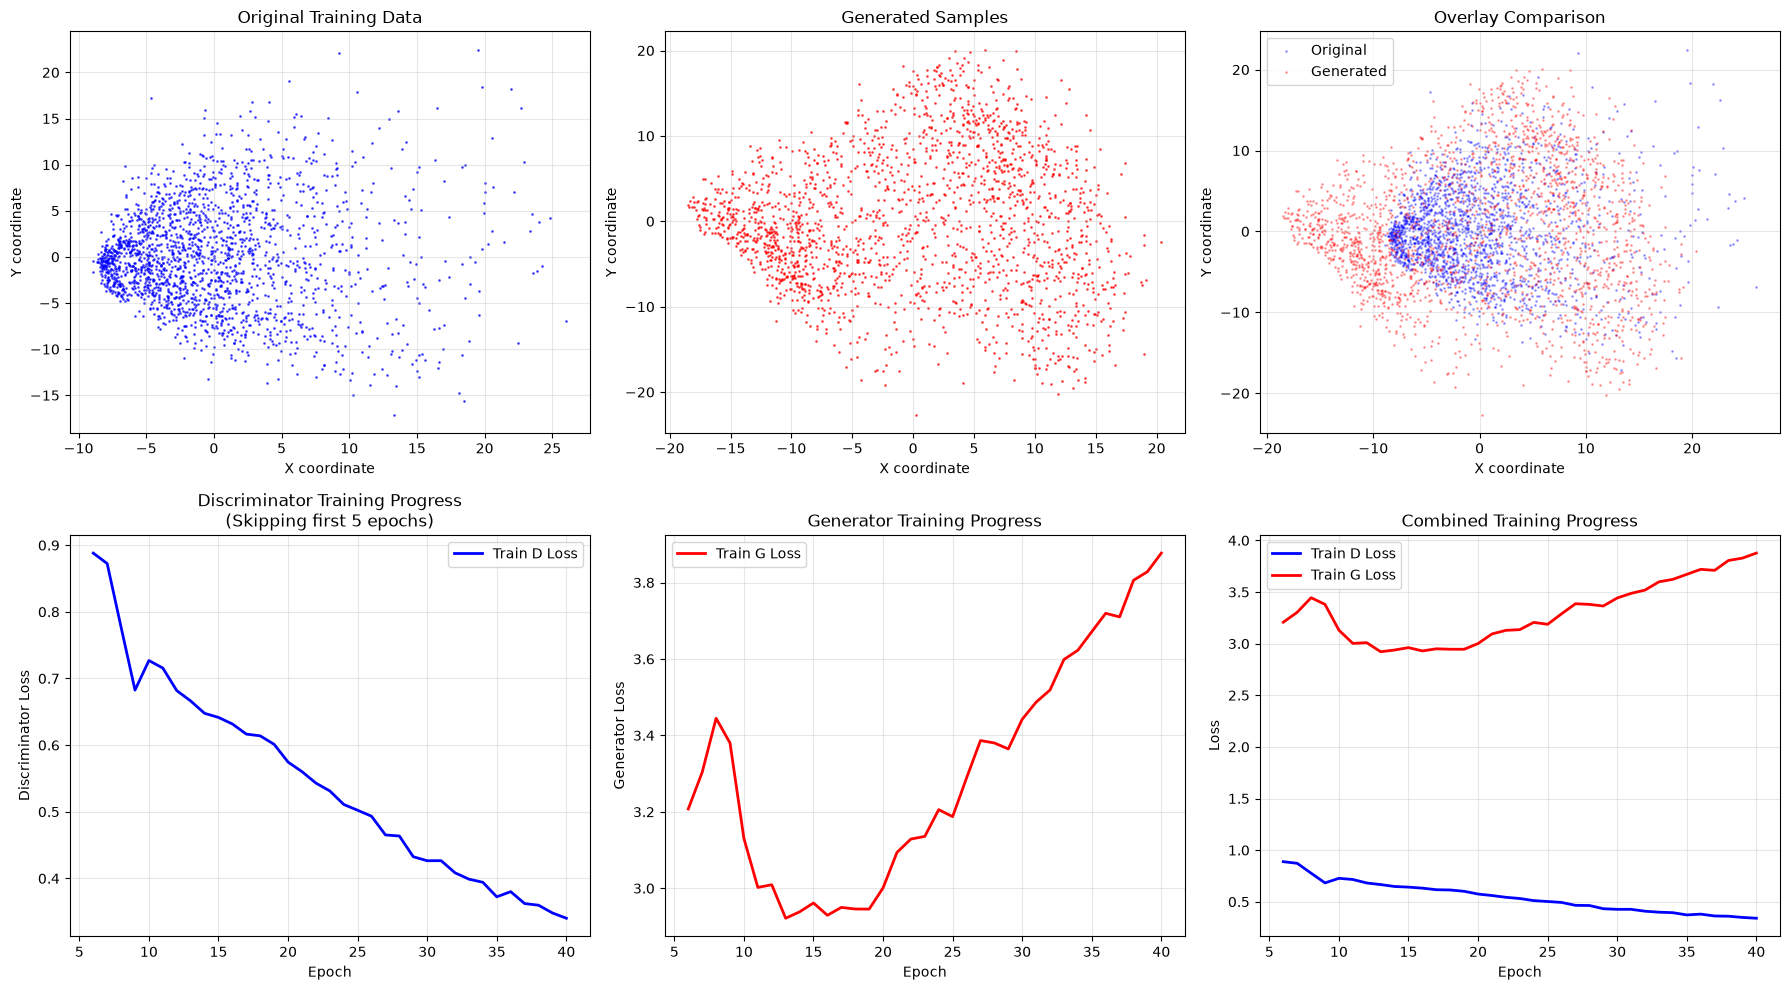

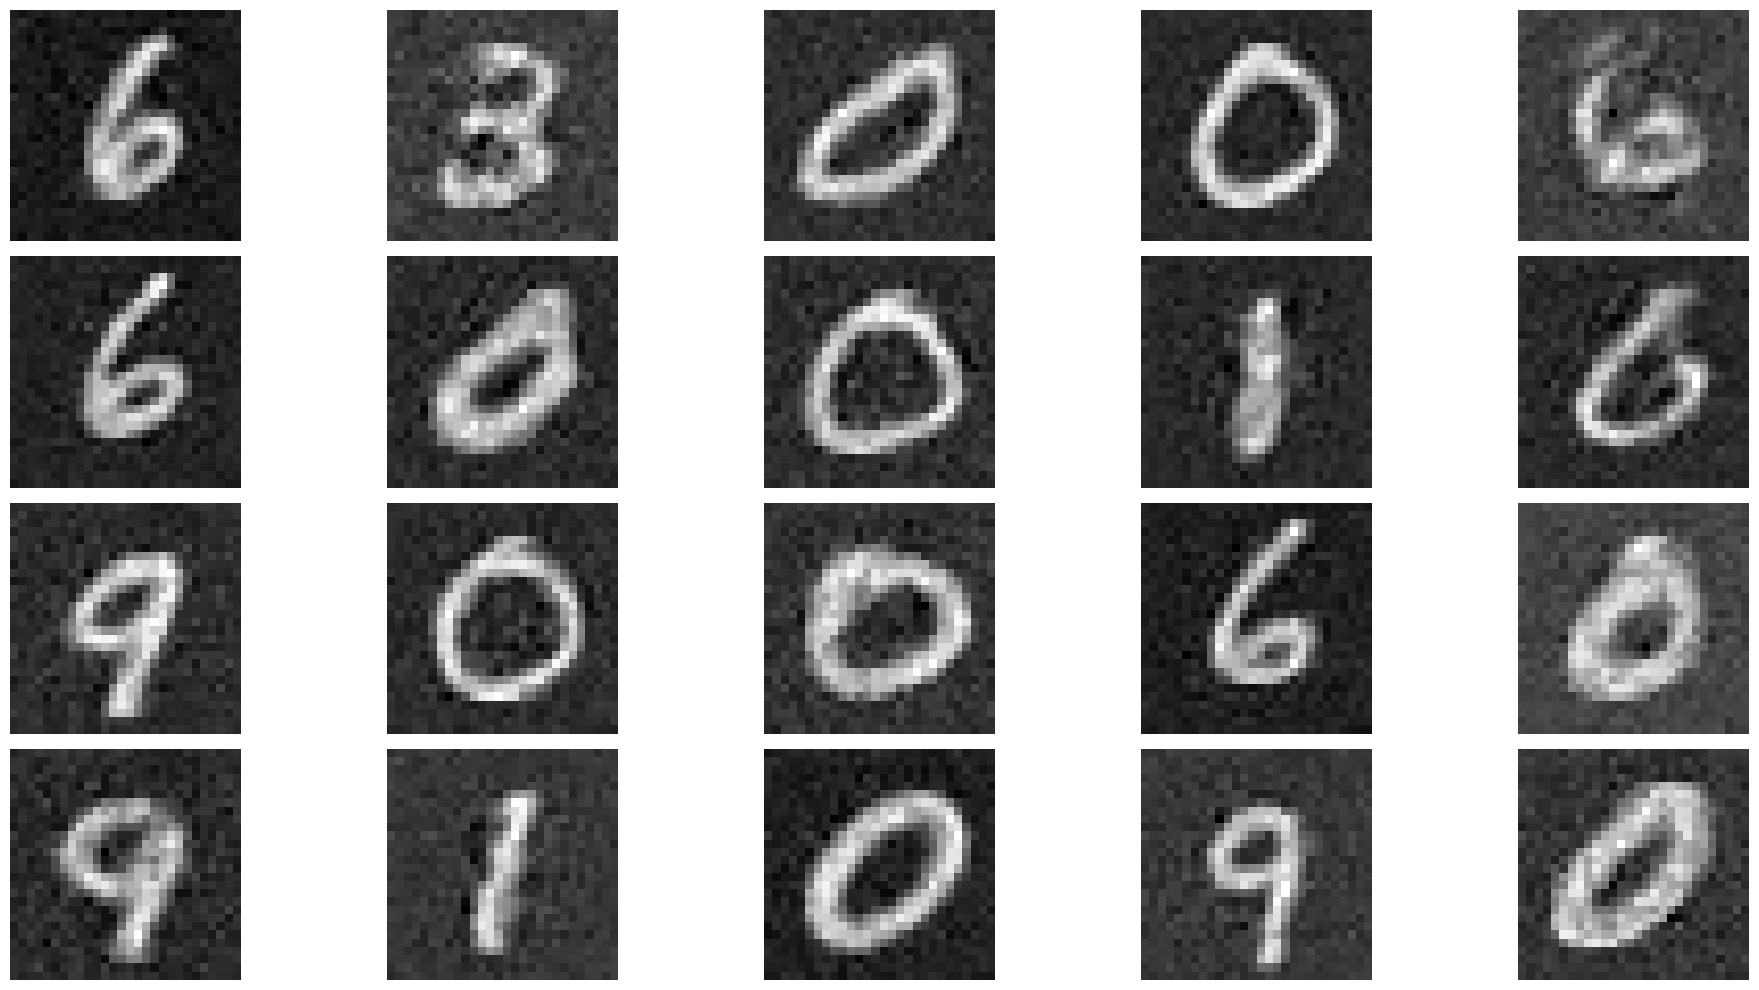

📈 Epoch 40 Summary:
   Train D Loss: 0.3402, Val D Loss: 0.3155
   Train G Loss: 3.8770, Val G Loss: 3.1078

📊 Epoch 41/100
----------------------------------------
Epoch: 41 [0/60000 (0%)]	D_loss: 0.290388	G_loss: 3.377026
Epoch: 41 [6400/60000 (11%)]	D_loss: 0.603406	G_loss: 3.207580
Epoch: 41 [12800/60000 (21%)]	D_loss: 0.200820	G_loss: 4.320821
Epoch: 41 [19200/60000 (32%)]	D_loss: 0.244491	G_loss: 4.315308
Epoch: 41 [25600/60000 (43%)]	D_loss: 0.379009	G_loss: 5.165863
Epoch: 41 [32000/60000 (53%)]	D_loss: 0.240447	G_loss: 3.615474
Epoch: 41 [38400/60000 (64%)]	D_loss: 0.309063	G_loss: 5.107614
Epoch: 41 [44800/60000 (75%)]	D_loss: 0.338133	G_loss: 2.813668
Epoch: 41 [51200/60000 (85%)]	D_loss: 0.415187	G_loss: 3.331056
Epoch: 41 [57600/60000 (96%)]	D_loss: 0.236388	G_loss: 3.539748
====> Epoch: 41 Train D_loss: 0.3350, Train G_loss: 3.9268
====> Epoch: 41 Val D_loss: 0.3869, Val G_loss: 2.3673
📈 Epoch 41 Summary:
   Train D Loss: 0.3350, Val D Loss: 0.3869
   Train G Loss: 3.9268

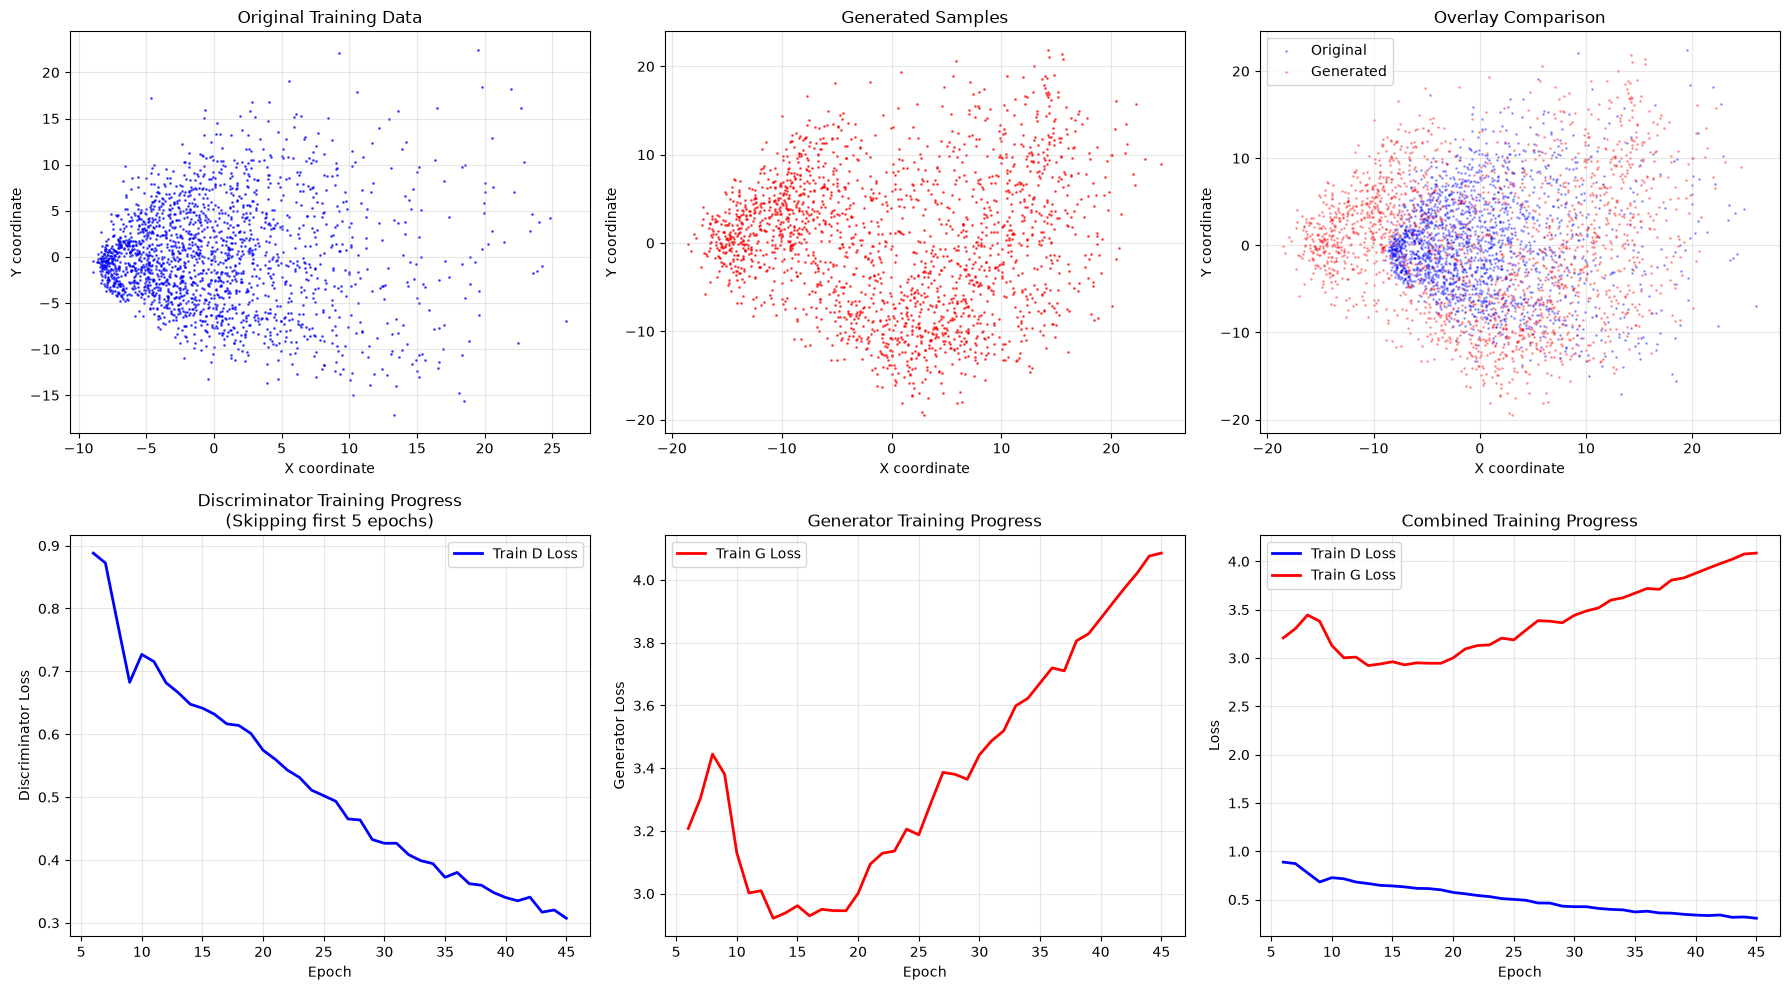

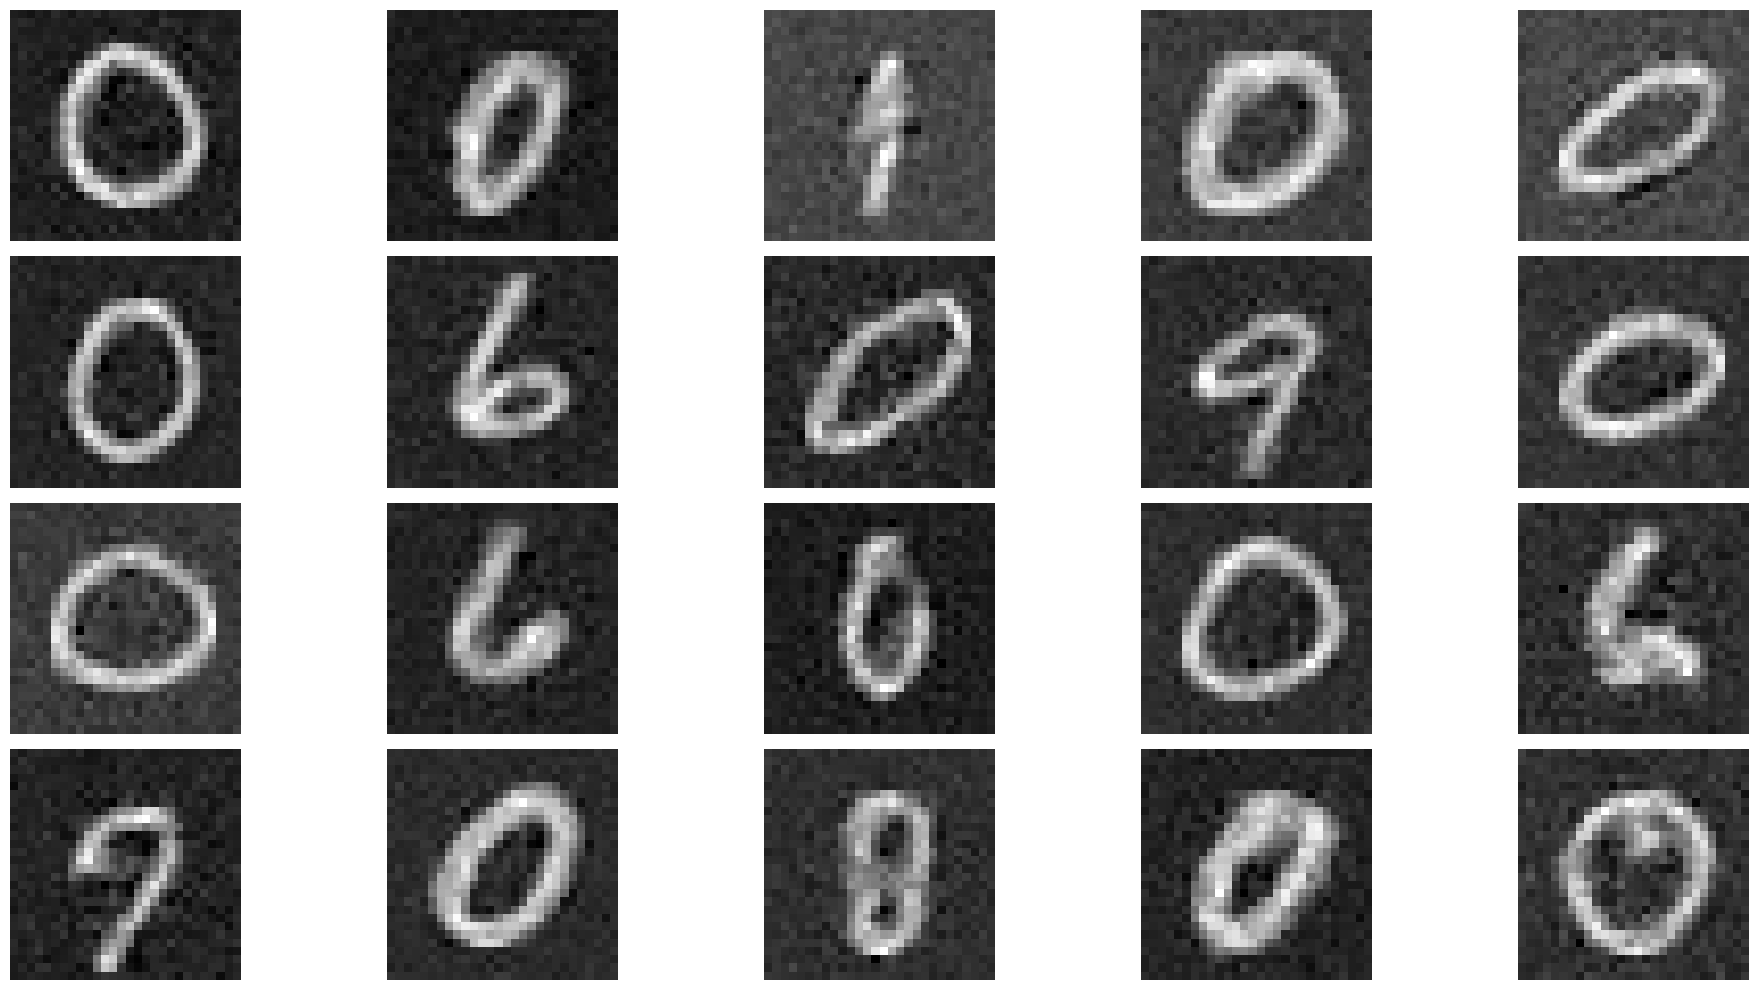

📈 Epoch 45 Summary:
   Train D Loss: 0.3073, Val D Loss: 0.2832
   Train G Loss: 4.0855, Val G Loss: 3.8055

📊 Epoch 46/100
----------------------------------------
Epoch: 46 [0/60000 (0%)]	D_loss: 0.200081	G_loss: 3.961066
Epoch: 46 [6400/60000 (11%)]	D_loss: 0.257412	G_loss: 4.027152
Epoch: 46 [12800/60000 (21%)]	D_loss: 0.429679	G_loss: 2.459148
Epoch: 46 [19200/60000 (32%)]	D_loss: 0.452630	G_loss: 6.813407
Epoch: 46 [25600/60000 (43%)]	D_loss: 0.320618	G_loss: 5.864066
Epoch: 46 [32000/60000 (53%)]	D_loss: 0.338963	G_loss: 2.841009
Epoch: 46 [38400/60000 (64%)]	D_loss: 0.247253	G_loss: 3.525259
Epoch: 46 [44800/60000 (75%)]	D_loss: 0.347124	G_loss: 3.422731
Epoch: 46 [51200/60000 (85%)]	D_loss: 0.341618	G_loss: 3.519058
Epoch: 46 [57600/60000 (96%)]	D_loss: 0.307839	G_loss: 3.247767
====> Epoch: 46 Train D_loss: 0.3311, Train G_loss: 4.0850
====> Epoch: 46 Val D_loss: 0.4661, Val G_loss: 2.4705
📈 Epoch 46 Summary:
   Train D Loss: 0.3311, Val D Loss: 0.4661
   Train G Loss: 4.0850

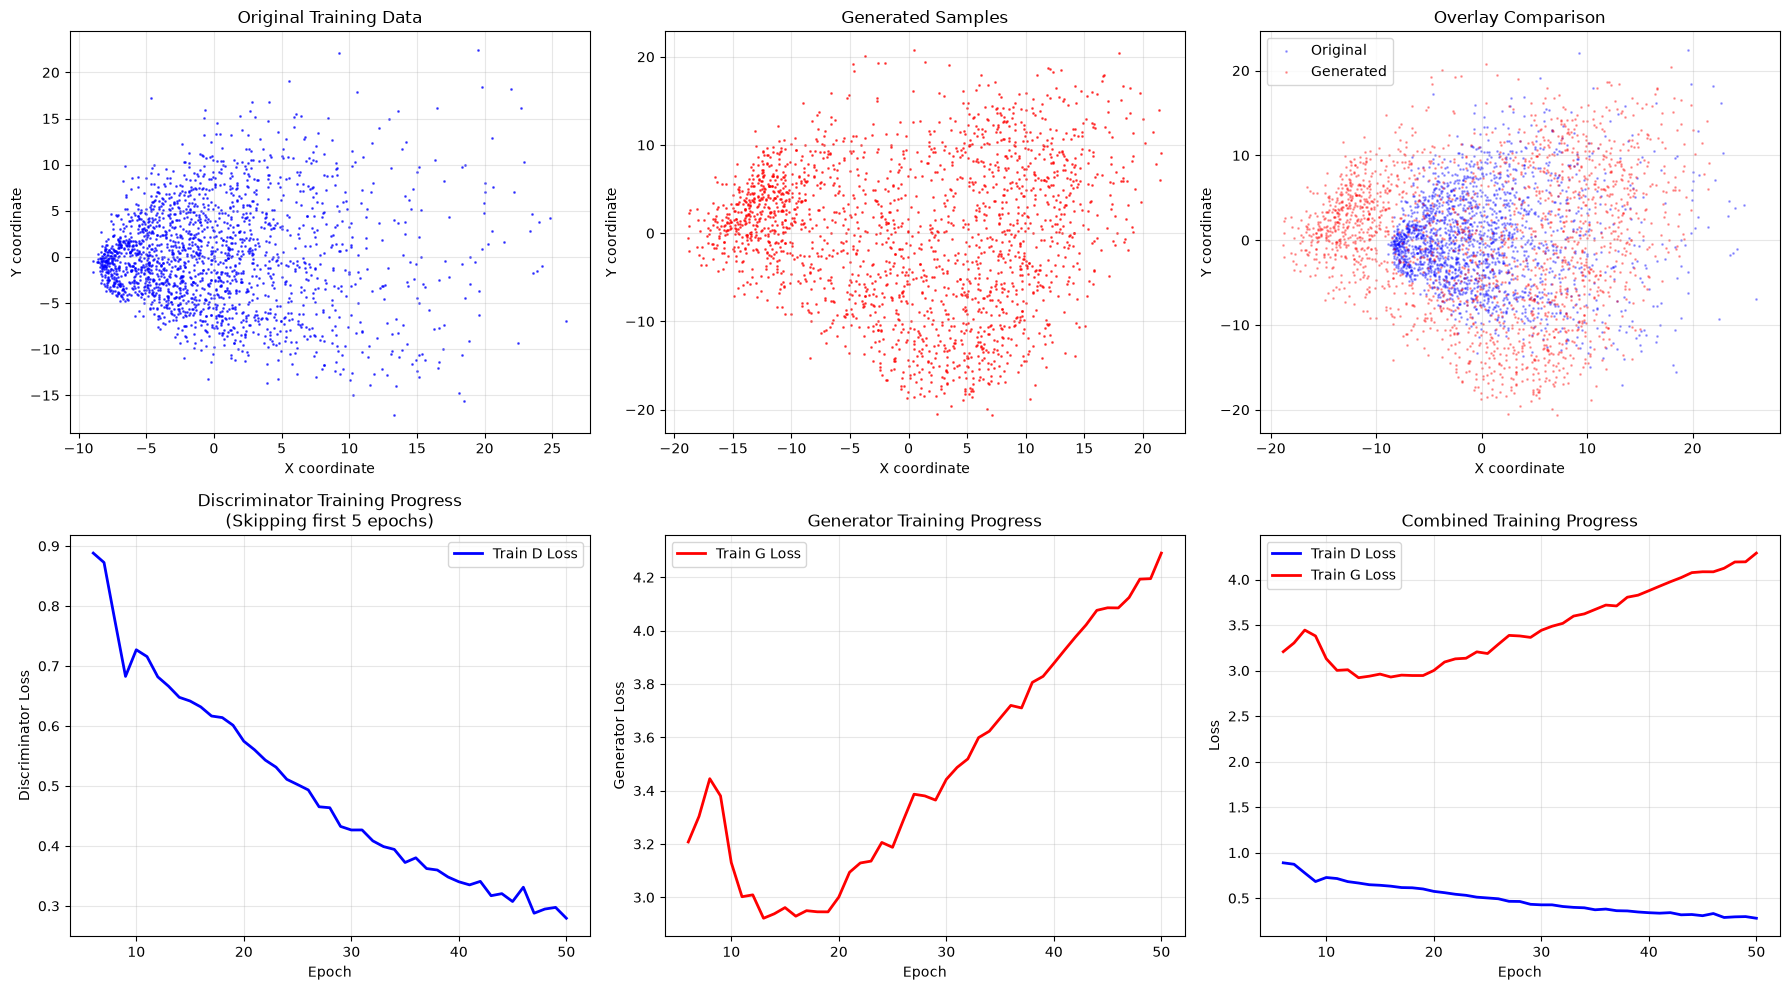

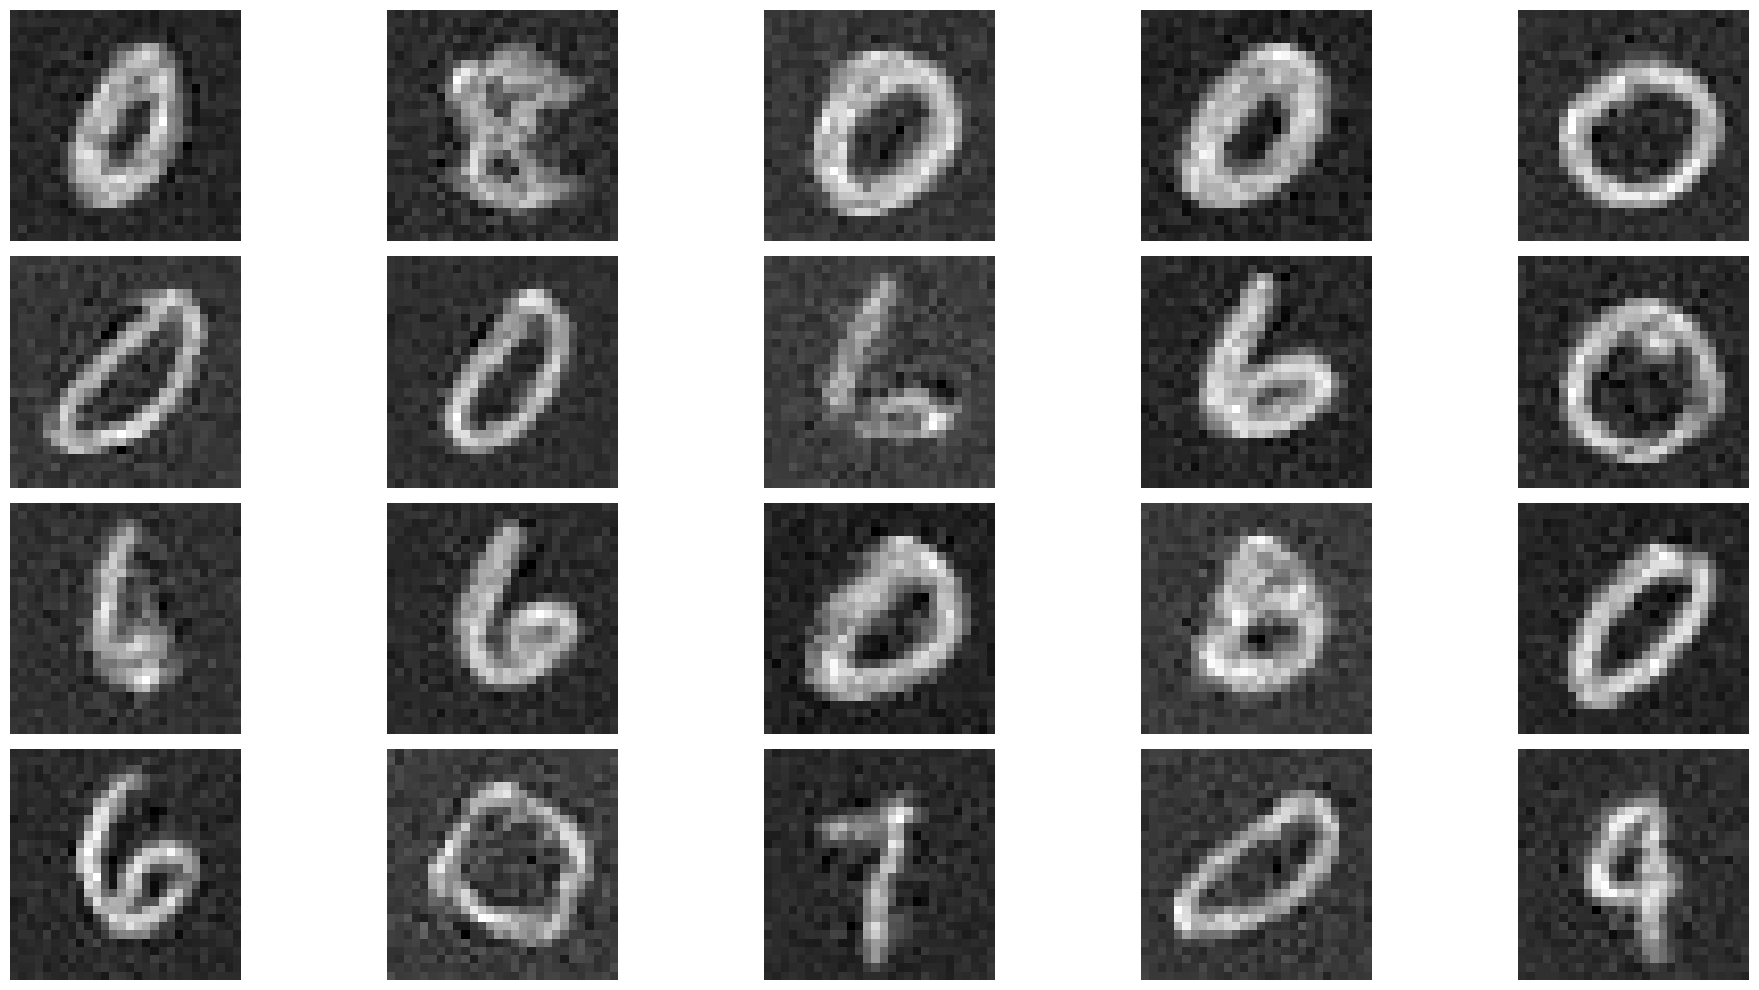

📈 Epoch 50 Summary:
   Train D Loss: 0.2794, Val D Loss: 0.3466
   Train G Loss: 4.2905, Val G Loss: 2.8521

📊 Epoch 51/100
----------------------------------------
Epoch: 51 [0/60000 (0%)]	D_loss: 0.329185	G_loss: 6.019081
Epoch: 51 [6400/60000 (11%)]	D_loss: 0.220647	G_loss: 3.725384
Epoch: 51 [12800/60000 (21%)]	D_loss: 0.213677	G_loss: 3.845735
Epoch: 51 [19200/60000 (32%)]	D_loss: 0.196409	G_loss: 3.922817
Epoch: 51 [25600/60000 (43%)]	D_loss: 0.320098	G_loss: 3.531105
Epoch: 51 [32000/60000 (53%)]	D_loss: 0.423900	G_loss: 2.644312
Epoch: 51 [38400/60000 (64%)]	D_loss: 0.213211	G_loss: 4.064965
Epoch: 51 [44800/60000 (75%)]	D_loss: 0.185772	G_loss: 3.934486
Epoch: 51 [51200/60000 (85%)]	D_loss: 0.408306	G_loss: 4.542333
Epoch: 51 [57600/60000 (96%)]	D_loss: 0.348827	G_loss: 6.787827
====> Epoch: 51 Train D_loss: 0.2796, Train G_loss: 4.3786
====> Epoch: 51 Val D_loss: 0.3503, Val G_loss: 3.4574
📈 Epoch 51 Summary:
   Train D Loss: 0.2796, Val D Loss: 0.3503
   Train G Loss: 4.3786

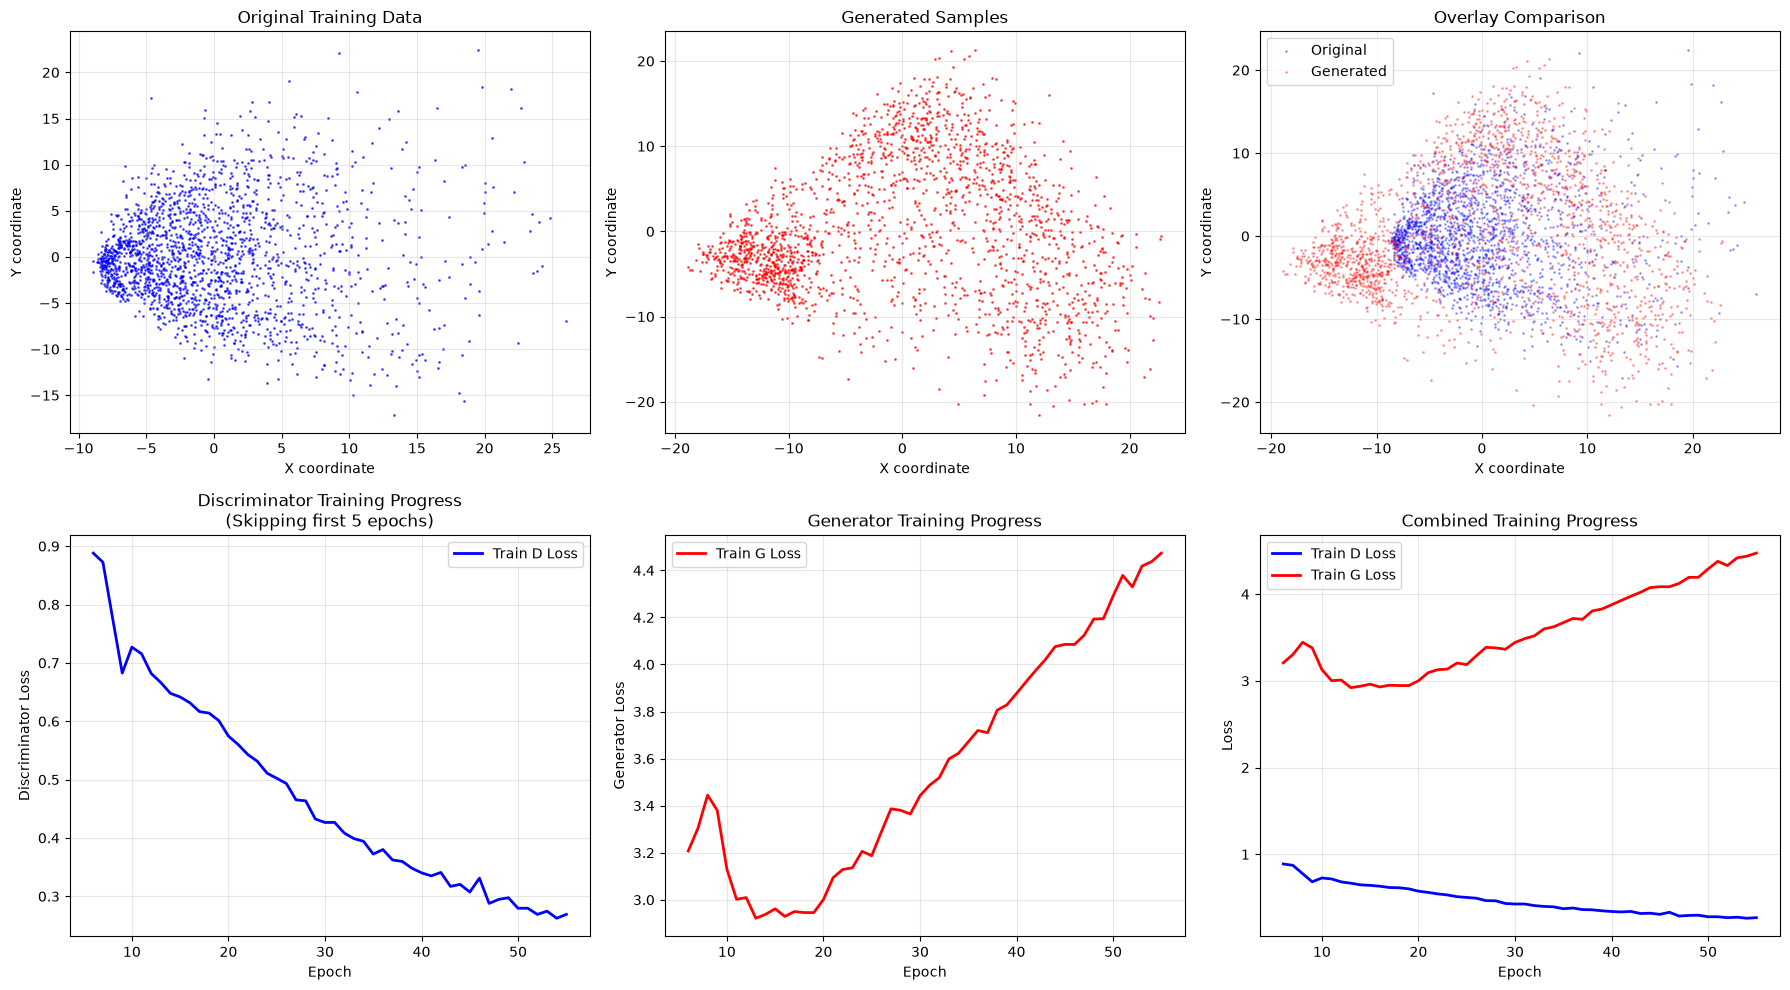

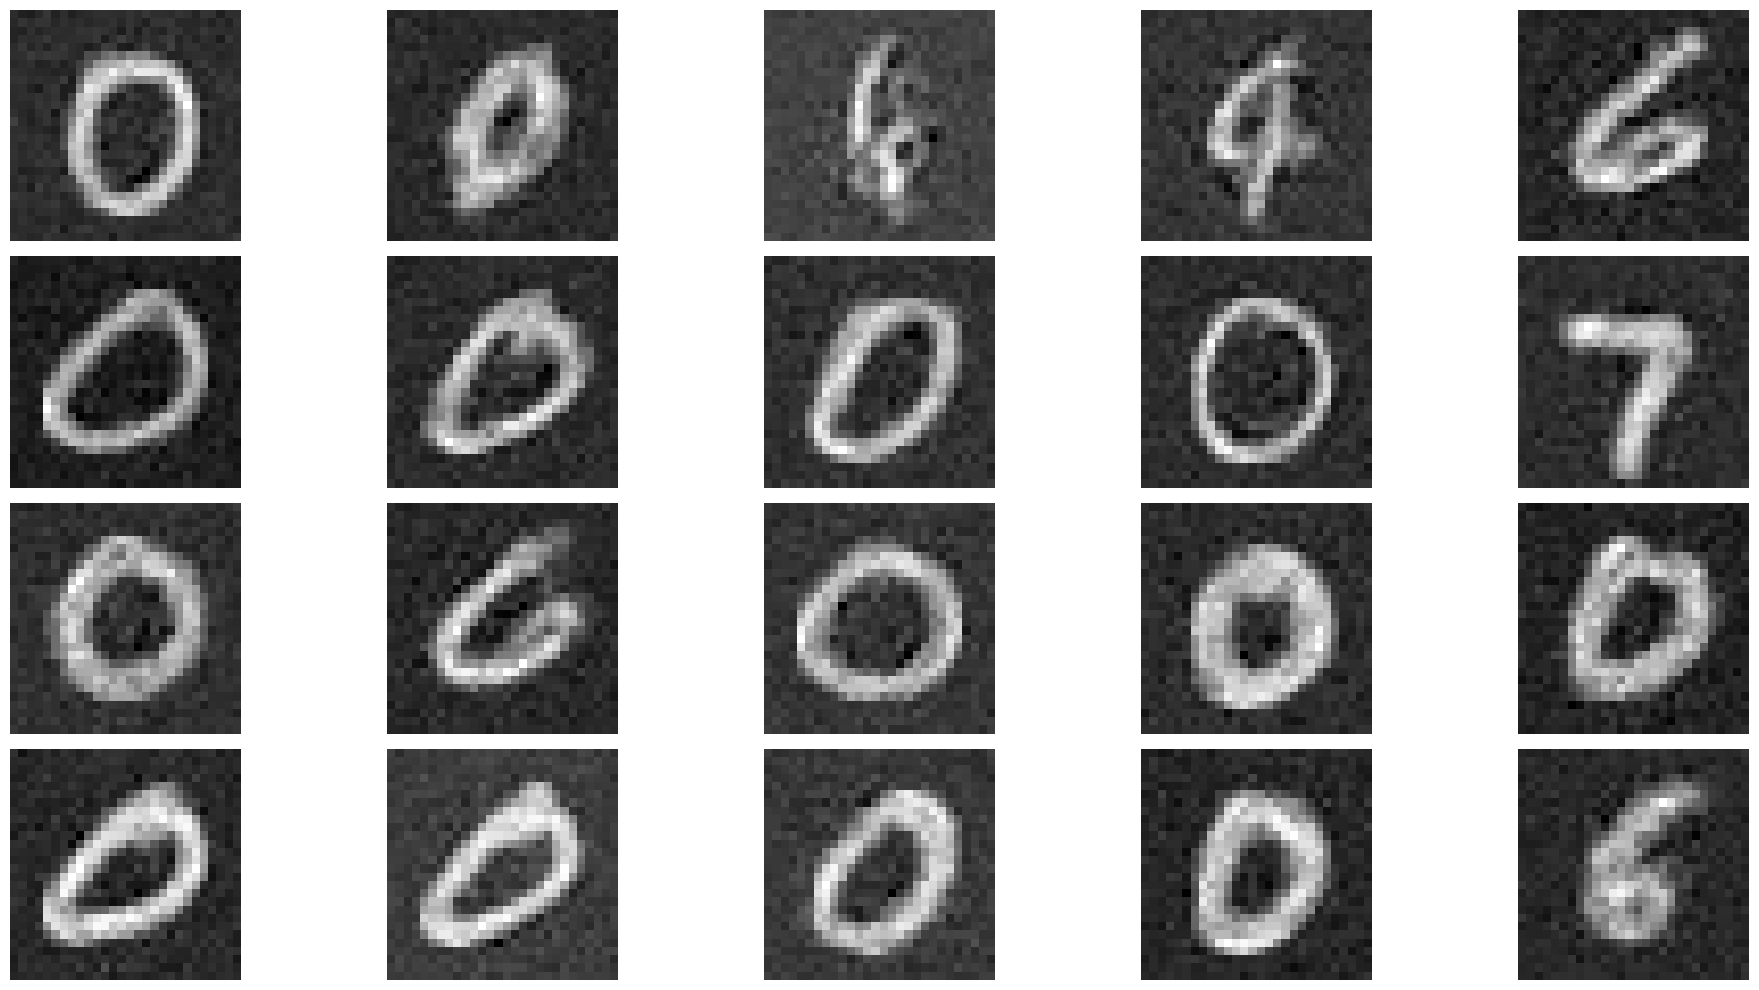

📈 Epoch 55 Summary:
   Train D Loss: 0.2690, Val D Loss: 0.3751
   Train G Loss: 4.4734, Val G Loss: 4.0278

📊 Epoch 56/100
----------------------------------------
Epoch: 56 [0/60000 (0%)]	D_loss: 0.235349	G_loss: 4.783509
Epoch: 56 [6400/60000 (11%)]	D_loss: 0.124554	G_loss: 4.511009
Epoch: 56 [12800/60000 (21%)]	D_loss: 0.267315	G_loss: 6.389299
Epoch: 56 [19200/60000 (32%)]	D_loss: 0.205275	G_loss: 4.610435
Epoch: 56 [25600/60000 (43%)]	D_loss: 0.310258	G_loss: 3.707947
Epoch: 56 [32000/60000 (53%)]	D_loss: 0.228489	G_loss: 4.185869
Epoch: 56 [38400/60000 (64%)]	D_loss: 0.110463	G_loss: 5.144774
Epoch: 56 [44800/60000 (75%)]	D_loss: 0.286089	G_loss: 4.133109
Epoch: 56 [51200/60000 (85%)]	D_loss: 0.192393	G_loss: 4.355145
Epoch: 56 [57600/60000 (96%)]	D_loss: 0.277741	G_loss: 3.505412
====> Epoch: 56 Train D_loss: 0.2576, Train G_loss: 4.4936
====> Epoch: 56 Val D_loss: 0.3012, Val G_loss: 3.8181
📈 Epoch 56 Summary:
   Train D Loss: 0.2576, Val D Loss: 0.3012
   Train G Loss: 4.4936

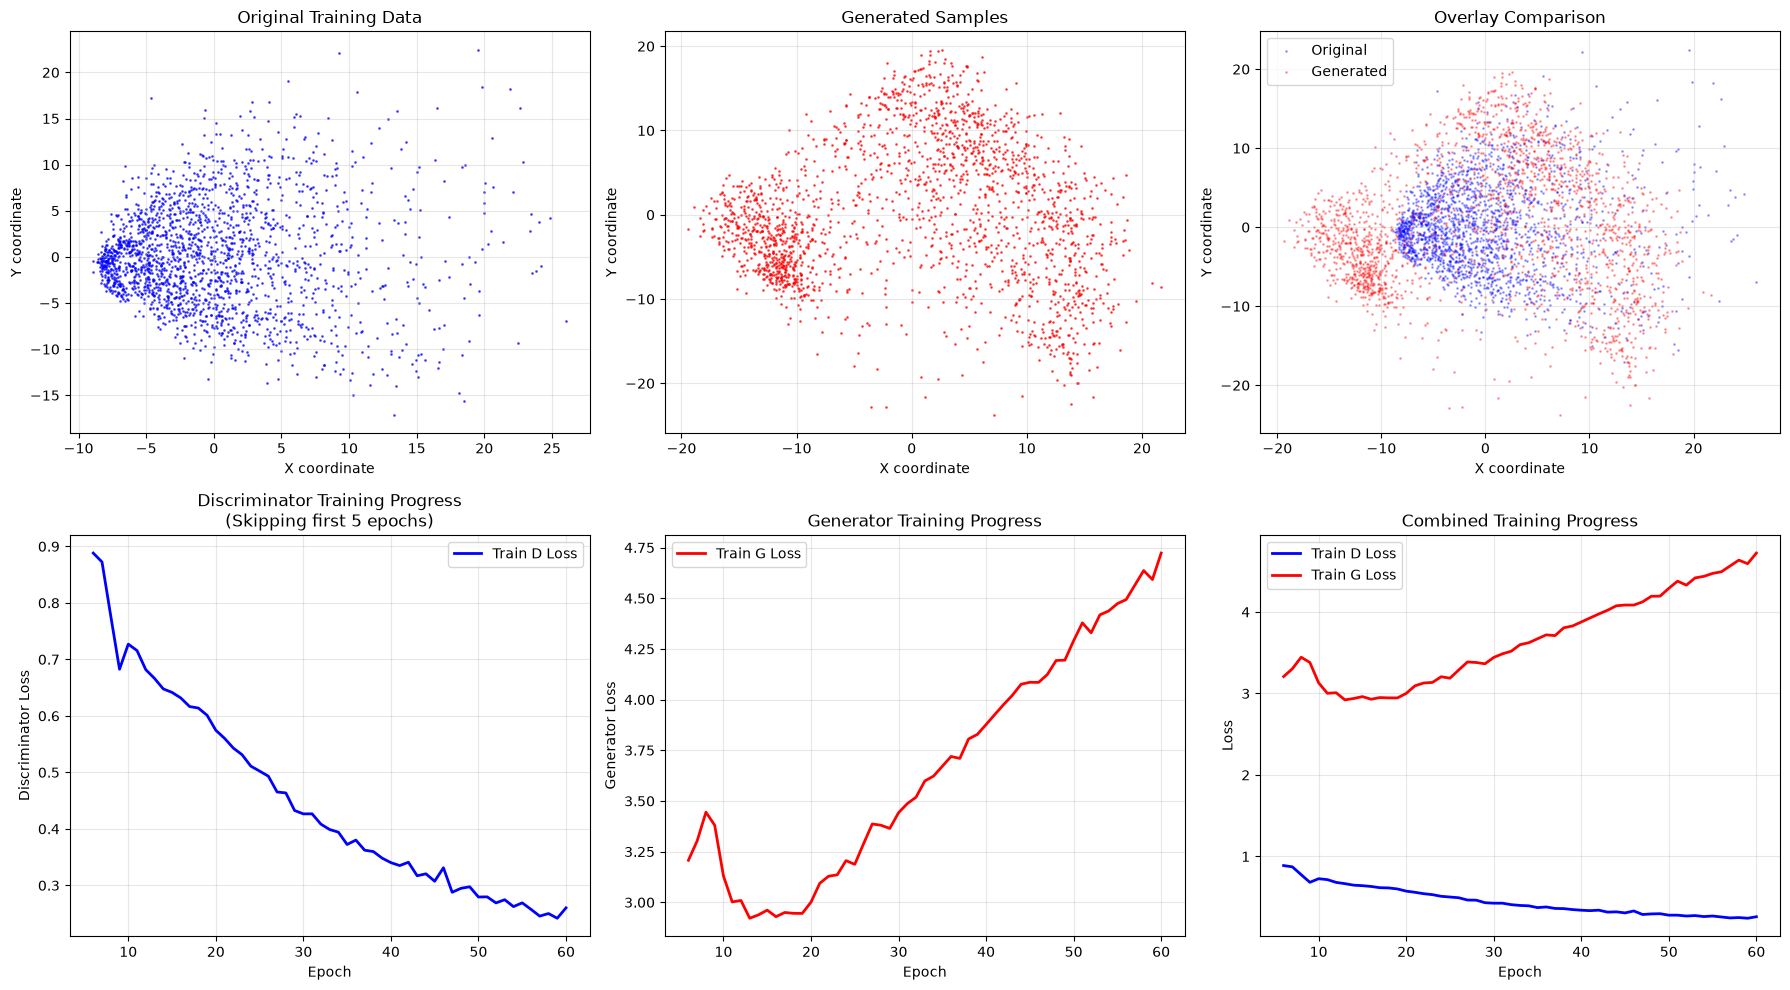

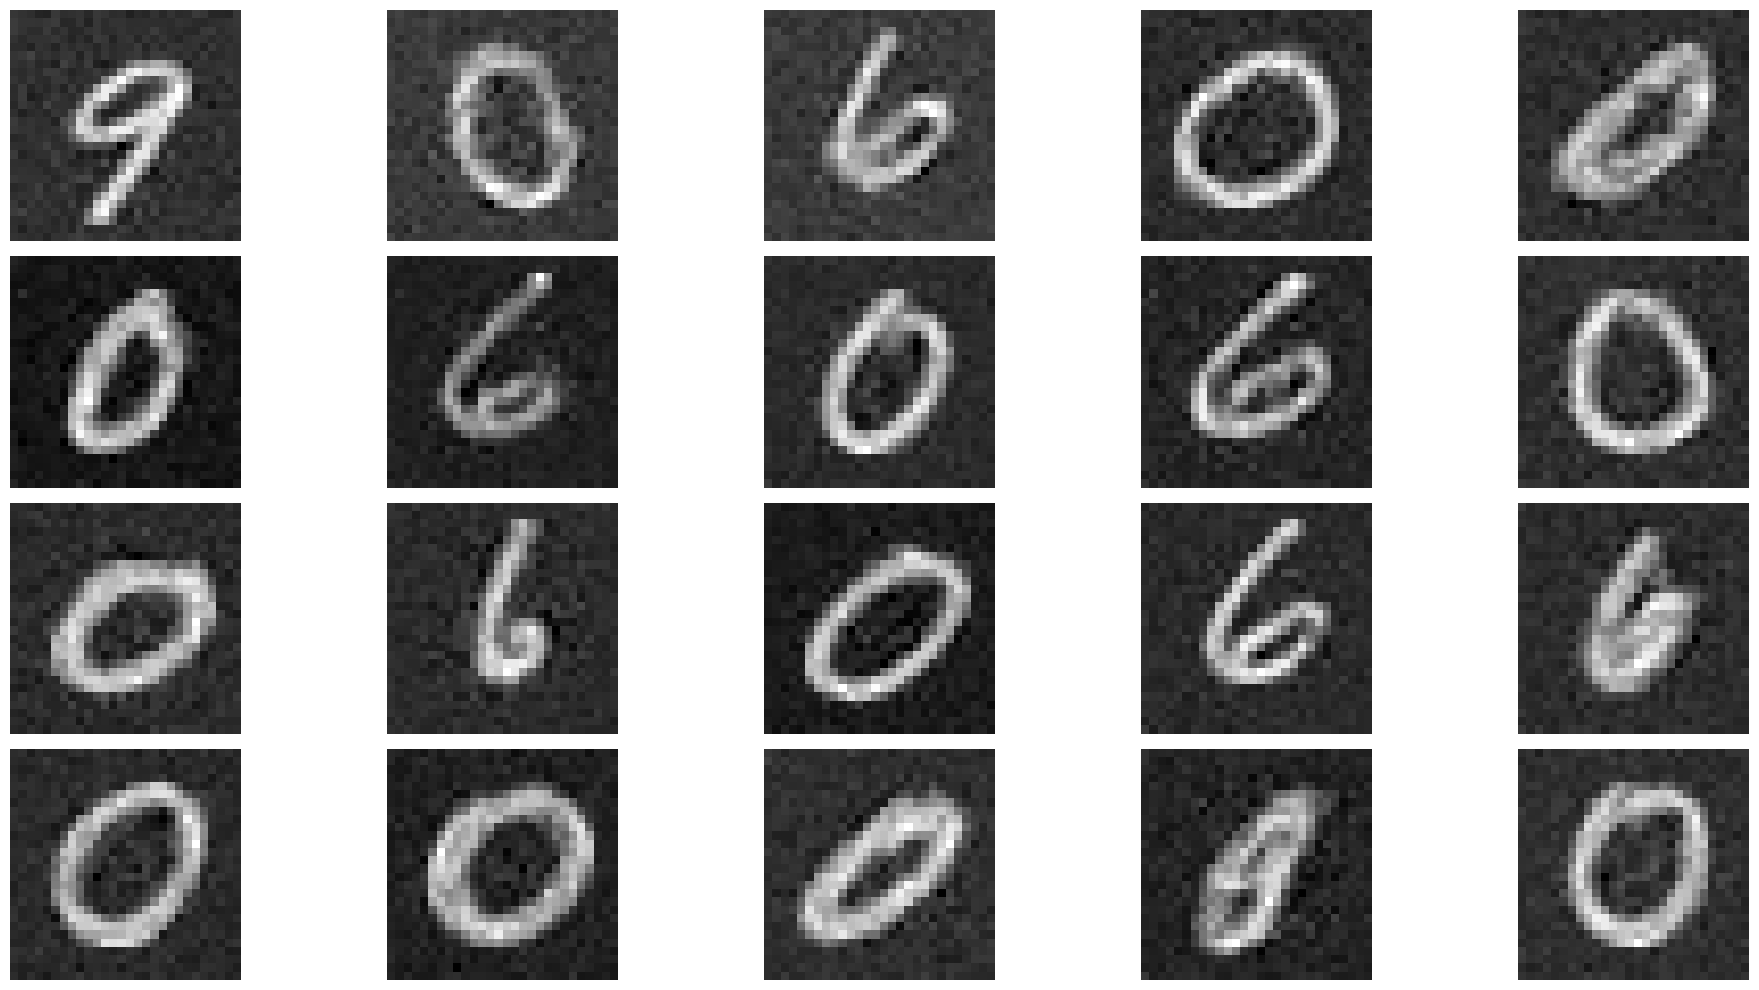

📈 Epoch 60 Summary:
   Train D Loss: 0.2601, Val D Loss: 0.2963
   Train G Loss: 4.7227, Val G Loss: 3.1749

📊 Epoch 61/100
----------------------------------------
Epoch: 61 [0/60000 (0%)]	D_loss: 0.248786	G_loss: 4.128051
Epoch: 61 [6400/60000 (11%)]	D_loss: 0.177048	G_loss: 4.252049
Epoch: 61 [12800/60000 (21%)]	D_loss: 0.198371	G_loss: 3.706625
Epoch: 61 [19200/60000 (32%)]	D_loss: 0.111430	G_loss: 4.705457
Epoch: 61 [25600/60000 (43%)]	D_loss: 0.271997	G_loss: 3.473322
Epoch: 61 [32000/60000 (53%)]	D_loss: 0.212740	G_loss: 5.257132
Epoch: 61 [38400/60000 (64%)]	D_loss: 0.249178	G_loss: 5.409978
Epoch: 61 [44800/60000 (75%)]	D_loss: 0.273441	G_loss: 4.071244
Epoch: 61 [51200/60000 (85%)]	D_loss: 0.318578	G_loss: 6.473181
Epoch: 61 [57600/60000 (96%)]	D_loss: 0.228410	G_loss: 4.166504
====> Epoch: 61 Train D_loss: 0.2347, Train G_loss: 4.6301
====> Epoch: 61 Val D_loss: 0.2691, Val G_loss: 3.2144
📈 Epoch 61 Summary:
   Train D Loss: 0.2347, Val D Loss: 0.2691
   Train G Loss: 4.6301

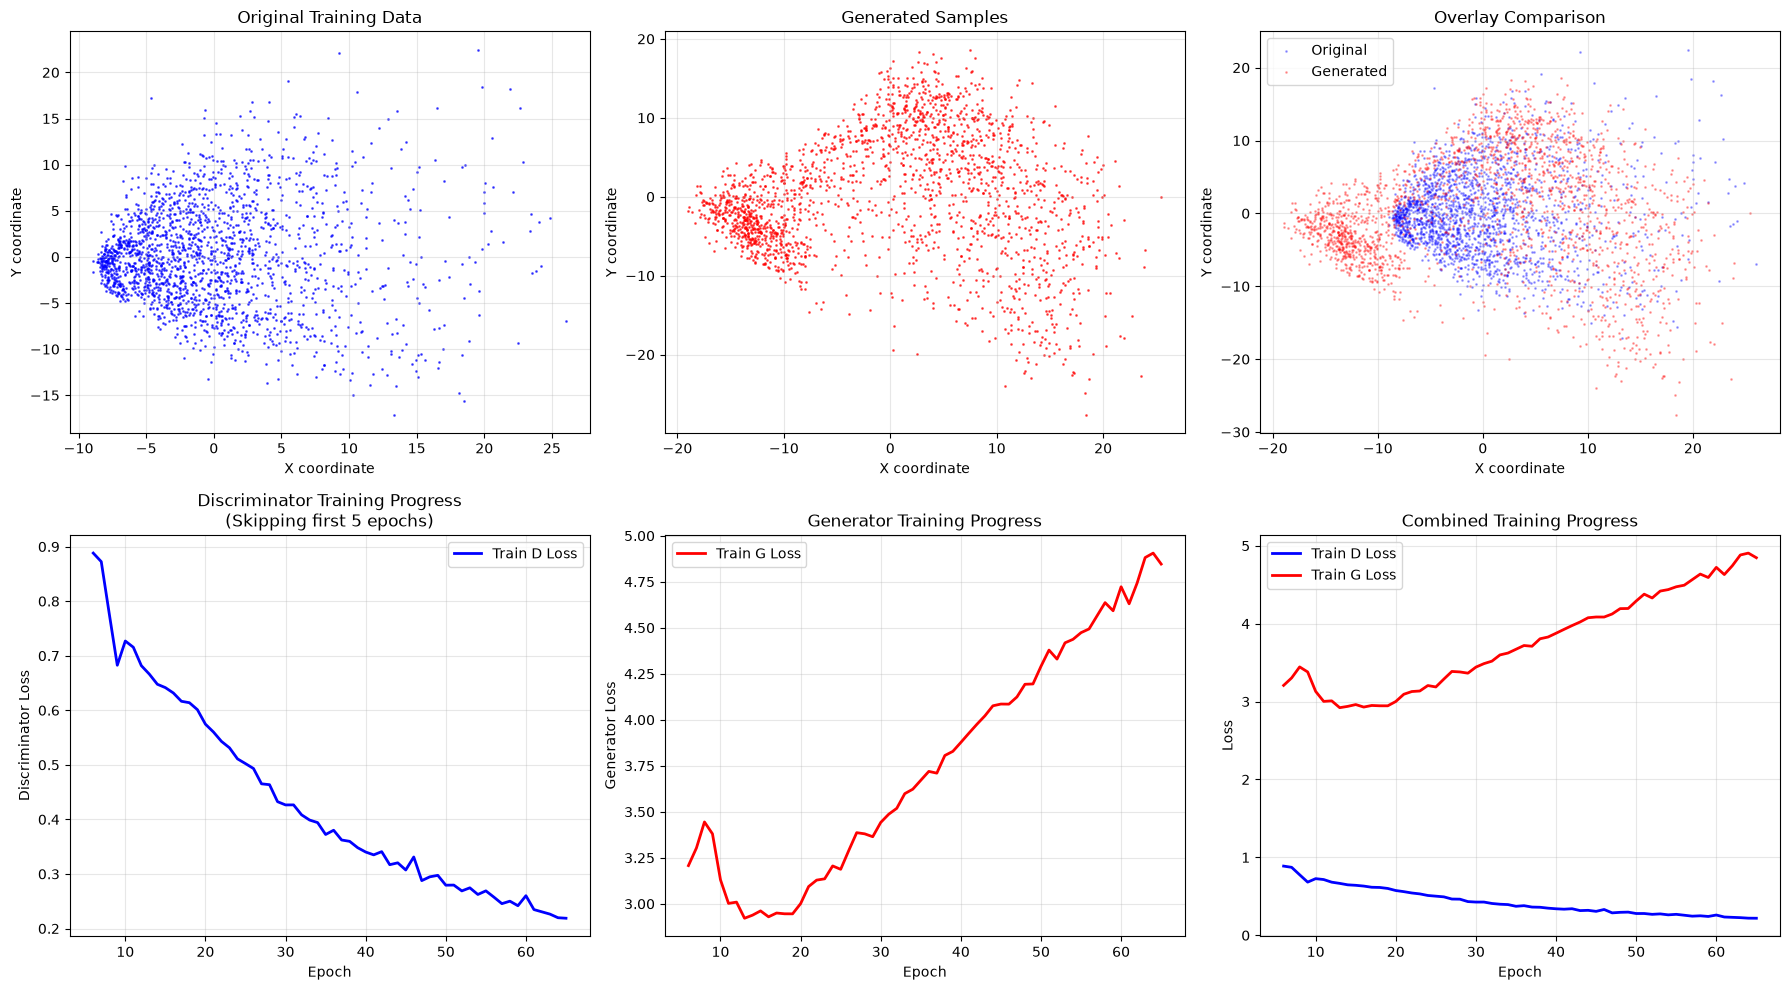

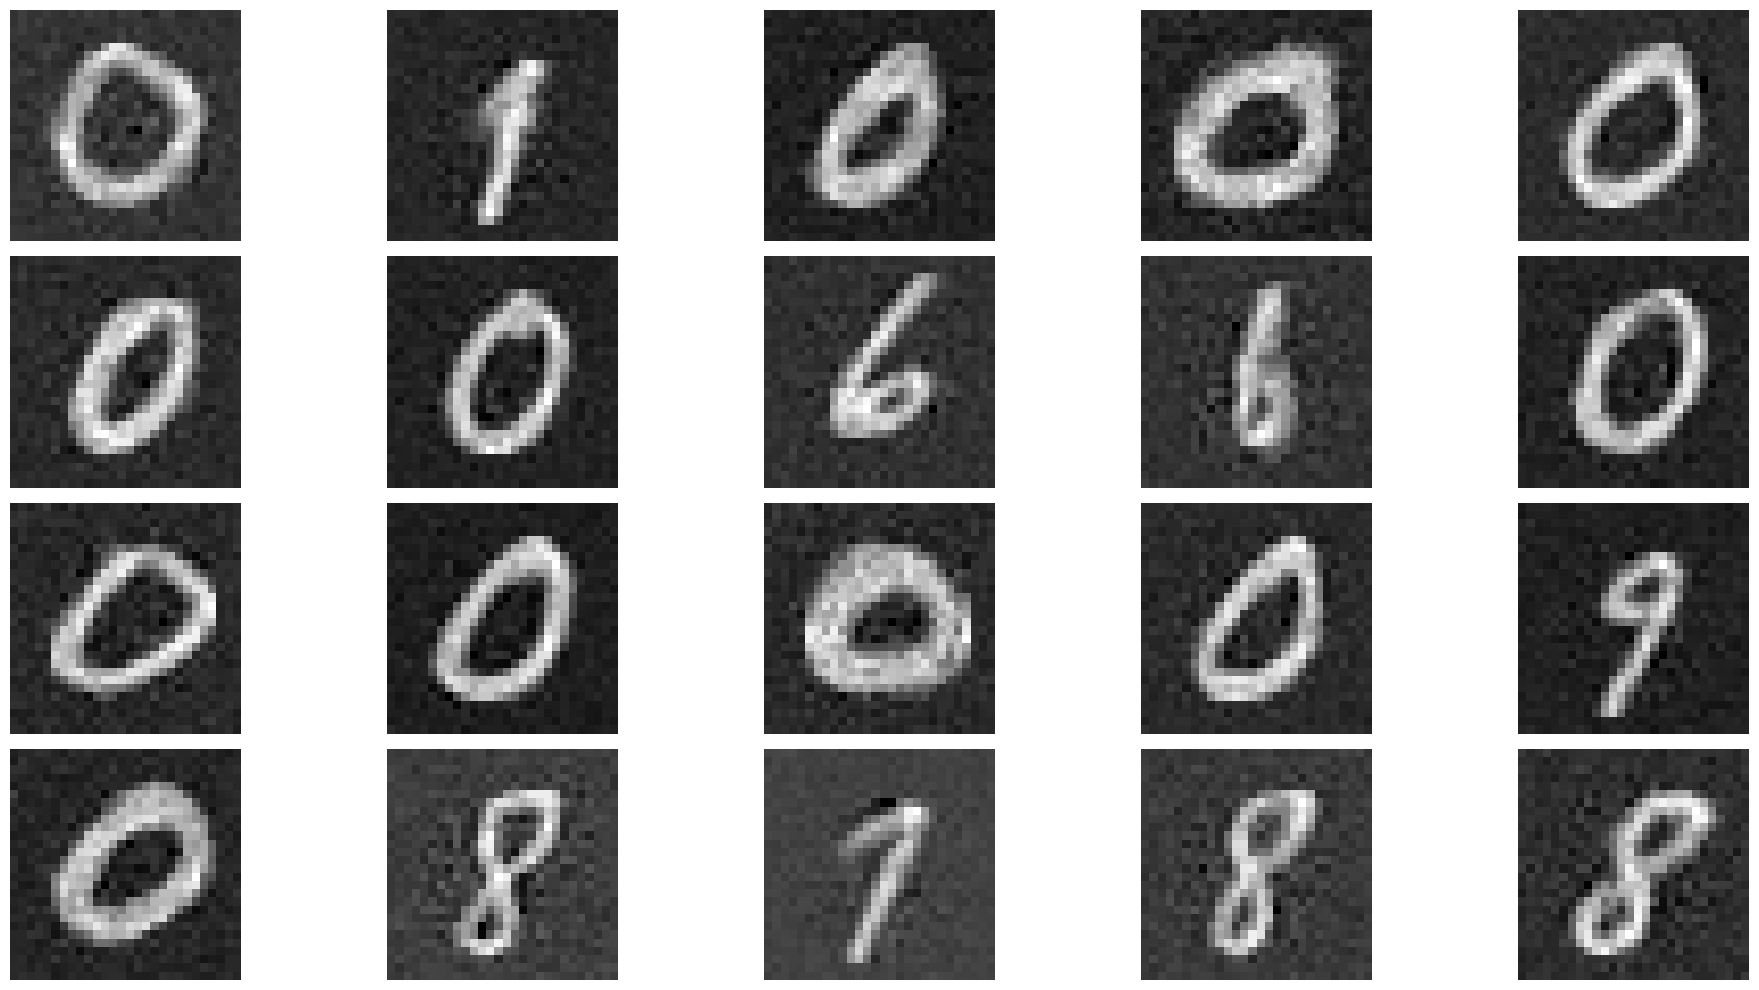

📈 Epoch 65 Summary:
   Train D Loss: 0.2188, Val D Loss: 0.4525
   Train G Loss: 4.8461, Val G Loss: 6.2539

📊 Epoch 66/100
----------------------------------------
Epoch: 66 [0/60000 (0%)]	D_loss: 0.171555	G_loss: 6.458899
Epoch: 66 [6400/60000 (11%)]	D_loss: 0.089221	G_loss: 4.517453
Epoch: 66 [12800/60000 (21%)]	D_loss: 0.309136	G_loss: 7.510545
Epoch: 66 [19200/60000 (32%)]	D_loss: 0.161015	G_loss: 4.680145
Epoch: 66 [25600/60000 (43%)]	D_loss: 0.400411	G_loss: 5.102142
Epoch: 66 [32000/60000 (53%)]	D_loss: 0.232925	G_loss: 4.066631
Epoch: 66 [38400/60000 (64%)]	D_loss: 0.382827	G_loss: 3.990446
Epoch: 66 [44800/60000 (75%)]	D_loss: 0.212386	G_loss: 4.540458
Epoch: 66 [51200/60000 (85%)]	D_loss: 0.450720	G_loss: 4.320720
Epoch: 66 [57600/60000 (96%)]	D_loss: 0.406402	G_loss: 6.463324
====> Epoch: 66 Train D_loss: 0.2188, Train G_loss: 4.9323
====> Epoch: 66 Val D_loss: 0.2950, Val G_loss: 3.5158
📈 Epoch 66 Summary:
   Train D Loss: 0.2188, Val D Loss: 0.2950
   Train G Loss: 4.9323

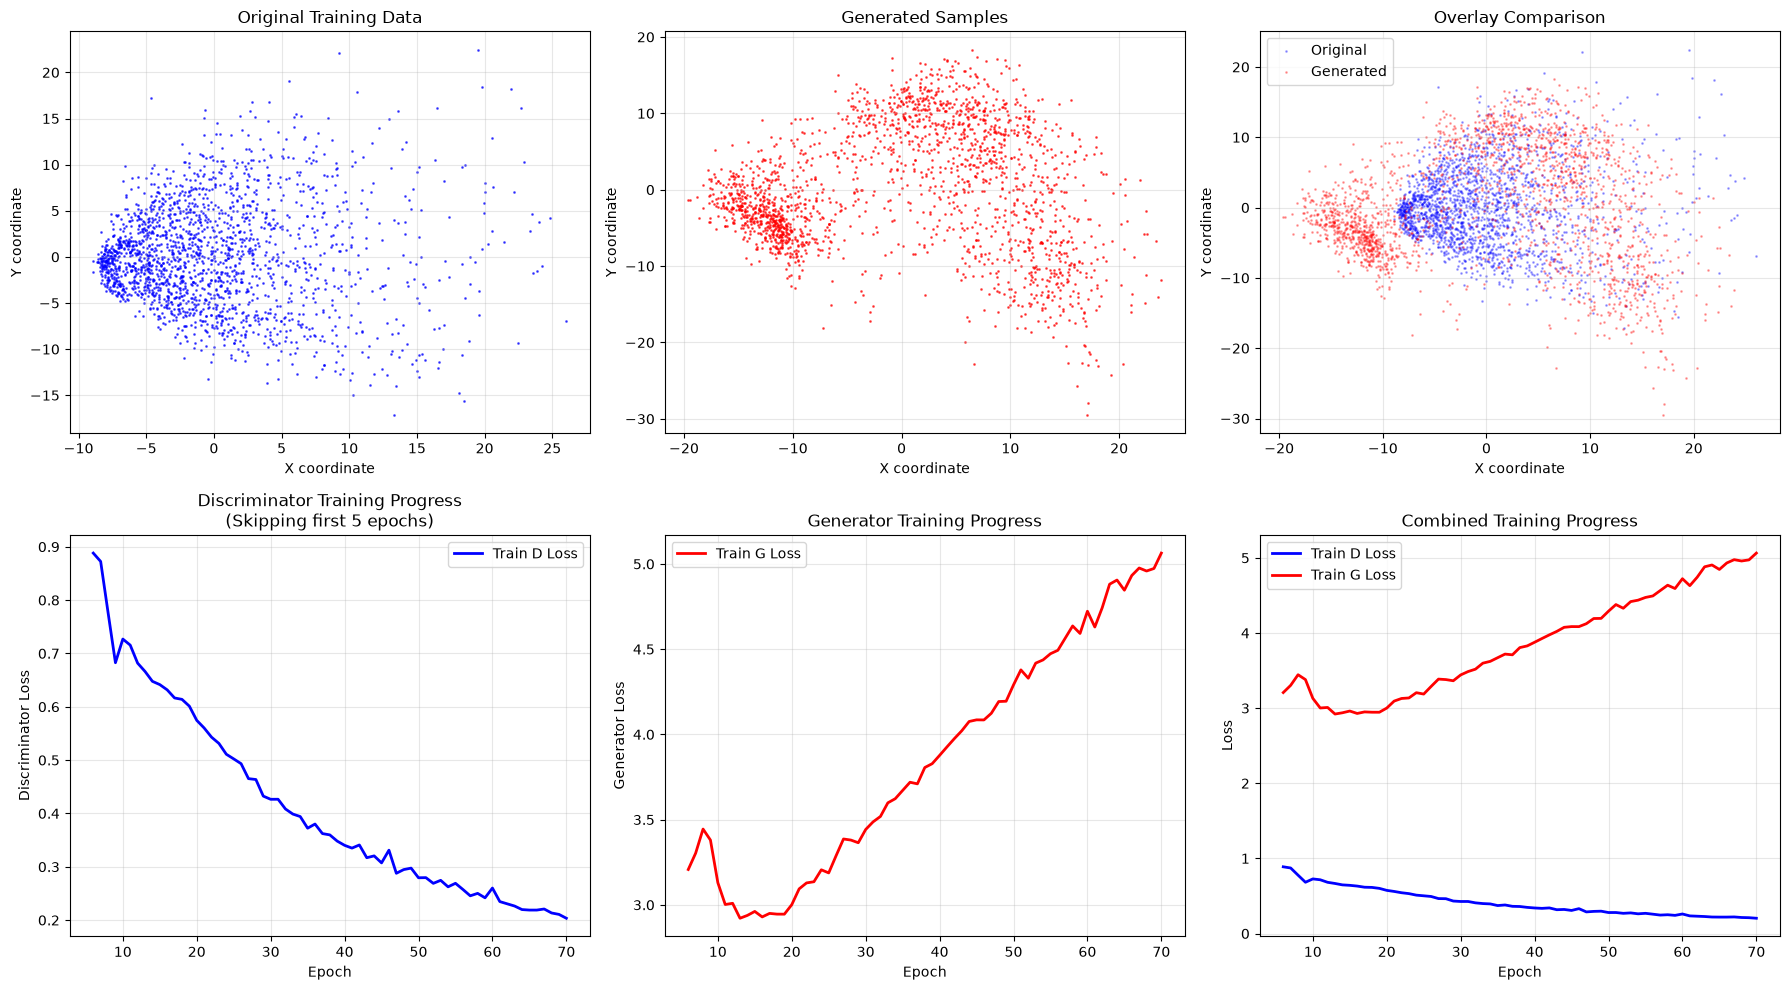

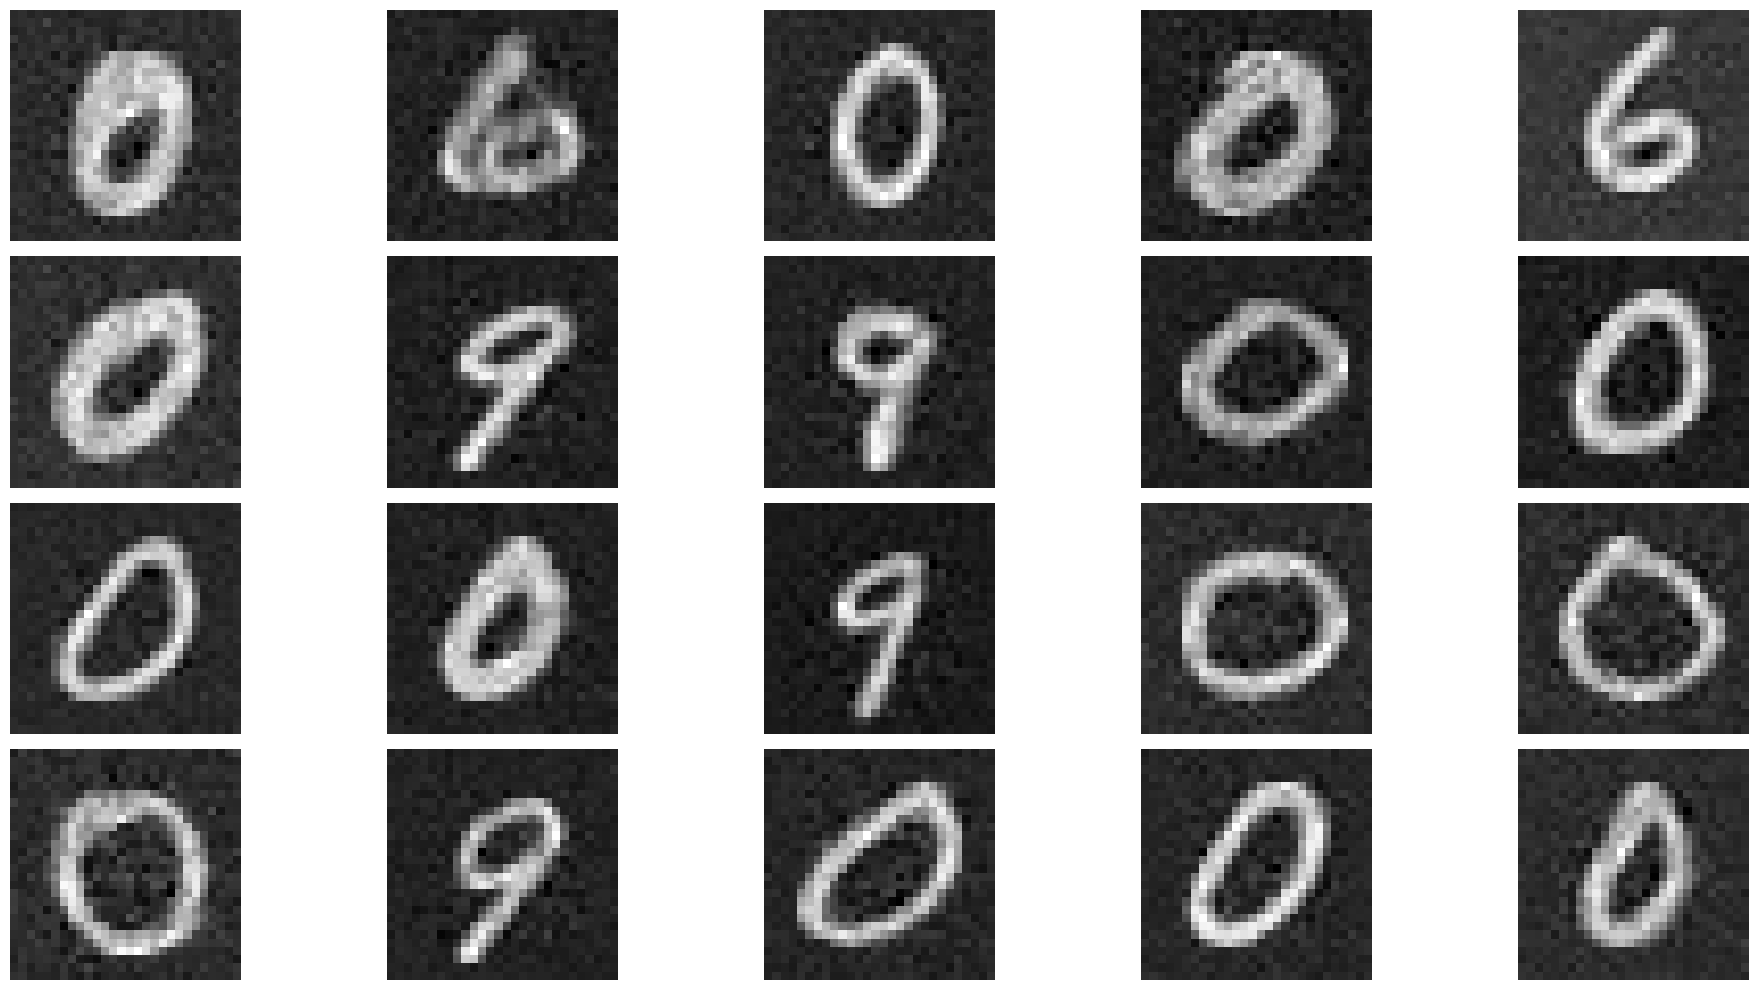

📈 Epoch 70 Summary:
   Train D Loss: 0.2035, Val D Loss: 0.2864
   Train G Loss: 5.0638, Val G Loss: 4.1695

📊 Epoch 71/100
----------------------------------------
Epoch: 71 [0/60000 (0%)]	D_loss: 0.125113	G_loss: 5.298090
Epoch: 71 [6400/60000 (11%)]	D_loss: 0.180479	G_loss: 3.662835
Epoch: 71 [12800/60000 (21%)]	D_loss: 0.201137	G_loss: 5.269251
Epoch: 71 [19200/60000 (32%)]	D_loss: 0.404175	G_loss: 5.164577
Epoch: 71 [25600/60000 (43%)]	D_loss: 0.191327	G_loss: 4.676113
Epoch: 71 [32000/60000 (53%)]	D_loss: 0.168563	G_loss: 5.722793
Epoch: 71 [38400/60000 (64%)]	D_loss: 0.190097	G_loss: 5.505620
Epoch: 71 [44800/60000 (75%)]	D_loss: 0.189247	G_loss: 3.696653
Epoch: 71 [51200/60000 (85%)]	D_loss: 0.318598	G_loss: 3.716323
Epoch: 71 [57600/60000 (96%)]	D_loss: 0.095008	G_loss: 4.869781
====> Epoch: 71 Train D_loss: 0.1978, Train G_loss: 5.0630
====> Epoch: 71 Val D_loss: 0.4033, Val G_loss: 6.3412
📈 Epoch 71 Summary:
   Train D Loss: 0.1978, Val D Loss: 0.4033
   Train G Loss: 5.0630

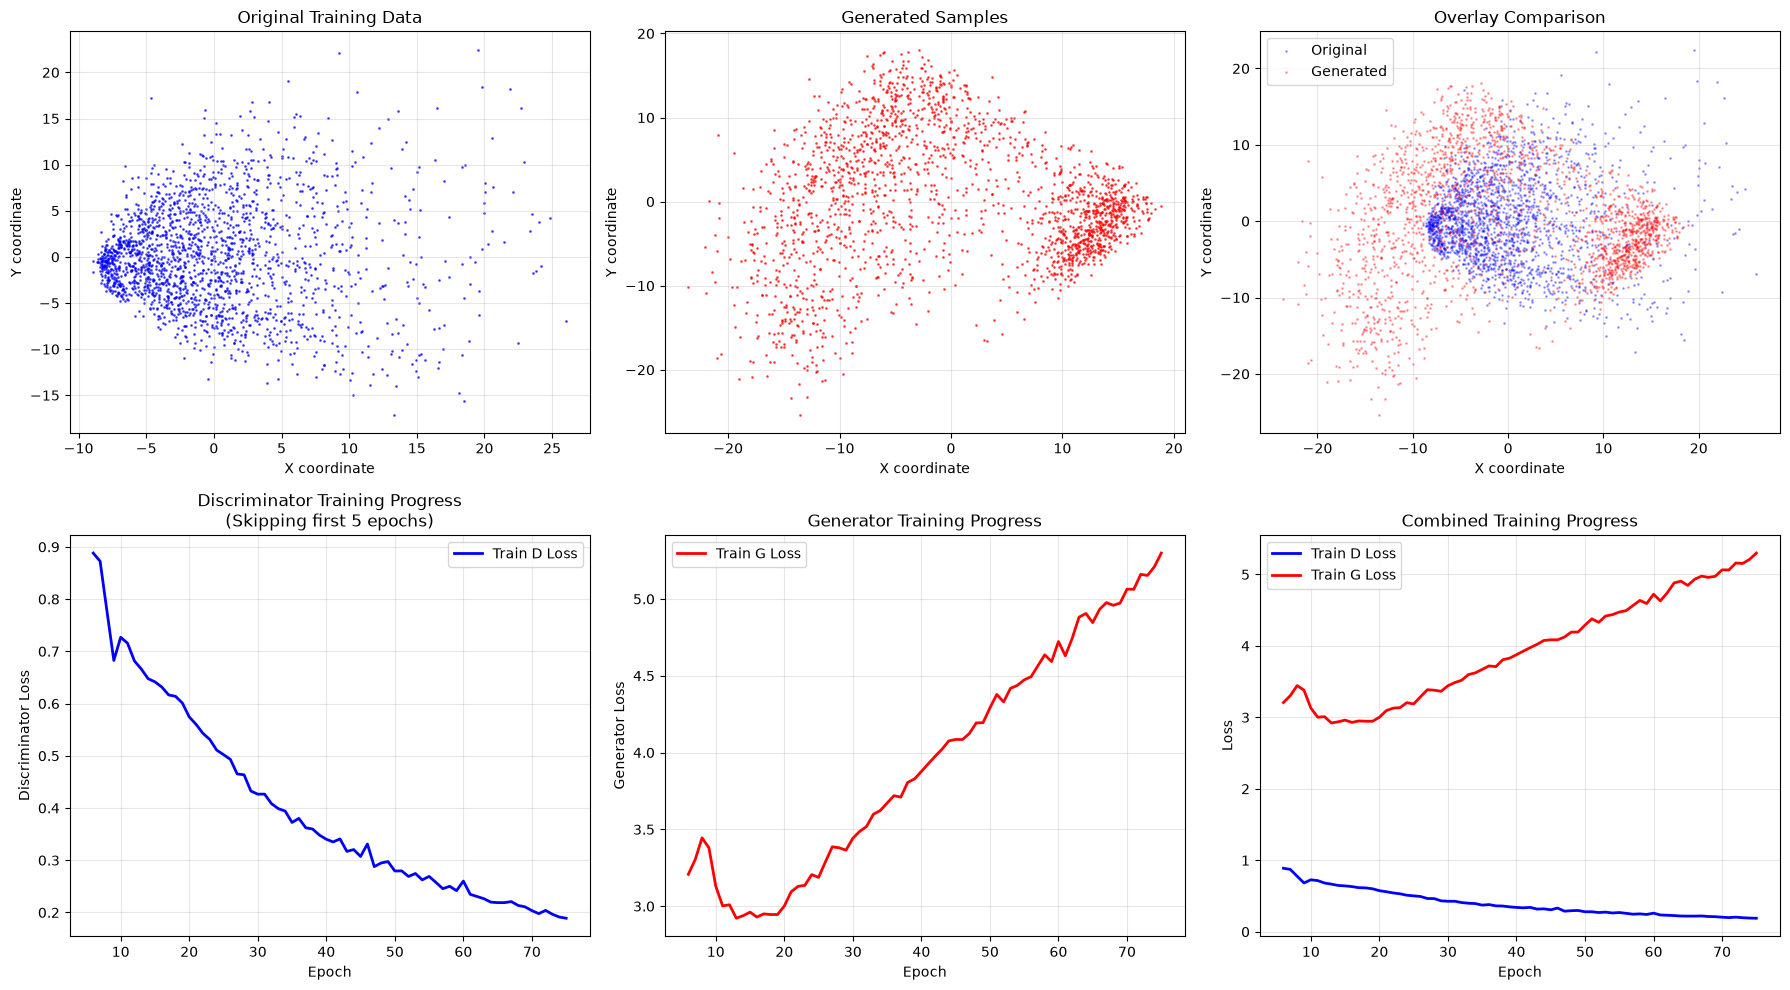

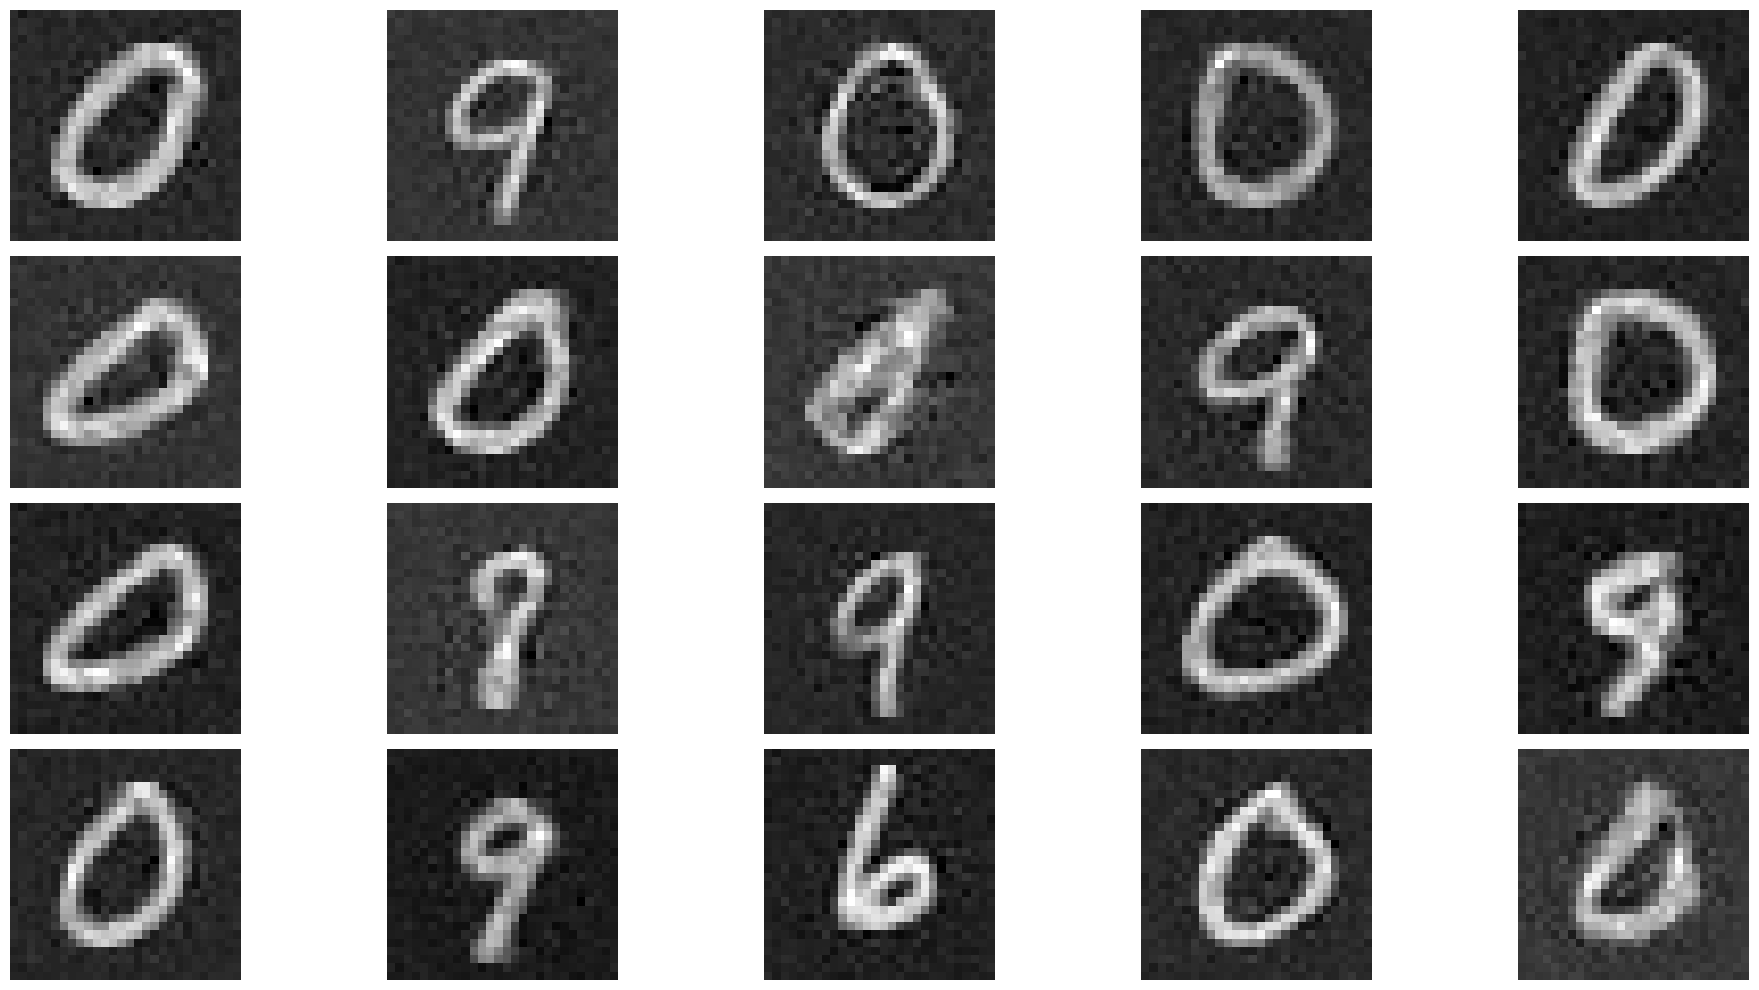

📈 Epoch 75 Summary:
   Train D Loss: 0.1890, Val D Loss: 0.4411
   Train G Loss: 5.2987, Val G Loss: 5.8576

📊 Epoch 76/100
----------------------------------------
Epoch: 76 [0/60000 (0%)]	D_loss: 0.156794	G_loss: 5.071188
Epoch: 76 [6400/60000 (11%)]	D_loss: 0.101421	G_loss: 5.288385
Epoch: 76 [12800/60000 (21%)]	D_loss: 0.181210	G_loss: 4.225052
Epoch: 76 [19200/60000 (32%)]	D_loss: 0.207175	G_loss: 5.715396
Epoch: 76 [25600/60000 (43%)]	D_loss: 0.196547	G_loss: 5.662772
Epoch: 76 [32000/60000 (53%)]	D_loss: 0.171217	G_loss: 4.248631
Epoch: 76 [38400/60000 (64%)]	D_loss: 0.211678	G_loss: 6.065885
Epoch: 76 [44800/60000 (75%)]	D_loss: 0.159036	G_loss: 5.019337
Epoch: 76 [51200/60000 (85%)]	D_loss: 0.151809	G_loss: 5.285536
Epoch: 76 [57600/60000 (96%)]	D_loss: 0.232028	G_loss: 6.177325
====> Epoch: 76 Train D_loss: 0.1890, Train G_loss: 5.2655
====> Epoch: 76 Val D_loss: 0.5849, Val G_loss: 6.7037
📈 Epoch 76 Summary:
   Train D Loss: 0.1890, Val D Loss: 0.5849
   Train G Loss: 5.2655

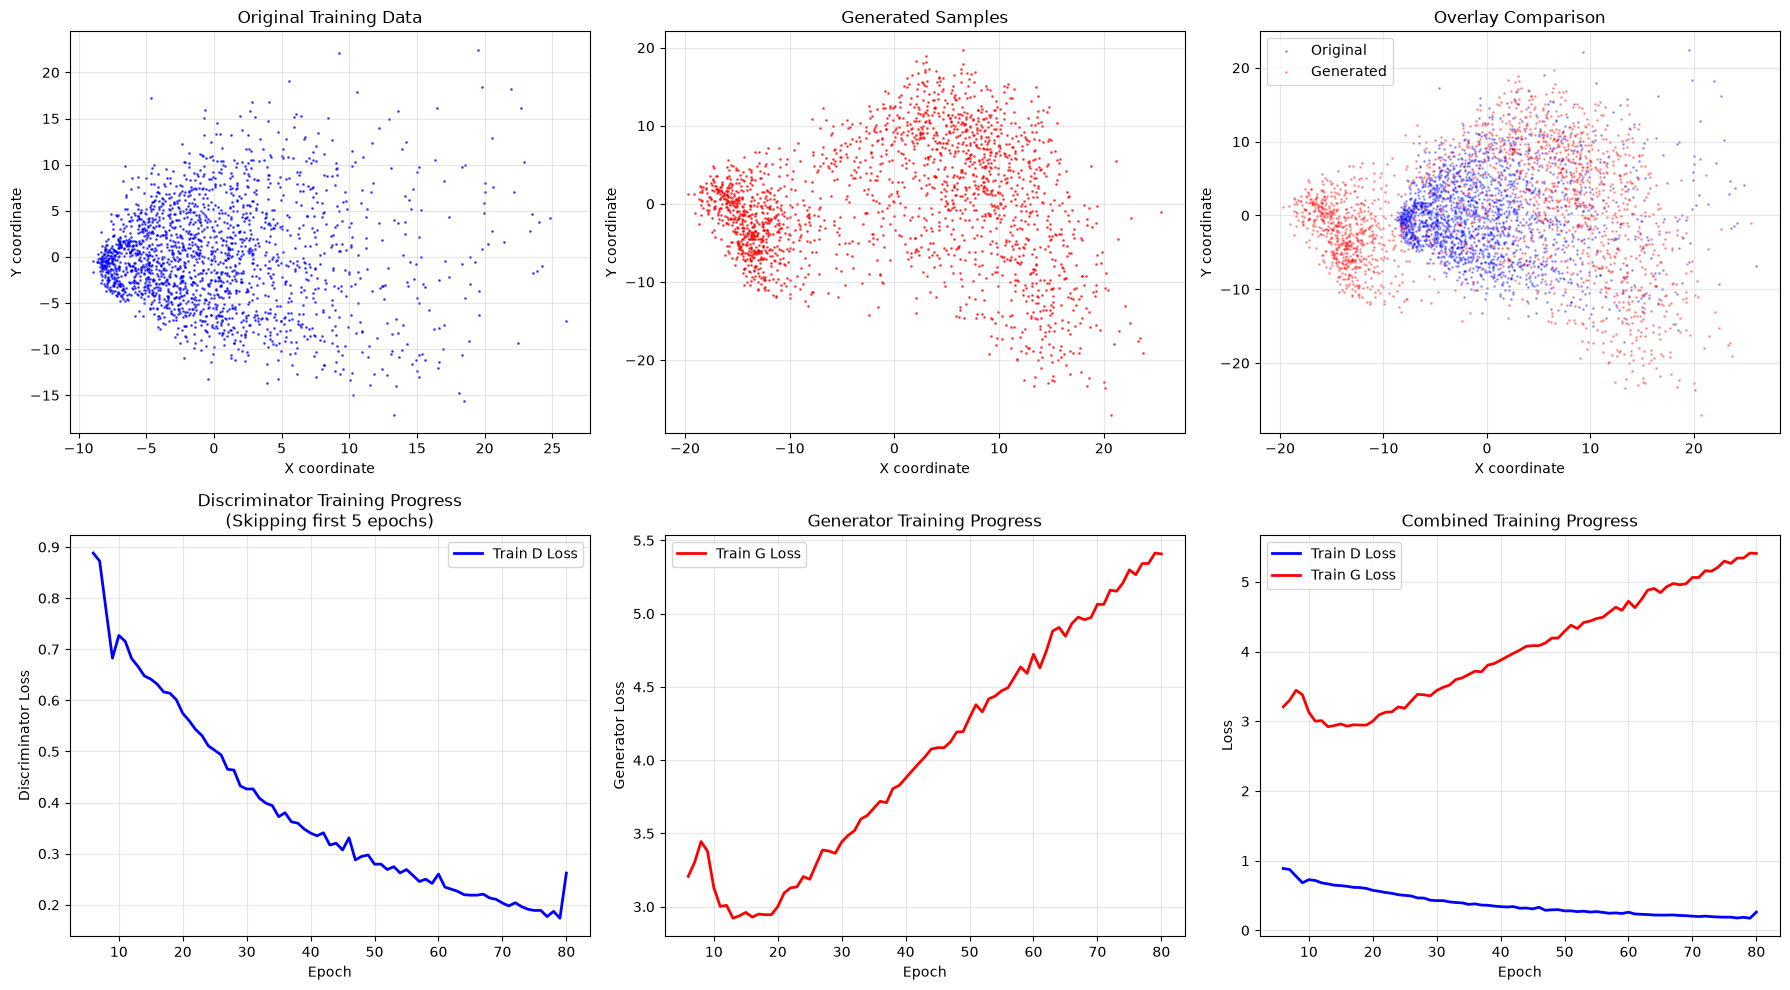

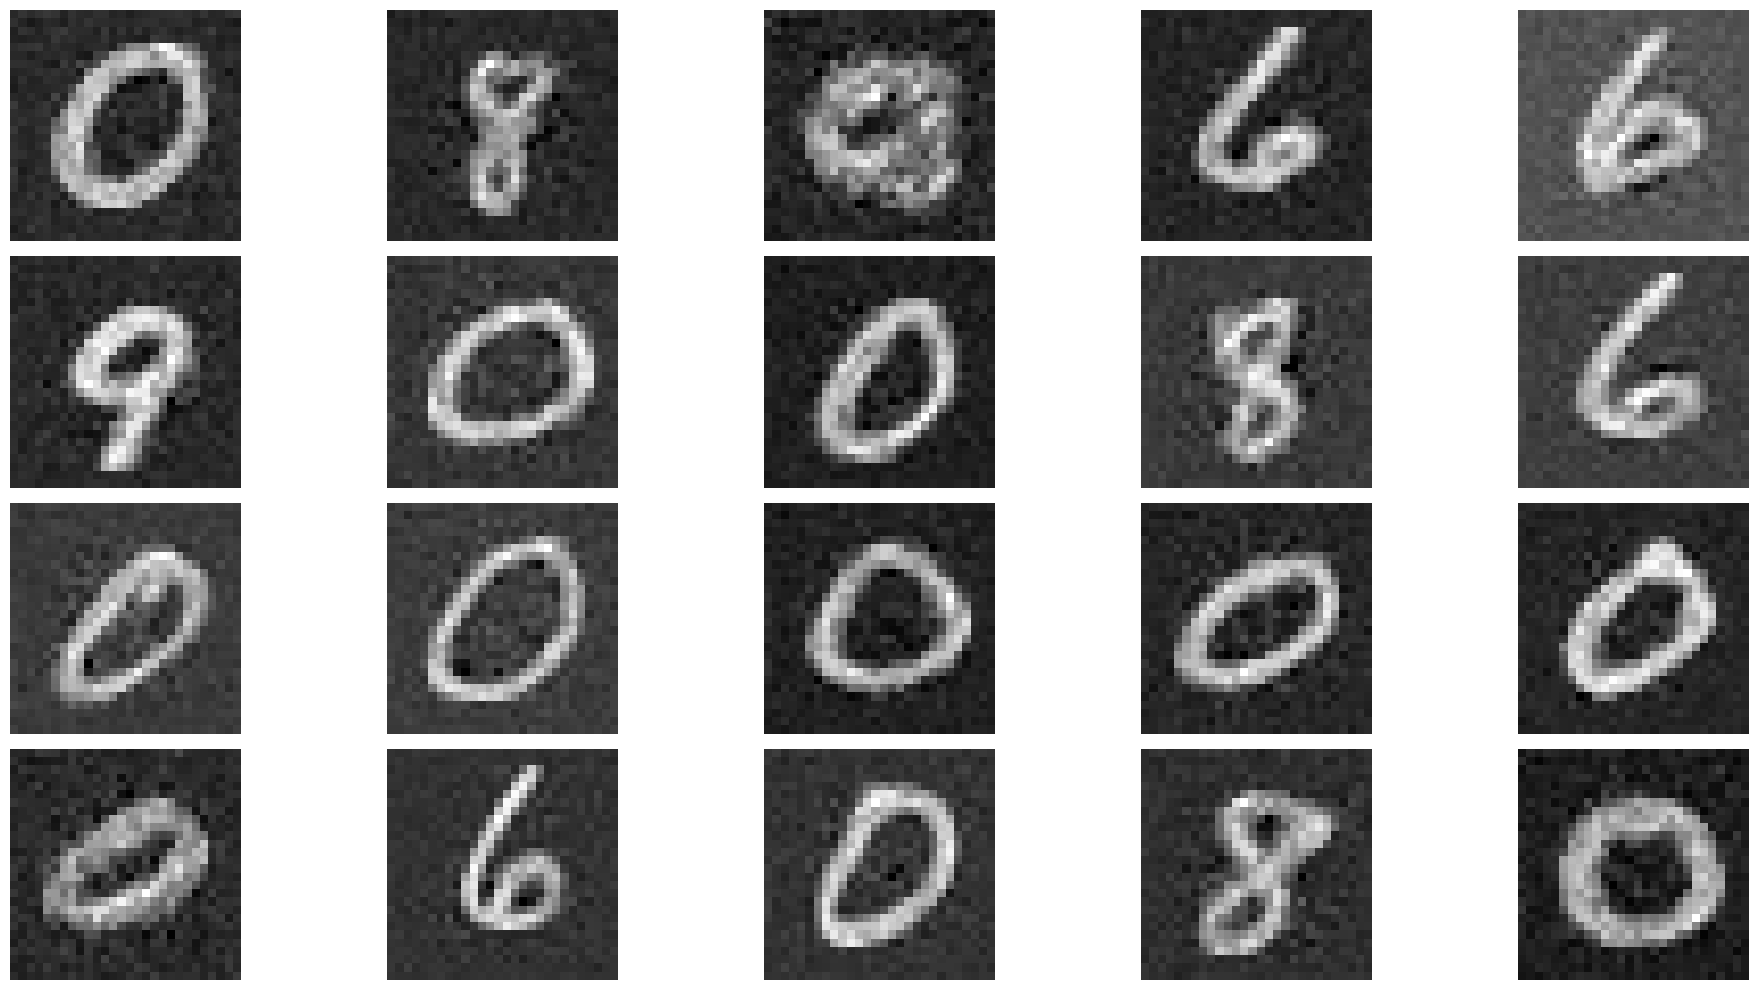

📈 Epoch 80 Summary:
   Train D Loss: 0.2620, Val D Loss: 0.2823
   Train G Loss: 5.4077, Val G Loss: 4.1594

📊 Epoch 81/100
----------------------------------------
Epoch: 81 [0/60000 (0%)]	D_loss: 0.124599	G_loss: 4.915545
Epoch: 81 [6400/60000 (11%)]	D_loss: 0.149000	G_loss: 4.174471
Epoch: 81 [12800/60000 (21%)]	D_loss: 0.219570	G_loss: 3.241344
Epoch: 81 [19200/60000 (32%)]	D_loss: 0.827058	G_loss: 10.255163
Epoch: 81 [25600/60000 (43%)]	D_loss: 0.106324	G_loss: 5.925398
Epoch: 81 [32000/60000 (53%)]	D_loss: 0.148353	G_loss: 5.189013
Epoch: 81 [38400/60000 (64%)]	D_loss: 0.135572	G_loss: 5.970132
Epoch: 81 [44800/60000 (75%)]	D_loss: 0.221362	G_loss: 4.021686
Epoch: 81 [51200/60000 (85%)]	D_loss: 0.137434	G_loss: 3.990960
Epoch: 81 [57600/60000 (96%)]	D_loss: 0.149533	G_loss: 4.439752
====> Epoch: 81 Train D_loss: 0.1700, Train G_loss: 5.1186
====> Epoch: 81 Val D_loss: 0.2763, Val G_loss: 4.0666
📈 Epoch 81 Summary:
   Train D Loss: 0.1700, Val D Loss: 0.2763
   Train G Loss: 5.118

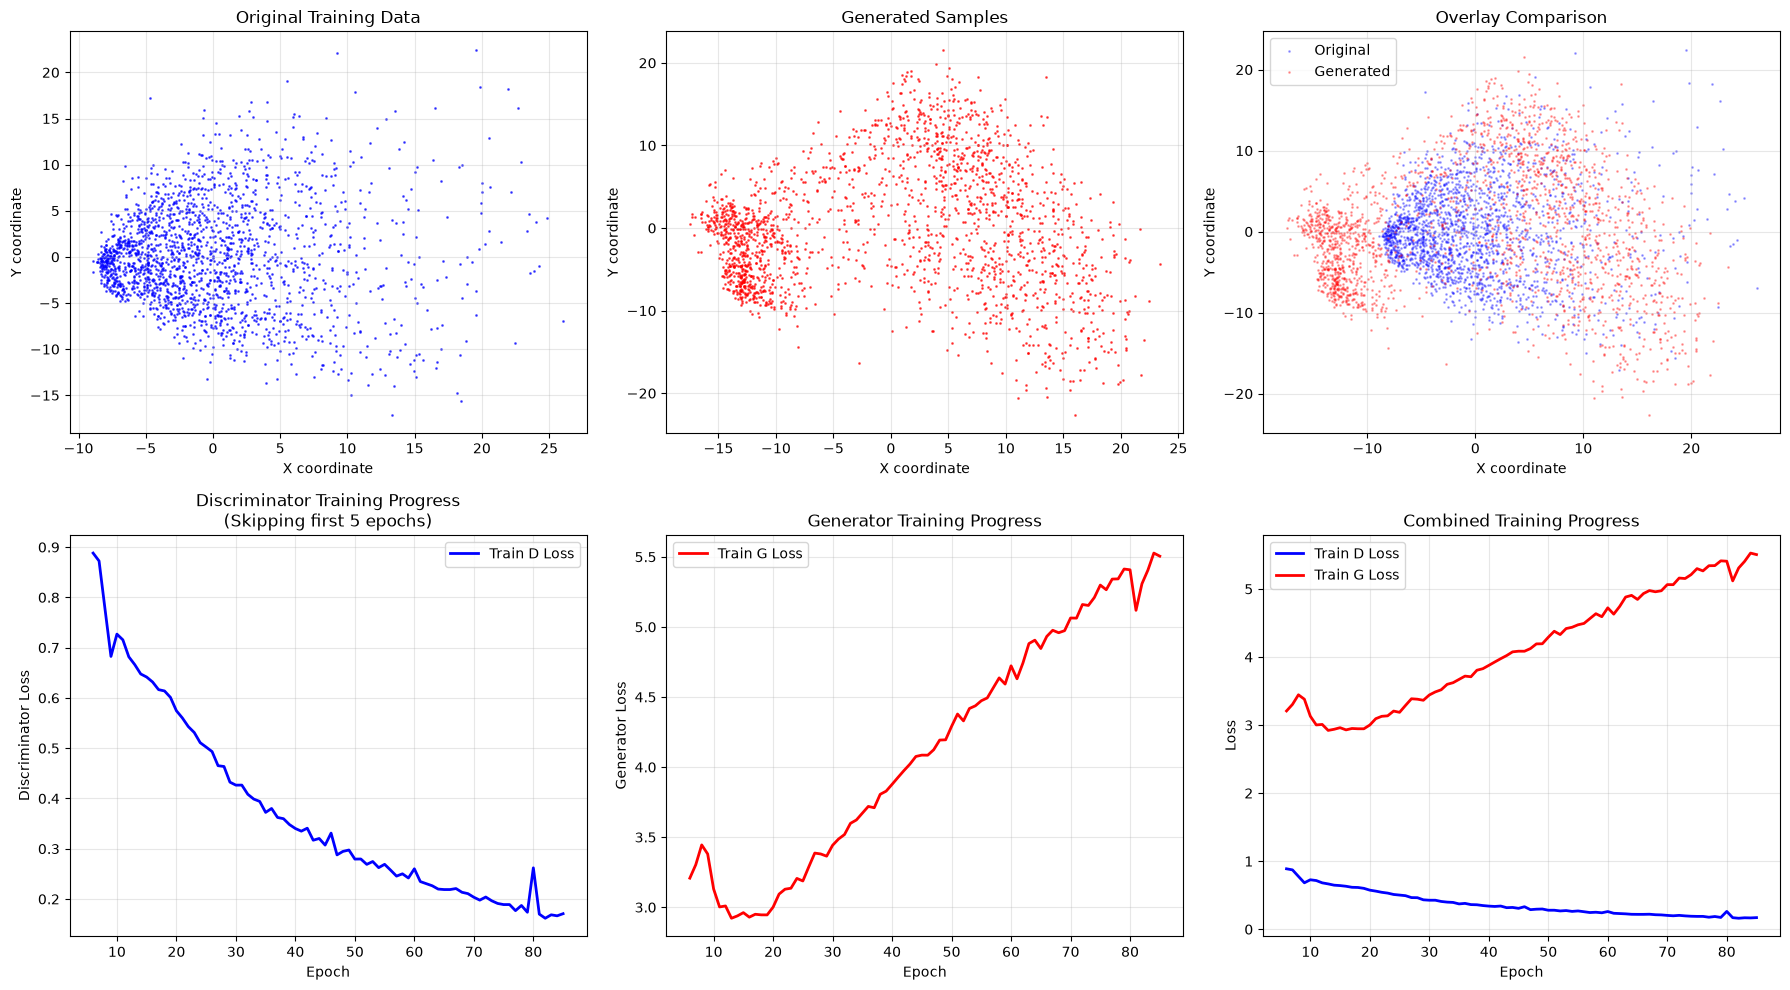

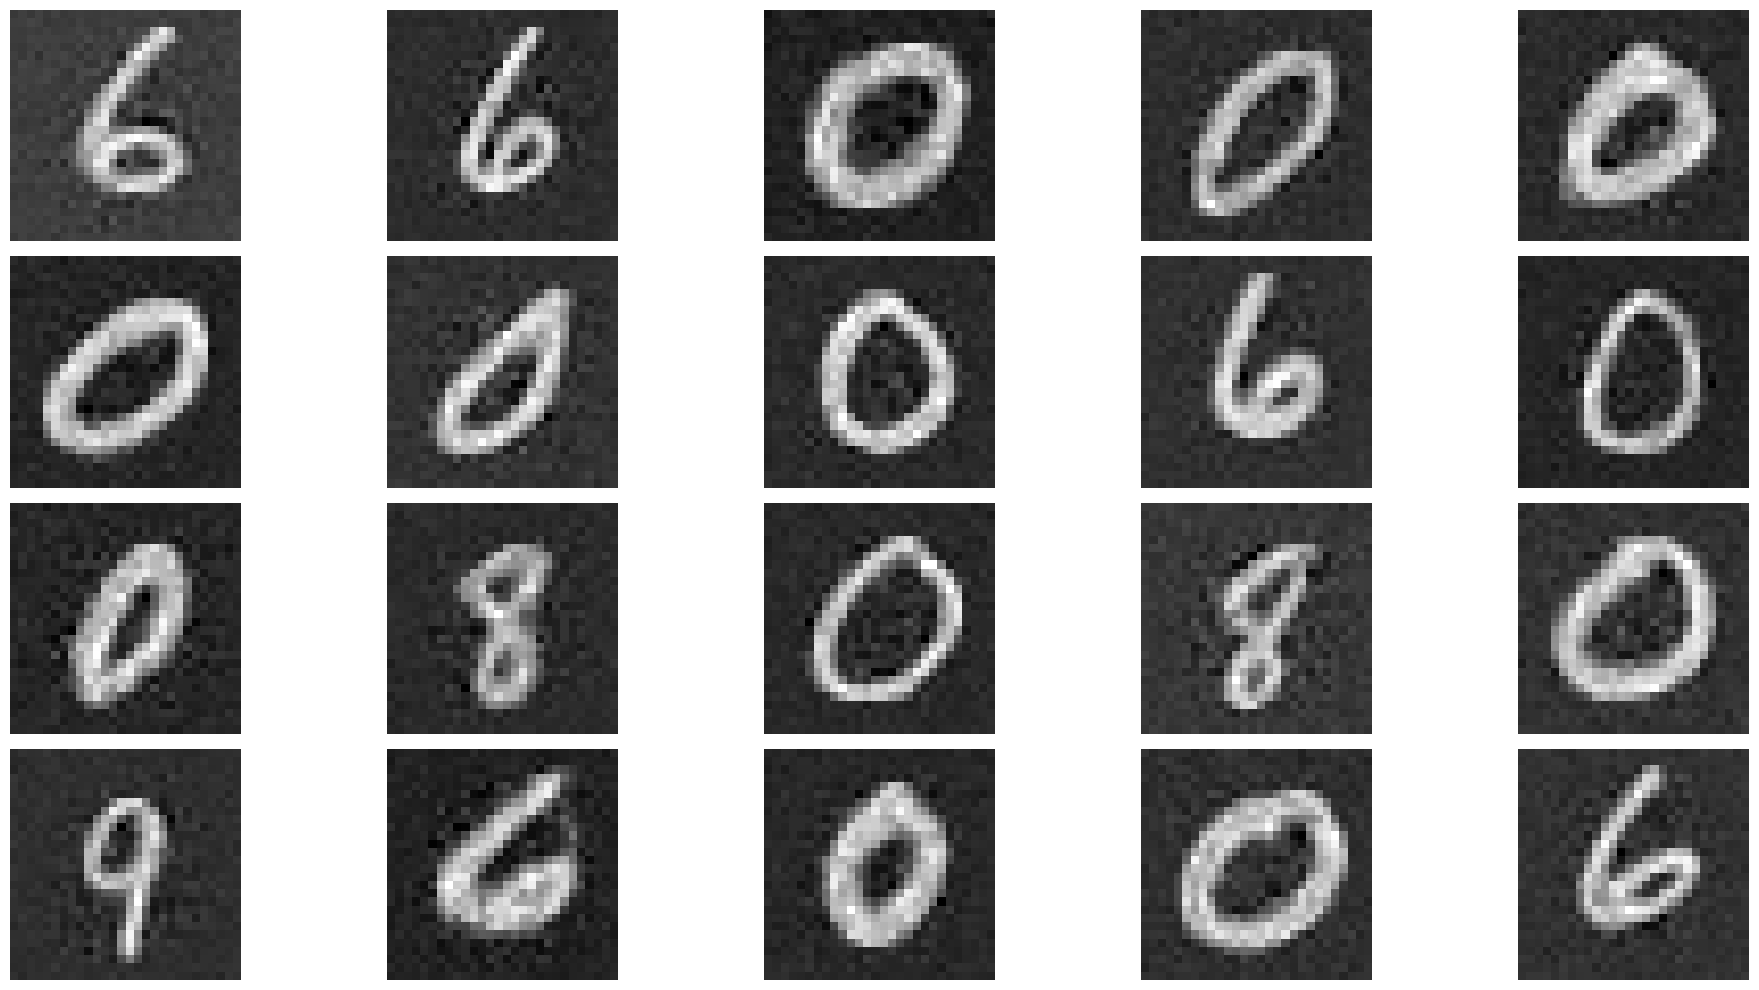

📈 Epoch 85 Summary:
   Train D Loss: 0.1708, Val D Loss: 0.2769
   Train G Loss: 5.5051, Val G Loss: 3.7220

📊 Epoch 86/100
----------------------------------------
Epoch: 86 [0/60000 (0%)]	D_loss: 0.161547	G_loss: 5.395041
Epoch: 86 [6400/60000 (11%)]	D_loss: 0.281669	G_loss: 8.942919
Epoch: 86 [12800/60000 (21%)]	D_loss: 0.087758	G_loss: 4.958993
Epoch: 86 [19200/60000 (32%)]	D_loss: 0.100826	G_loss: 5.688593
Epoch: 86 [25600/60000 (43%)]	D_loss: 0.253564	G_loss: 6.701591
Epoch: 86 [32000/60000 (53%)]	D_loss: 0.077206	G_loss: 6.268447
Epoch: 86 [38400/60000 (64%)]	D_loss: 0.242978	G_loss: 5.898853
Epoch: 86 [44800/60000 (75%)]	D_loss: 0.061254	G_loss: 5.602657
Epoch: 86 [51200/60000 (85%)]	D_loss: 0.148942	G_loss: 5.680192
Epoch: 86 [57600/60000 (96%)]	D_loss: 0.376907	G_loss: 5.161313
====> Epoch: 86 Train D_loss: 0.1515, Train G_loss: 5.6452
====> Epoch: 86 Val D_loss: 0.2786, Val G_loss: 4.4641
📈 Epoch 86 Summary:
   Train D Loss: 0.1515, Val D Loss: 0.2786
   Train G Loss: 5.6452

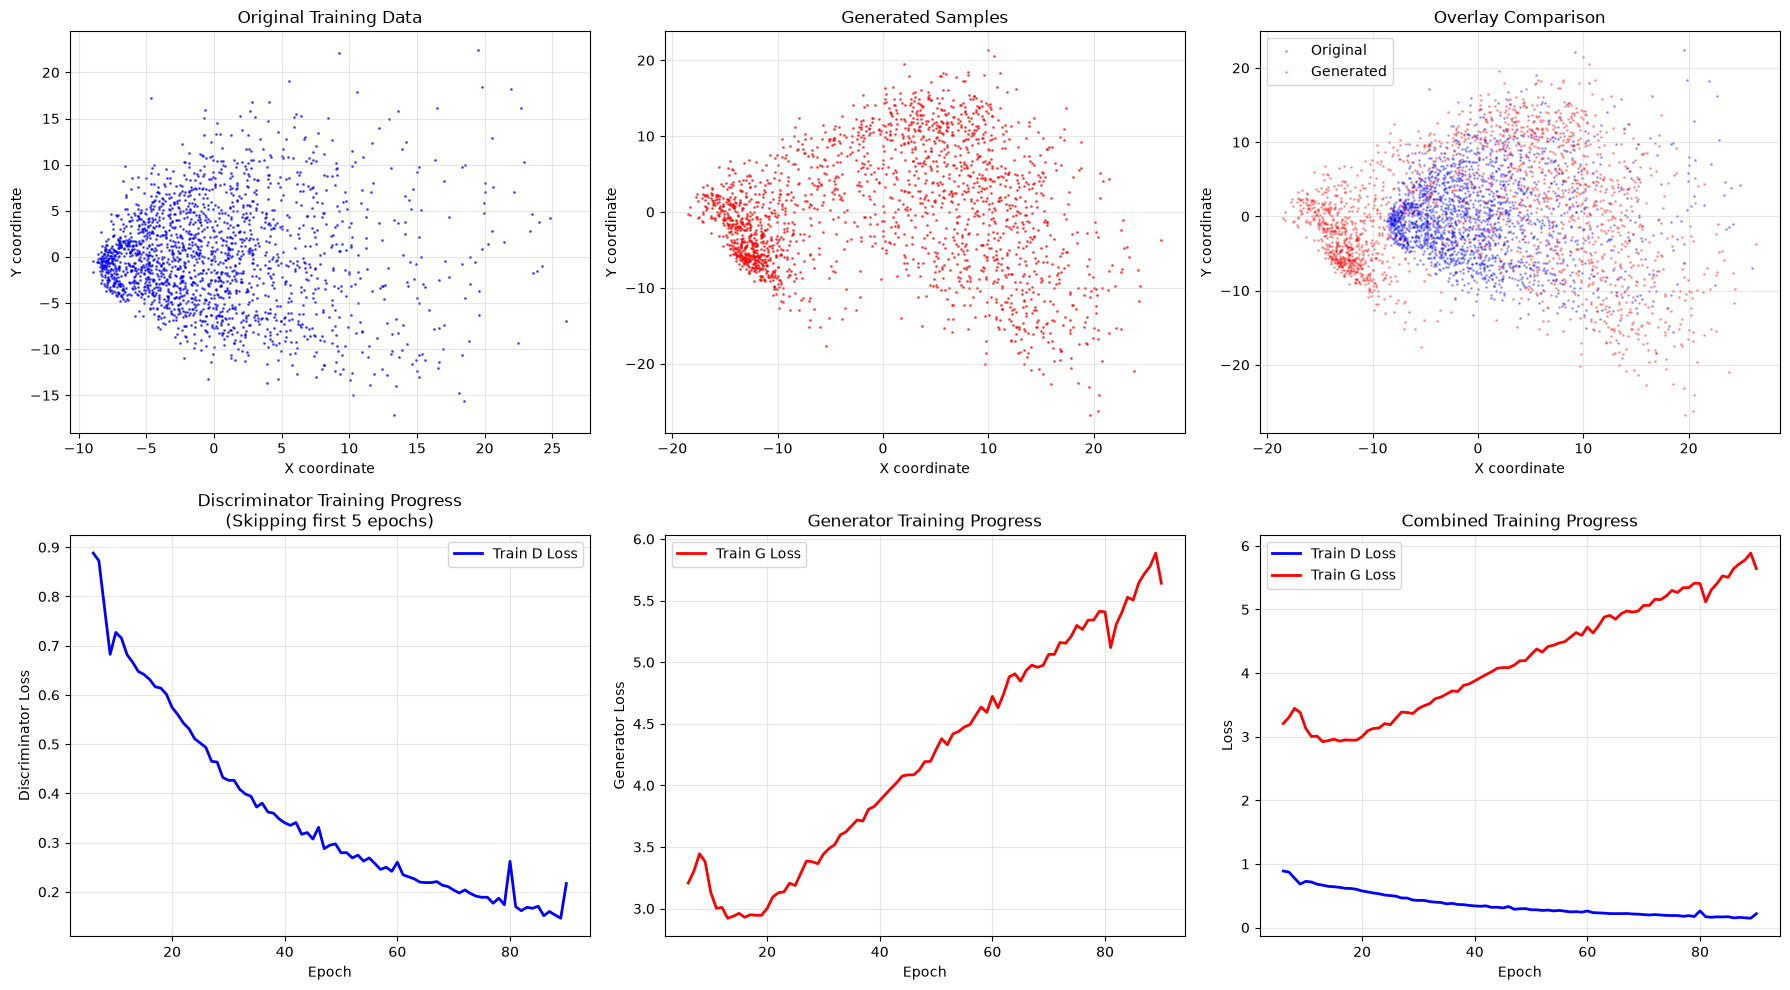

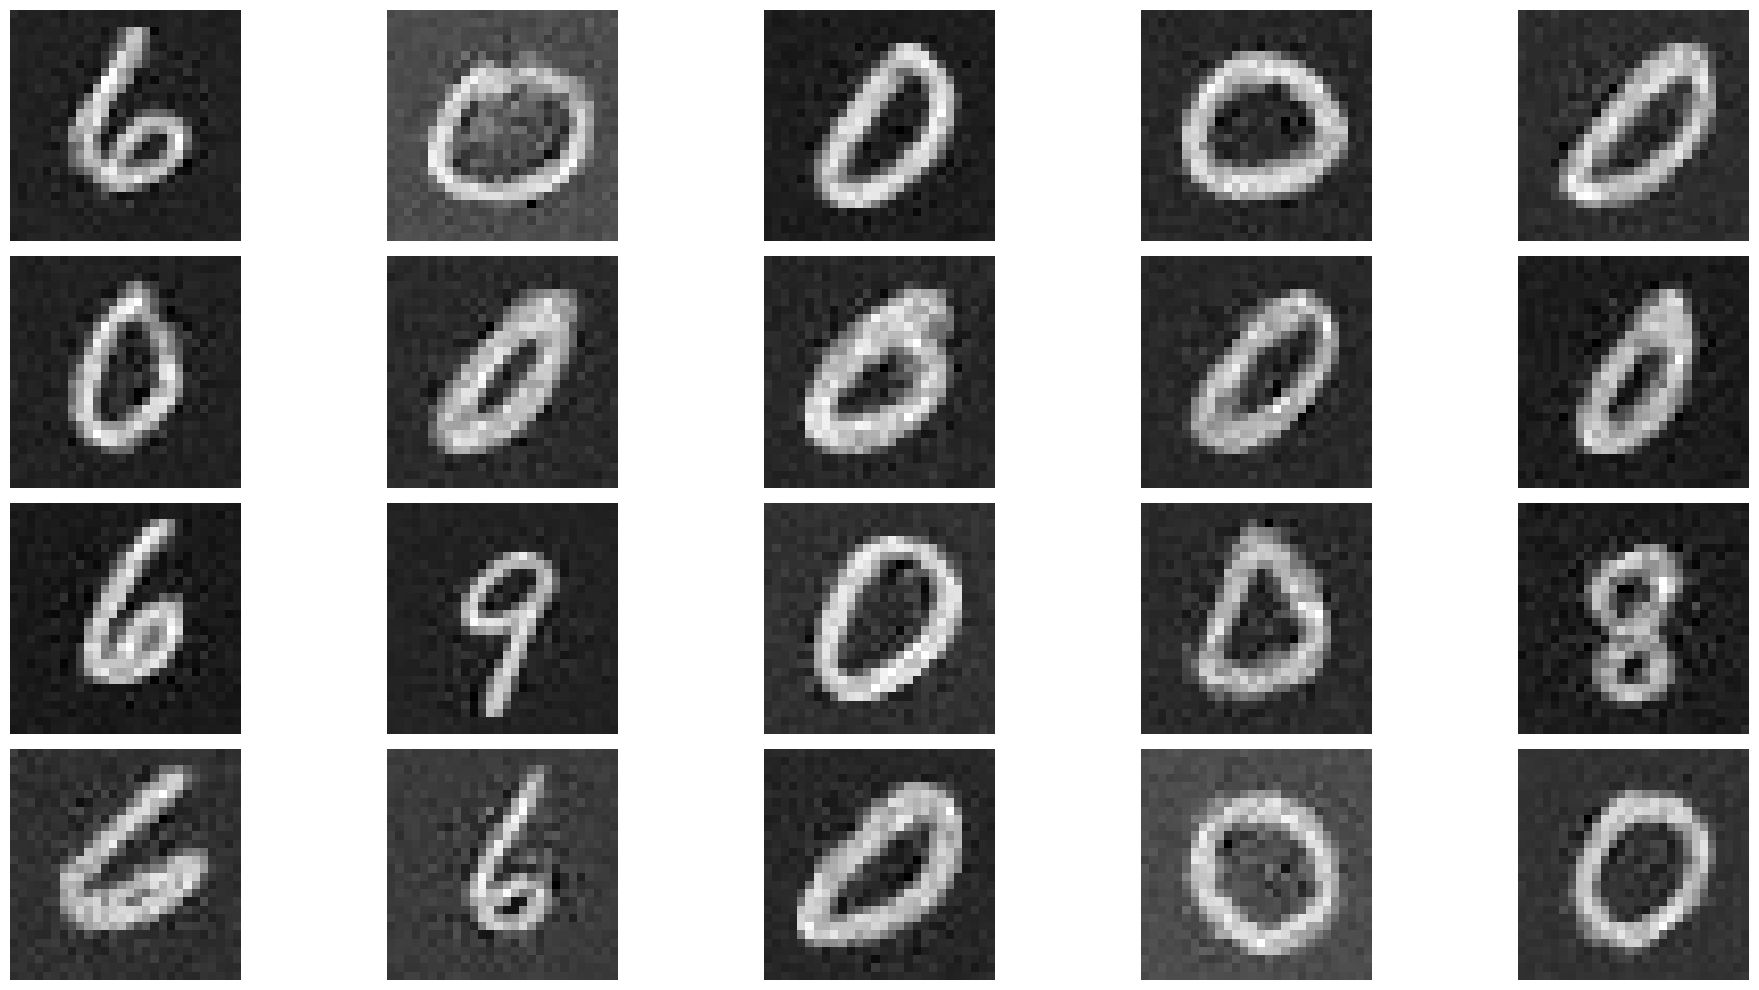

📈 Epoch 90 Summary:
   Train D Loss: 0.2168, Val D Loss: 0.3710
   Train G Loss: 5.6410, Val G Loss: 3.7375

📊 Epoch 91/100
----------------------------------------
Epoch: 91 [0/60000 (0%)]	D_loss: 0.143639	G_loss: 6.361519
Epoch: 91 [6400/60000 (11%)]	D_loss: 0.216307	G_loss: 9.615888
Epoch: 91 [12800/60000 (21%)]	D_loss: 0.179872	G_loss: 4.725223
Epoch: 91 [19200/60000 (32%)]	D_loss: 0.093116	G_loss: 4.938894
Epoch: 91 [25600/60000 (43%)]	D_loss: 0.125083	G_loss: 6.634975
Epoch: 91 [32000/60000 (53%)]	D_loss: 0.140229	G_loss: 5.708765
Epoch: 91 [38400/60000 (64%)]	D_loss: 0.230847	G_loss: 4.463312
Epoch: 91 [44800/60000 (75%)]	D_loss: 0.092899	G_loss: 6.729117
Epoch: 91 [51200/60000 (85%)]	D_loss: 0.117307	G_loss: 5.550732
Epoch: 91 [57600/60000 (96%)]	D_loss: 0.185827	G_loss: 5.550036
====> Epoch: 91 Train D_loss: 0.1317, Train G_loss: 5.8345
====> Epoch: 91 Val D_loss: 0.2993, Val G_loss: 5.2948
📈 Epoch 91 Summary:
   Train D Loss: 0.1317, Val D Loss: 0.2993
   Train G Loss: 5.8345

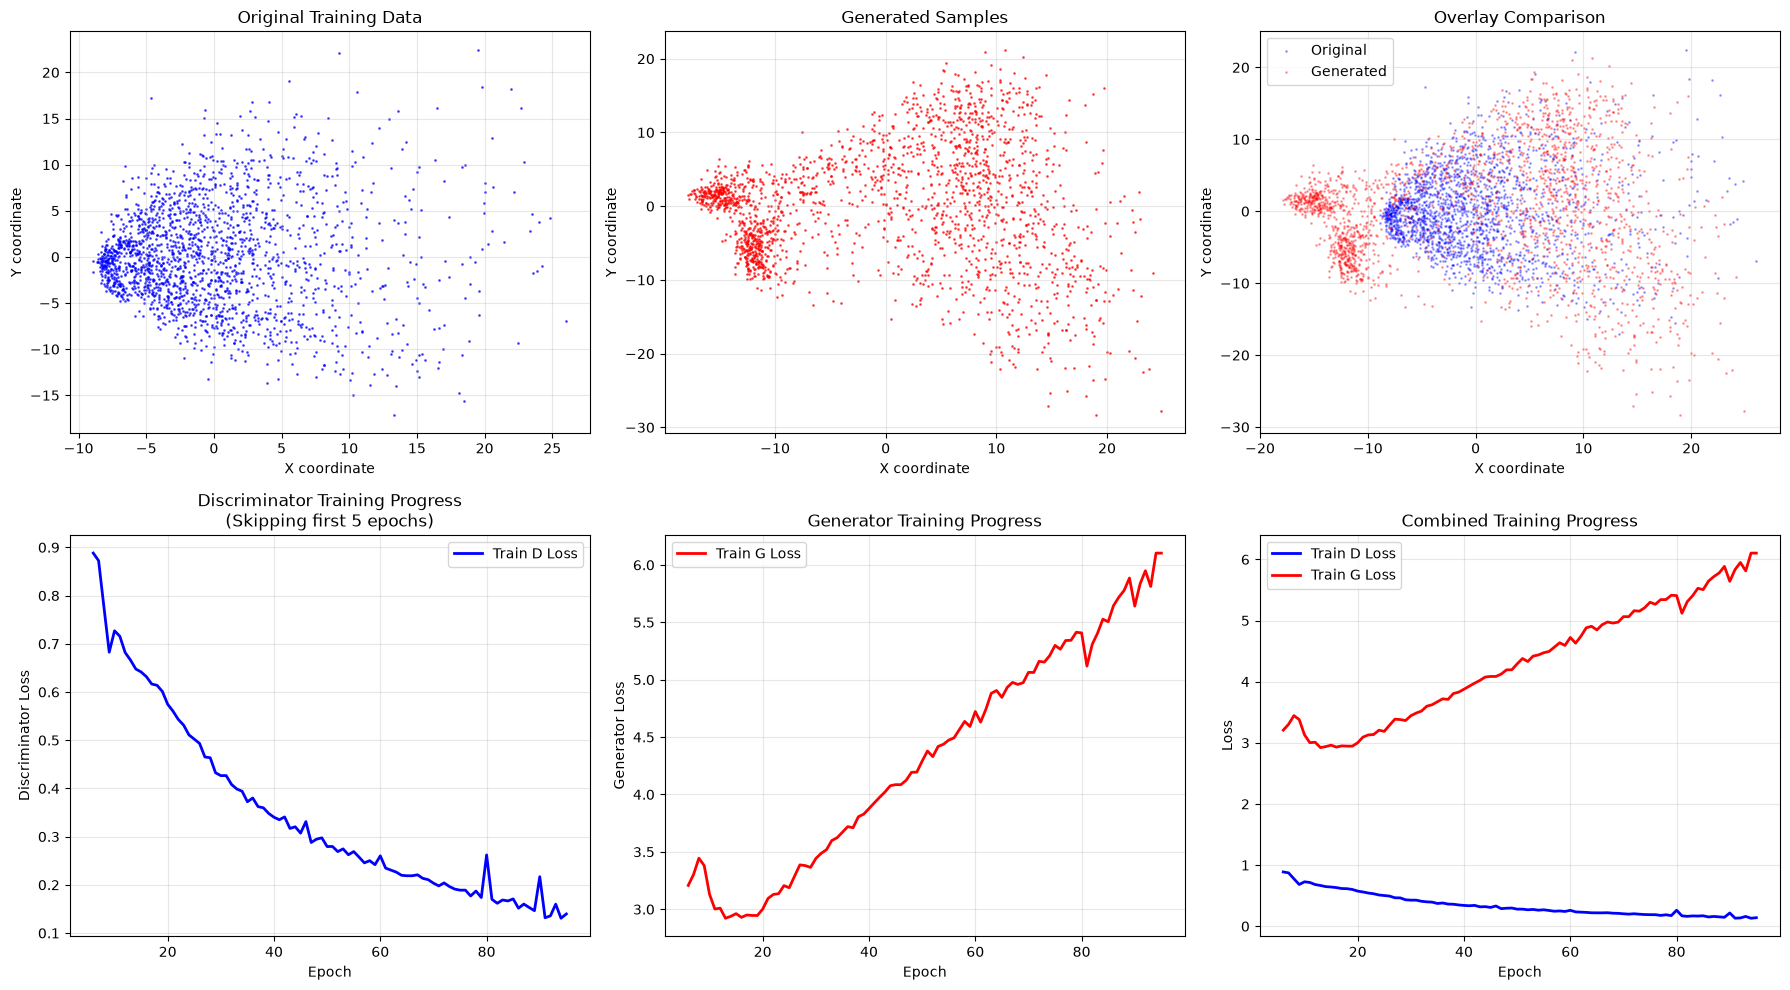

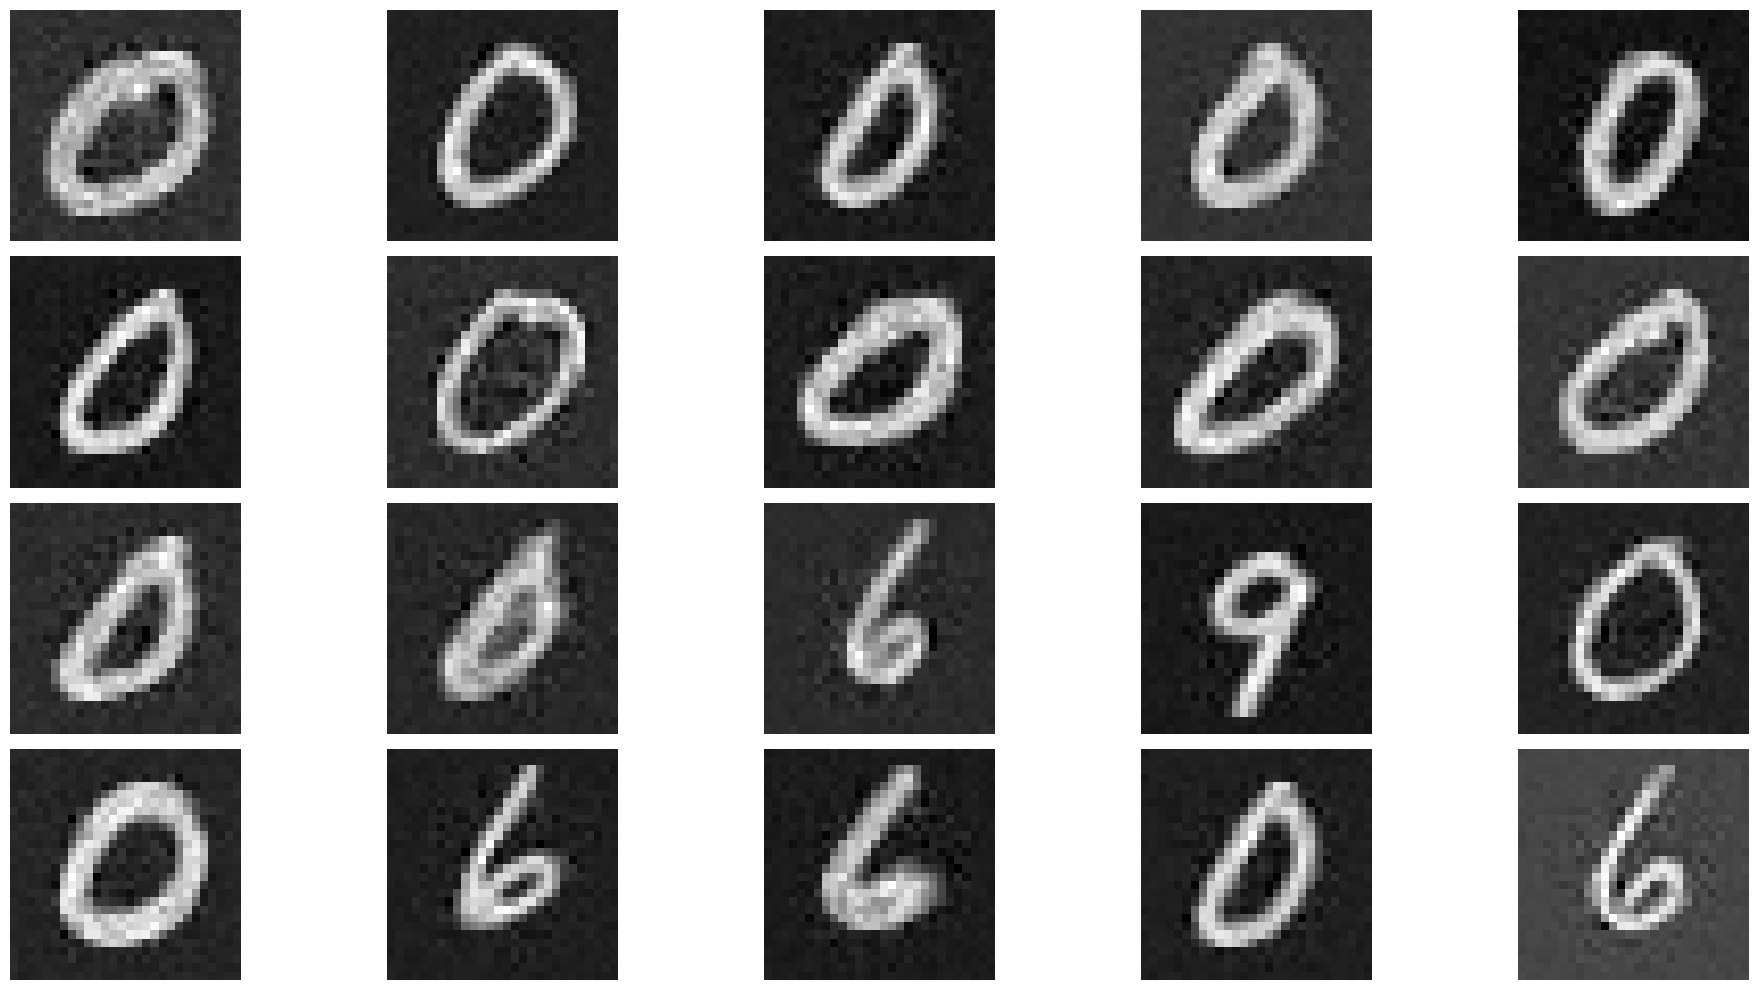

📈 Epoch 95 Summary:
   Train D Loss: 0.1396, Val D Loss: 0.2802
   Train G Loss: 6.1027, Val G Loss: 3.9130

📊 Epoch 96/100
----------------------------------------
Epoch: 96 [0/60000 (0%)]	D_loss: 0.176979	G_loss: 6.855046
Epoch: 96 [6400/60000 (11%)]	D_loss: 0.230914	G_loss: 7.509275
Epoch: 96 [12800/60000 (21%)]	D_loss: 0.198003	G_loss: 5.387091
Epoch: 96 [19200/60000 (32%)]	D_loss: 0.182422	G_loss: 5.979860
Epoch: 96 [25600/60000 (43%)]	D_loss: 0.066576	G_loss: 5.624342
Epoch: 96 [32000/60000 (53%)]	D_loss: 0.097963	G_loss: 6.601861
Epoch: 96 [38400/60000 (64%)]	D_loss: 0.077650	G_loss: 6.629729
Epoch: 96 [44800/60000 (75%)]	D_loss: 0.206728	G_loss: 8.329998
Epoch: 96 [51200/60000 (85%)]	D_loss: 0.453024	G_loss: 2.271593
Epoch: 96 [57600/60000 (96%)]	D_loss: 0.211713	G_loss: 4.568139
====> Epoch: 96 Train D_loss: 0.3824, Train G_loss: 6.0666
====> Epoch: 96 Val D_loss: 0.4267, Val G_loss: 5.2816
📈 Epoch 96 Summary:
   Train D Loss: 0.3824, Val D Loss: 0.4267
   Train G Loss: 6.0666

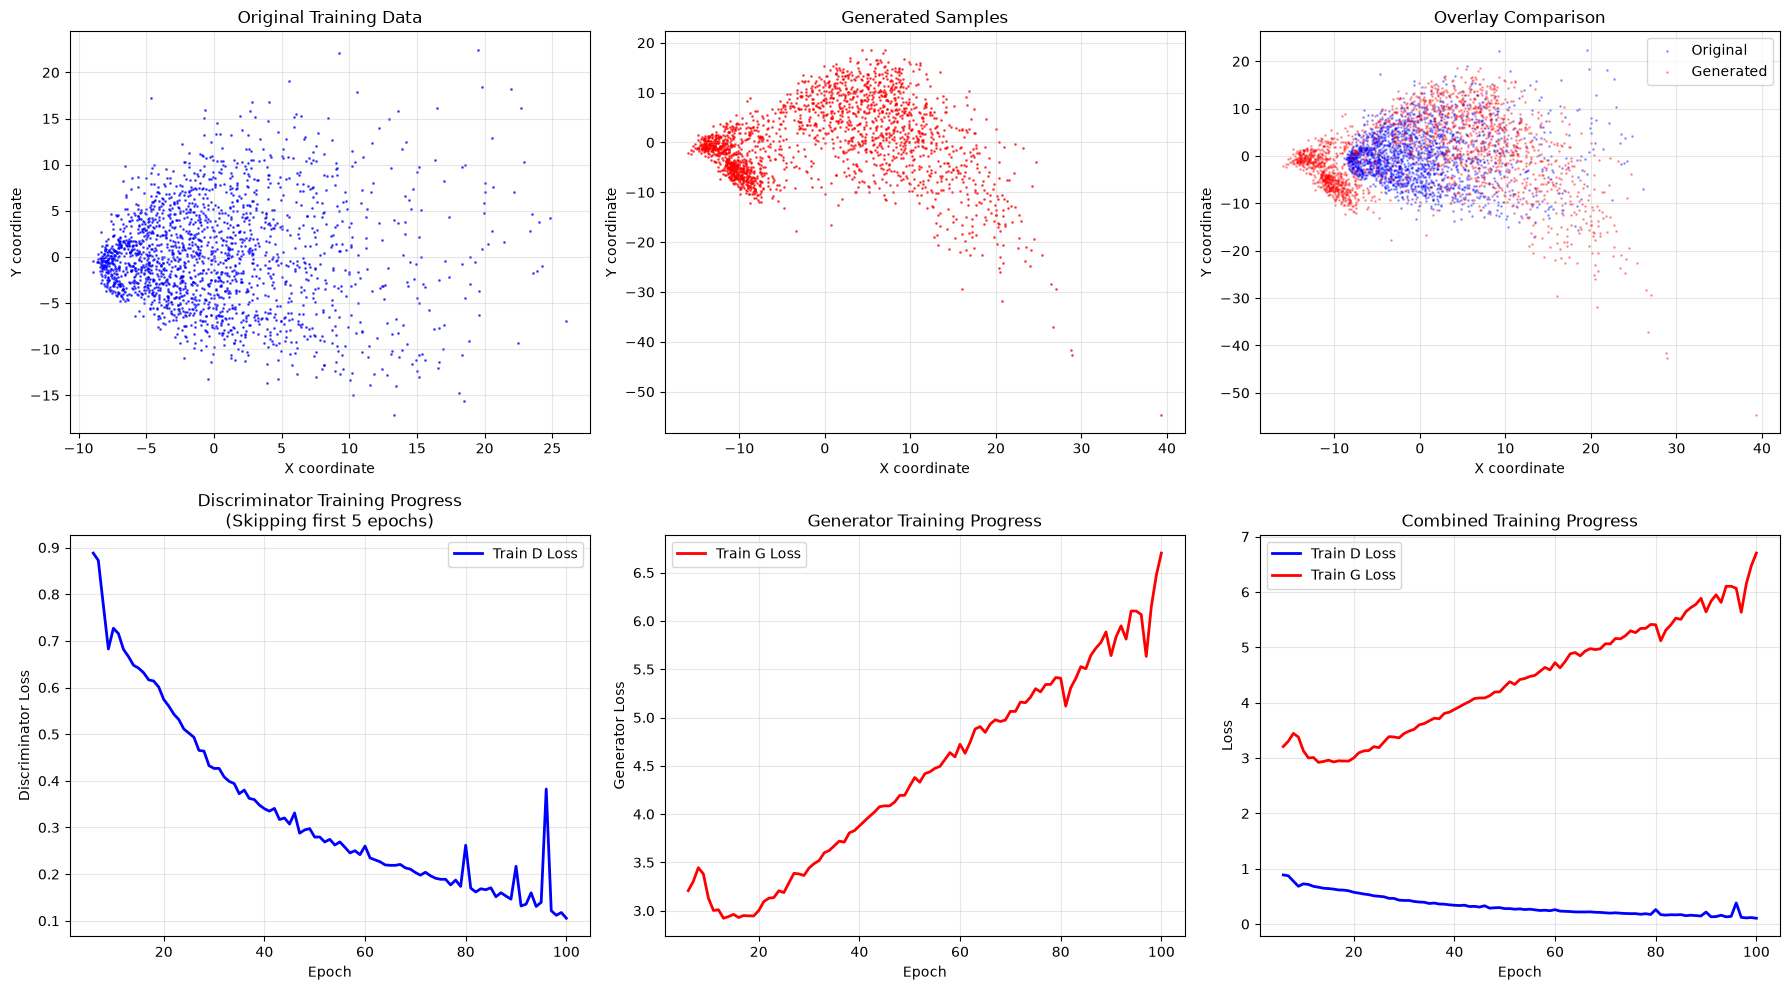

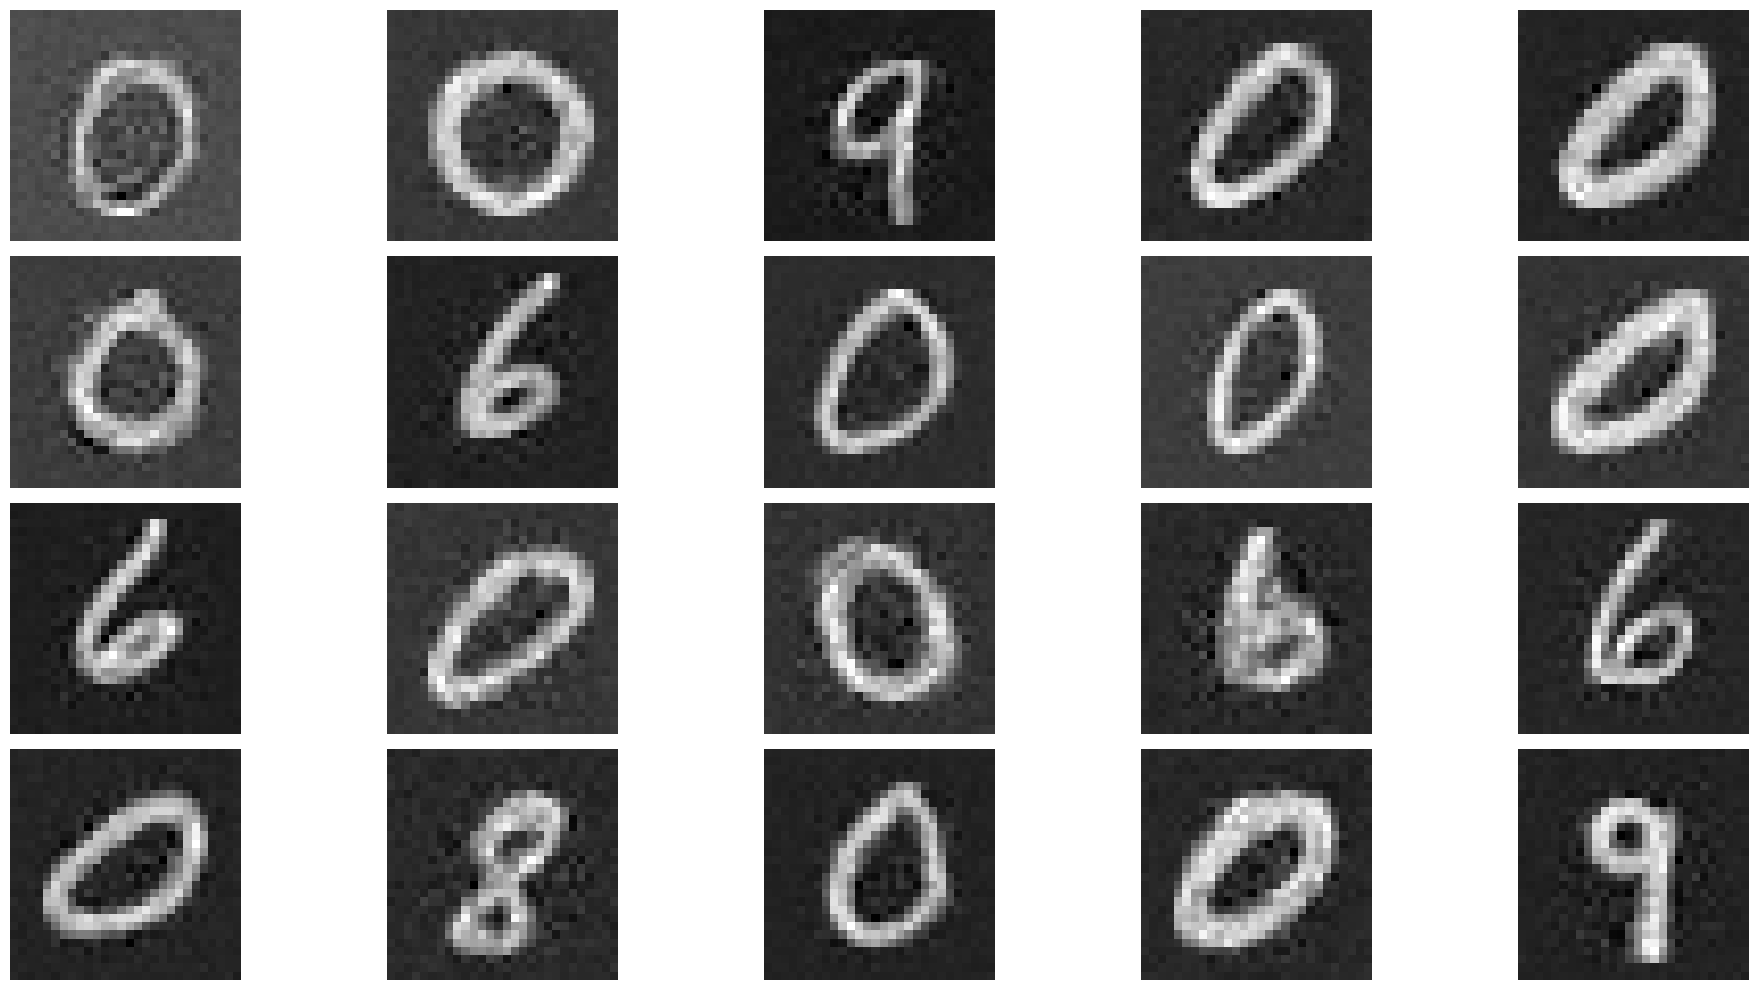

📈 Epoch 100 Summary:
   Train D Loss: 0.1055, Val D Loss: 0.3258
   Train G Loss: 6.7025, Val G Loss: 5.1932

🎉 Training completed!

🎨 Final comprehensive visualization:


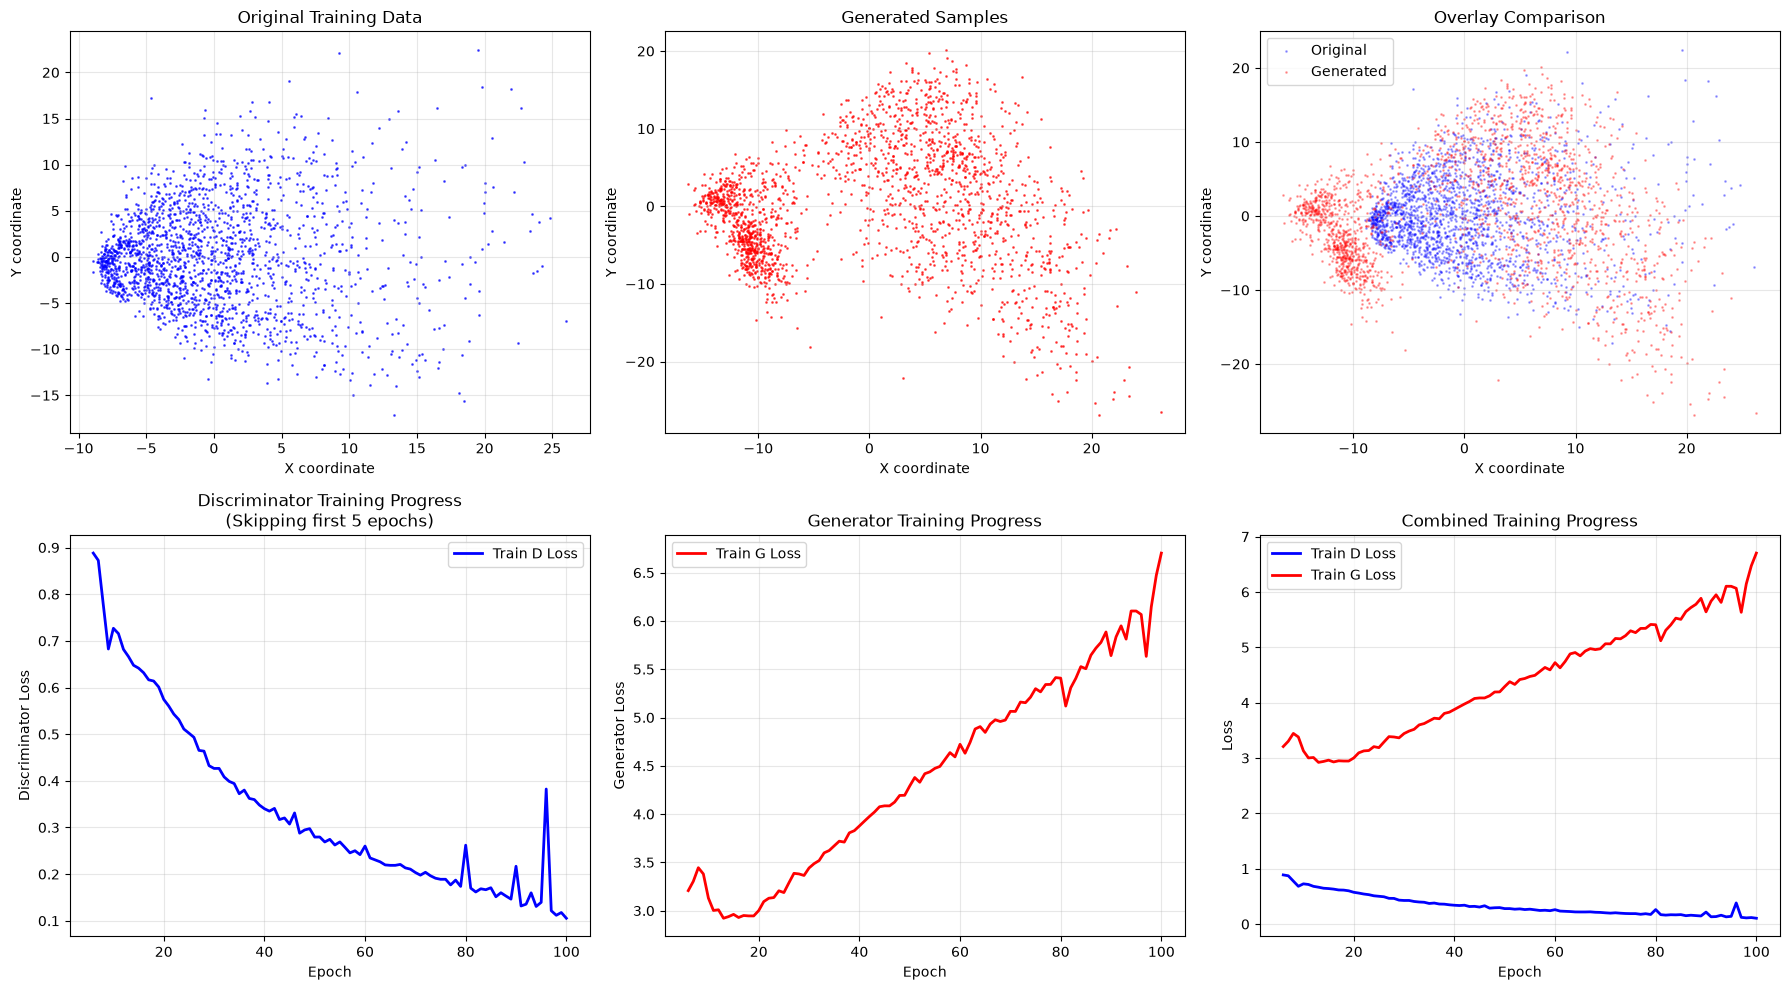

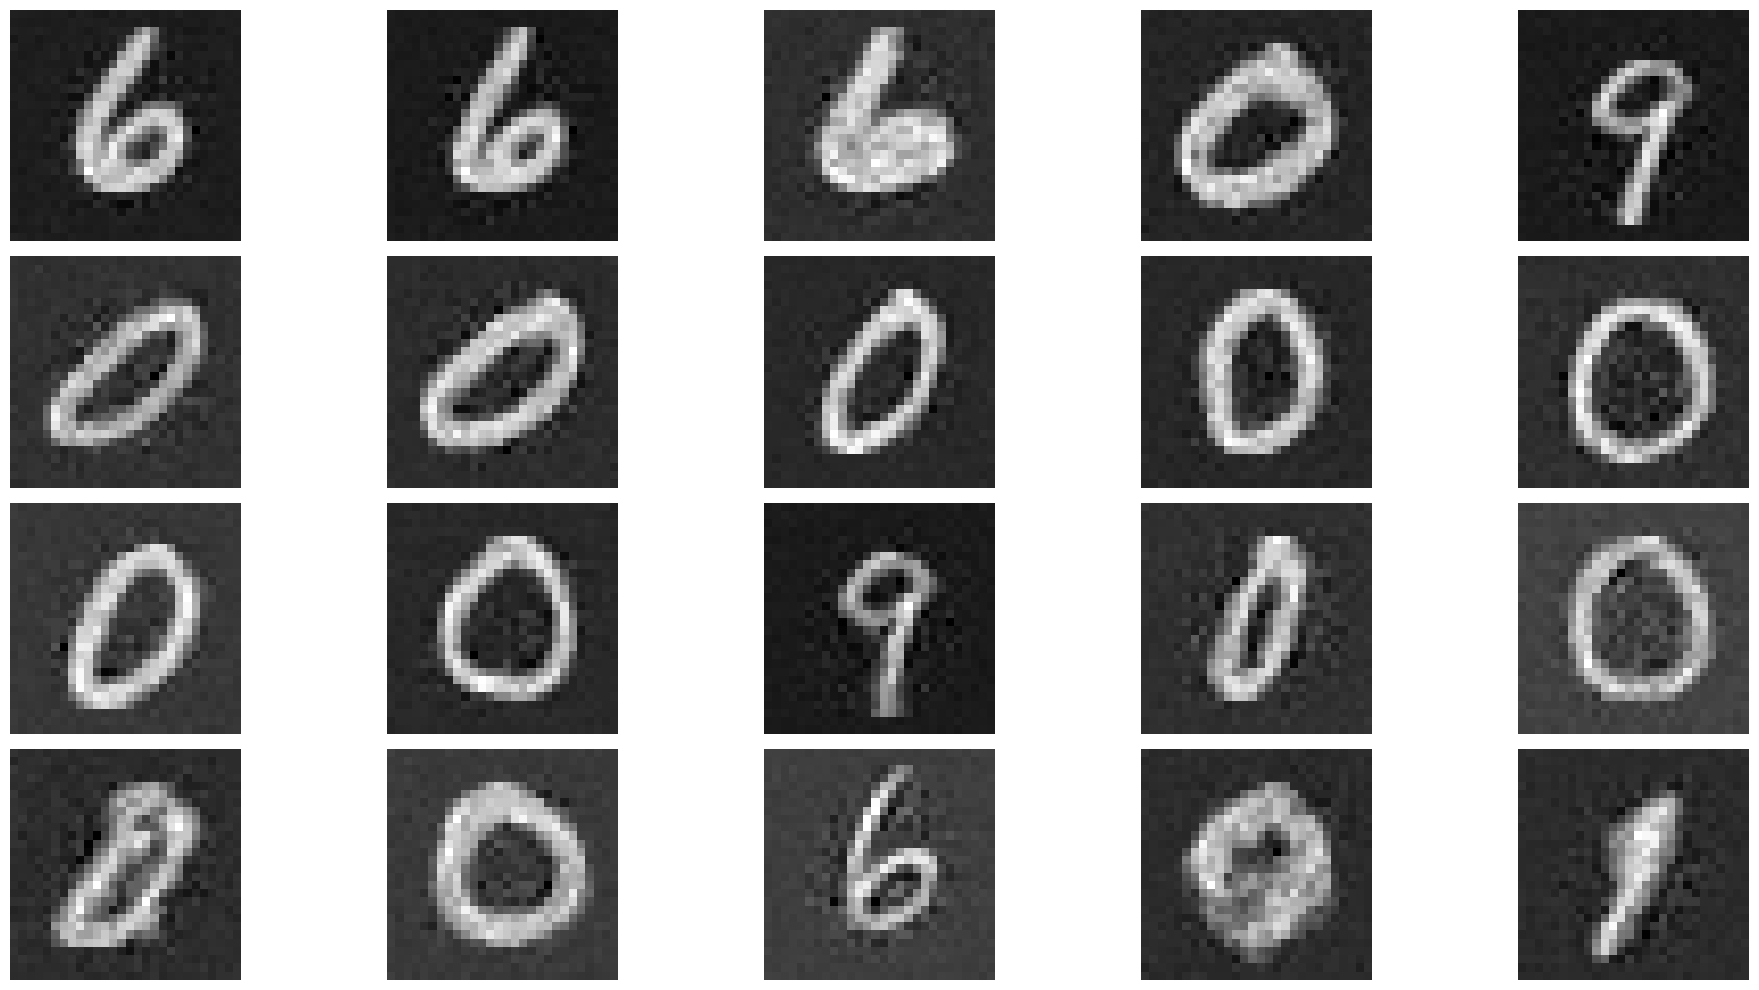

In [14]:
# Training loop
print("🎯 Starting GAN training...")
print("=" * 60)

# Lists to track training progress
train_d_losses = []
train_g_losses = []
val_d_losses = []
val_g_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch with validation
    train_d_loss, train_g_loss, val_d_loss, val_g_loss = train_epoch_with_validation(epoch)
    
    # Track losses
    train_d_losses.append(train_d_loss)
    train_g_losses.append(train_g_loss)
    val_d_losses.append(val_d_loss)
    val_g_losses.append(val_g_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Train D Loss: {train_d_loss:.4f}, Val D Loss: {val_d_loss:.4f}")
    print(f"   Train G Loss: {train_g_loss:.4f}, Val G Loss: {val_g_loss:.4f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained models
# torch.save(generator.state_dict(), 'generator.pth')
# torch.save(discriminator.state_dict(), 'discriminator.pth')
# print("💾 Models saved as 'generator.pth' and 'discriminator.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, train_d_losses, train_g_losses, val_d_losses, val_g_losses)


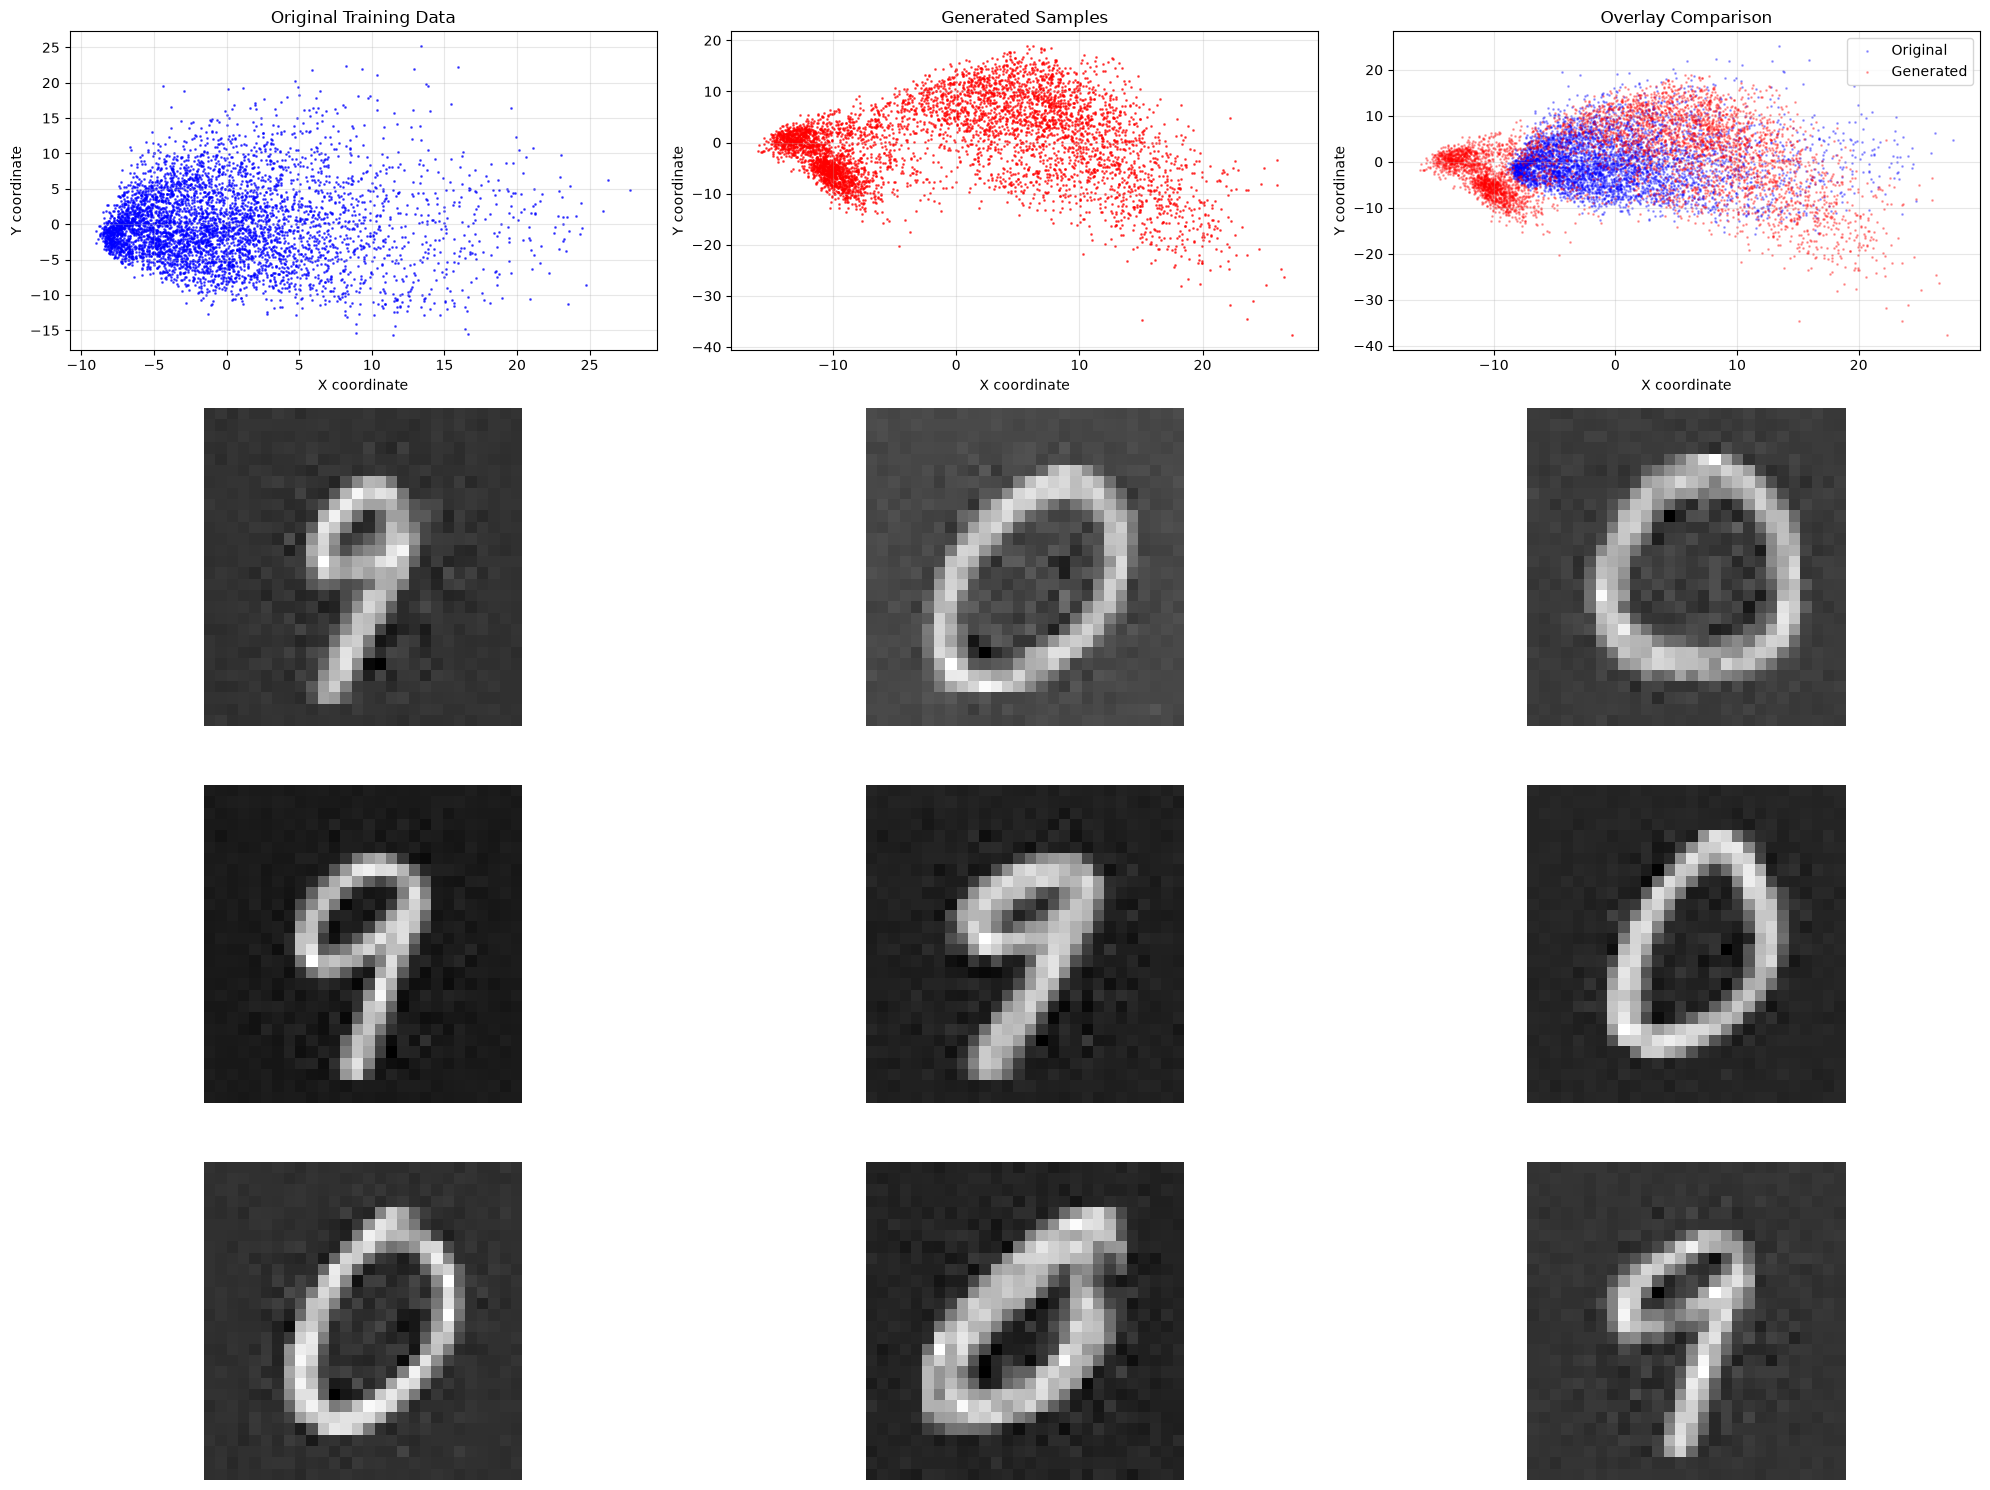

Real data confidence: 0.026
Fake data confidence: 0.061


In [15]:
# Generate a large number of samples
generated_samples = generate_samples(5000)

# Create comprehensive visualization
plt.figure(figsize=(20, 15))

train_data_reshaped = np.reshape(train_data.data[:5000], [5000, INPUT_DIM])
data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
x_transformed = pca_fit(generated_samples).transform(generated_samples)

# Original training data
plt.subplot(4, 3, 1)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
plt.title('Original Training Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Generated samples
plt.subplot(4, 3, 2)
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
plt.title('Generated Samples')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Overlay comparison
plt.subplot(4, 3, 3)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
plt.title('Overlay Comparison')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.legend()
plt.grid(True, alpha=0.3)


for i in range(9):
    plt.subplot(4, 3, 3 + i + 1)
    plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()


generator.eval()
discriminator.eval()
with torch.no_grad():
    # Test on real data
    real_batch = train_data.data[:100].to(device).float()
    real_batch = real_batch.reshape([100, INPUT_DIM])
    real_pred = discriminator(real_batch).mean().item()

    # Test on fake data
    noise = torch.randn(100, NOISE_DIM).to(device)
    fake_batch = generator(noise)
    fake_pred = discriminator(fake_batch).mean().item()

print(f'Real data confidence: {real_pred:.3f}')
print(f'Fake data confidence: {fake_pred:.3f}')
